# **KM6312 Information Mining and Analysis**
# From COE market dynamics to EV adoption: A predictive study of Singapore’s vehicle market

**Prepared by:** <br>
Alvin Lu Tze Chinn (G2502948H)<br>
Cheng TongTong (G2026900A)<br>
Gerald Ng Ghim Yap (G2506566C)<br>
Junia Rin Low Shu Jun (G2506488B)<br>
Teo Chek Yew (G2611581K) <br>

**Group 1**<br>
21 November 2026 <br>

-------

The outcome is the fully electric share of new car registrations.<br>
Sections 1–7 cover data collection, preparation, variable construction and validation of the monthly analytical dataset.<br>
Section 8 describes the market. <br>
Section 9 defines the shared evaluation design.<br>
Sections 10–18 bring together regression specifications, chronological evaluation, robustness checks and autoregressive models, with Holt as a separate smoothing comparator.<br>
Section 19 examines tree models; Section 20 consolidates model comparisons.<br>
Section 21 summarises findings and limitations. <br>
Appendices A–D retain supporting tests, numerical checks and illustrative projections.<br>

**How to run:**  Restart the Python kernel and Run All. The default uses the verified monthly dataset embedded here; no CSV, API access or manual path change is needed.

To rebuild from source: Set REBUILD_FROM_LTA = True below and run from the beginning. 
This optional route uses the source discovery, extraction, transformation and export pipeline.

In [1]:
import io
import numpy as np
import pandas as pd
from IPython.display import display

REBUILD_FROM_LTA = False
STUDY_START = pd.Timestamp("2016-01-01")
ANALYSIS_END = pd.Timestamp("2026-08-01")
EV_CLASSIFICATION_START = pd.Timestamp("2022-07-01")
pd.set_option("display.max_columns", 50)

## Sections 1–7 · Build the monthly dataset
The optional source pipeline discovers LTA archives, selects CSVs by schema, aggregates the series by month and joins them onto the study calendar. The embedded dataset preserves the same registration definitions, COE suspension gaps and target start date. Both routes feed the same `model_df` into every analysis.

In [2]:
def rebuild_monthly_dataset():
    # ============================================================
    # SECTION 1: IMPORTS, SETTINGS AND OUTPUT FOLDERS
    # ============================================================
    # One-time setup only if needed; restart the kernel after installation.
    # %pip install --upgrade "statsmodels>=0.14.6"

    from pathlib import Path
    from html.parser import HTMLParser
    from urllib.parse import urljoin
    from difflib import SequenceMatcher

    import io
    import re
    import time
    import zipfile

    import numpy as np
    import pandas as pd
    import requests

    pd.set_option("display.max_columns", 50)
    pd.set_option("display.width", 180)

    STUDY_START = pd.Timestamp("2016-01-01")
    ANALYSIS_END = pd.Timestamp("2026-08-01")   # Last month included in the study
    EV_CLASSIFICATION_START = pd.Timestamp("2022-07-01")

    OUTPUT_DIR = Path("km6312_output_datamall")
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    WORKBOOK_OUTPUT = OUTPUT_DIR / "KM6312_Group1_Data_DataMall.xlsx"
    CSV_OUTPUT = OUTPUT_DIR / "KM6312_Model_Ready_Monthly_DataMall.csv"

    CATALOG_URLS = [
        "https://datamall.lta.gov.sg/content/datamall/en/search_datasets.html",
        "https://datamall.lta.gov.sg/content/datamall/en/static-data.html",
    ]

    session = requests.Session()
    session.headers.update({
        "User-Agent": (
            "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
            "AppleWebKit/537.36 Chrome/120 Safari/537.36"
        )
    })

    print("Study frame:", STUDY_START.strftime("%Y-%m"), "to", ANALYSIS_END.strftime("%Y-%m"))
    print("Output folder:", OUTPUT_DIR.resolve())


    # ============================================================
    # SECTION 2: KEYWORD-BASED DATASET DISCOVERY FROM LTA DATAMALL
    # ============================================================

    # Research concepts guide discovery; final dataset URLs are not hardcoded.
    DISCOVERY_PLAN = {
        "ev_registration":       ("monthly new registration cars make", "Core outcome source"),
        "coe_archive":           ("coe bidding results", "Core predictor source"),
        "vehicle_population_vqs":("monthly vehicle population quota categories", "Context predictor"),
        "vehicle_population_type":("monthly vehicle population vehicle type", "Context predictor"),
        "vehicle_population_fuel":("monthly vehicle population fuel used", "Supplementary EV-adoption measure"),
    }


    class DataMallCatalogueParser(HTMLParser):
        """Associate each catalogue heading with its ZIP link(s) and metadata."""

        HEADINGS = {"h2", "h3", "h4", "h5", "h6"}

        def __init__(self, base_url):
            super().__init__()
            self.base_url = base_url
            self.entries = []
            self.title = None
            self.text_parts = []
            self.zip_links = []
            self.in_heading = False
            self.heading_parts = []
            self.active_href = None

        def _flush(self):
            if self.title and self.zip_links:
                block = re.sub(r"\s+", " ", " ".join(self.text_parts)).strip()
                frequency = re.search(r"Frequency:\s*([A-Za-z-]+)", block, re.I)
                last_update = re.search(r"Last\s+Update:\s*([A-Za-z]{3}\s+\d{4}|-)", block, re.I)

                for href in self.zip_links:
                    self.entries.append({
                        "title": self.title,
                        "archive_url": urljoin(self.base_url, href),
                        "frequency": frequency.group(1) if frequency else None,
                        "last_update": last_update.group(1) if last_update else None,
                        "catalogue_page": self.base_url,
                    })

            self.text_parts, self.zip_links = [], []

        def handle_starttag(self, tag, attrs):
            tag = tag.lower()
            if tag in self.HEADINGS:
                self._flush()
                self.in_heading, self.heading_parts = True, []
            elif tag == "a":
                self.active_href = dict(attrs).get("href")

        def handle_data(self, data):
            if self.in_heading:
                self.heading_parts.append(data)
            elif self.title:
                self.text_parts.append(data)

        def handle_endtag(self, tag):
            tag = tag.lower()
            if tag in self.HEADINGS and self.in_heading:
                self.title = re.sub(r"\s+", " ", " ".join(self.heading_parts)).strip()
                self.in_heading = False
            elif tag == "a":
                if self.active_href and ".zip" in self.active_href.lower():
                    self.zip_links.append(self.active_href)
                self.active_href = None

        def close(self):
            super().close()
            self._flush()


    def get_with_retry(url, retries=4, timeout=60):
        """HTTP GET with short exponential backoff."""
        last_error = None
        for attempt in range(retries):
            try:
                response = session.get(url, timeout=timeout)
                response.raise_for_status()
                return response
            except Exception as exc:
                last_error = exc
                if attempt < retries - 1:
                    time.sleep(2 ** attempt)
        raise RuntimeError(f"Failed to retrieve: {url}") from last_error


    def fetch_catalogue():
        entries, errors = [], []
        for url in CATALOG_URLS:
            try:
                parser = DataMallCatalogueParser(url)
                parser.feed(get_with_retry(url).text)
                parser.close()
                entries.extend(parser.entries)
            except Exception as exc:
                errors.append(f"{url}: {exc}")

        if not entries:
            raise RuntimeError("Could not parse LTA DataMall catalogue.\n" + "\n".join(errors))

        return (
            pd.DataFrame(entries)
            .drop_duplicates(["title", "archive_url"])
            .reset_index(drop=True)
        )


    STOPWORDS = {"the", "of", "by", "and", "statistics"}


    def tokens(text):
        words = re.findall(r"[a-z0-9]+", str(text).lower())
        out = []
        for word in words:
            if word in STOPWORDS:
                continue
            if len(word) > 4 and word.endswith("ies"):
                word = word[:-3] + "y"
            elif len(word) > 3 and word.endswith("s") and not word.endswith("ss"):
                word = word[:-1]
            out.append(word)
        return out


    def relevance_score(query, title, frequency=None):
        q, t = tokens(query), tokens(title)
        overlap = len(set(q) & set(t)) / len(set(q)) if q else 0
        similarity = SequenceMatcher(None, " ".join(q), " ".join(t)).ratio()
        frequency_bonus = 0.05 if str(frequency).casefold() == "monthly" else 0
        return 0.80 * overlap + 0.20 * similarity + frequency_bonus


    def discover(catalogue, query, top_n=5):
        ranked = catalogue.copy()
        ranked["score"] = [
            relevance_score(query, title, freq)
            for title, freq in zip(ranked["title"], ranked["frequency"])
        ]
        return ranked.sort_values(["score", "title"], ascending=[False, True]).head(top_n).reset_index(drop=True)


    catalog = fetch_catalogue()
    print("LTA DataMall catalogue entries with ZIP archives:", len(catalog))

    discovery_rows, resolved_sources = [], {}

    for source_key, (query, role) in DISCOVERY_PLAN.items():
        ranked = discover(catalog, query)
        best = ranked.iloc[0]
        runner_up = float(ranked.iloc[1]["score"]) if len(ranked) > 1 else np.nan

        if float(best["score"]) < 0.70:
            raise RuntimeError(f"Low-confidence discovery for '{source_key}': {best['title']}")
        if pd.notna(runner_up) and float(best["score"]) - runner_up < 0.02:
            raise RuntimeError(f"Ambiguous discovery for '{source_key}'. Review candidate ranking.")

        resolved_sources[source_key] = {
            "query": query,
            "role": role,
            "title": best["title"],
            "archive_url": best["archive_url"],
            "frequency": best["frequency"],
            "last_update": best["last_update"],
            "score": float(best["score"]),
        }

        discovery_rows.extend({
            "source_key": source_key,
            "query": query,
            "rank": rank + 1,
            "candidate_title": row["title"],
            "score": float(row["score"]),
            "frequency": row["frequency"],
            "last_update": row["last_update"],
            "selected": rank == 0,
        } for rank, row in ranked.iterrows())

    discovery_audit = pd.DataFrame(discovery_rows)
    selected_sources = pd.DataFrame([
        {
            "source_key": key,
            "query": meta["query"],
            "selected_title": meta["title"],
            "score": meta["score"],
            "frequency": meta["frequency"],
            "last_update": meta["last_update"],
        }
        for key, meta in resolved_sources.items()
    ])

    print("\nKeyword discovery results:")
    display(discovery_audit)
    print("\nSelected LTA DataMall sources:")
    display(selected_sources)


    # ============================================================
    # SECTION 3: RETRIEVE DISCOVERED ARCHIVES + IDENTIFY CSVs BY SCHEMA
    # ============================================================

    # Required schemas express project needs; archive member filenames are discovered.
    ASSET_SPECS = {
        "ev_registration": {
            "source": "ev_registration",
            "columns": {"month", "make", "importer_type", "fuel_type", "vehicle_type", "number"},
            "role": "Core outcome source",
        },
        "coe_bidding": {
            "source": "coe_archive",
            "columns": {"month", "bidding_no", "vehicle_class", "quota", "bids_success", "bids_received", "premium"},
            "role": "Core predictor source",
        },
        "coe_pqp": {
            "source": "coe_archive",
            "columns": {"month", "vehicle_class", "pqp"},
            "role": "Optional COE predictor",
        },
        "vehicle_population_vqs": {
            "source": "vehicle_population_vqs",
            "columns": {"month", "category", "number"},
            "role": "Context predictor",
        },
        "vehicle_population_type": {
            "source": "vehicle_population_type",
            "columns": {"month", "vehicle_type", "number"},
            "role": "Context predictor",
        },
        "vehicle_population_fuel": {
            "source": "vehicle_population_fuel",
            "columns": {"month", "category", "type", "number"},
            "role": "Supplementary EV-adoption measure",
        },
    }


    def normalize_name(value):
        return re.sub(r"[^a-z0-9]+", "_", str(value).strip().lower()).strip("_")


    def read_csv_bytes(raw, nrows=None):
        kwargs = {"nrows": nrows, "low_memory": False}
        try:
            df = pd.read_csv(io.BytesIO(raw), **kwargs)
        except UnicodeDecodeError:
            df = pd.read_csv(io.BytesIO(raw), encoding="latin1", **kwargs)
        df.columns = [normalize_name(c) for c in df.columns]
        return df


    def archive_inventory(zip_bytes):
        rows = []
        with zipfile.ZipFile(io.BytesIO(zip_bytes)) as z:
            for member in z.namelist():
                if member.lower().endswith(".csv"):
                    header = read_csv_bytes(z.read(member), nrows=0)
                    rows.append({"member": member, "columns": tuple(header.columns)})
        return pd.DataFrame(rows)


    def select_member(inventory, required_columns, asset_key):
        required = {normalize_name(c) for c in required_columns}
        candidates = []
        for _, row in inventory.iterrows():
            cols = set(row["columns"])
            if required.issubset(cols):
                candidates.append((len(cols - required), row["member"]))

        if not candidates:
            raise RuntimeError(f"No CSV schema matches '{asset_key}': {sorted(required)}")

        candidates.sort()
        if len(candidates) > 1 and candidates[0][0] == candidates[1][0]:
            raise RuntimeError(f"Ambiguous CSV schema match for '{asset_key}': {[x[1] for x in candidates]}")
        return candidates[0][1]


    def read_archive_member(zip_bytes, member):
        with zipfile.ZipFile(io.BytesIO(zip_bytes)) as z:
            return read_csv_bytes(z.read(member))


    # Download each selected archive exactly once (5 archives for 6 raw tables).
    archive_cache, inventory_cache = {}, {}
    for source_key, meta in resolved_sources.items():
        url = meta["archive_url"]
        if url not in archive_cache:
            print("Downloading discovered source:", meta["title"])
            response = get_with_retry(url)
            if not response.content.startswith(b"PK"):
                raise RuntimeError(f"Expected ZIP archive from: {url}")
            archive_cache[url] = response.content
            inventory_cache[url] = archive_inventory(response.content)

    raw_data, manifest_rows, selected_members = {}, [], {}

    for asset_key, spec in ASSET_SPECS.items():
        source_key = spec["source"]
        source = resolved_sources[source_key]
        inventory = inventory_cache[source["archive_url"]]
        member = select_member(inventory, spec["columns"], asset_key)
        raw_data[asset_key] = read_archive_member(archive_cache[source["archive_url"]], member)
        selected_members[(source_key, member)] = asset_key

        manifest_rows.append({
            "dataset_key": asset_key,
            "search_query": source["query"],
            "selected_dataset": source["title"],
            "discovery_score": source["score"],
            "frequency": source["frequency"],
            "last_update": source["last_update"],
            "archive_url": source["archive_url"],
            "archive_member_discovered": member,
            "role": spec["role"],
        })

    source_manifest = pd.DataFrame(manifest_rows)

    # One inventory row per archive member (the COE archive is not duplicated).
    inventory_rows = []
    for source_key, source in resolved_sources.items():
        for _, row in inventory_cache[source["archive_url"]].iterrows():
            inventory_rows.append({
                "source_key": source_key,
                "archive_member": row["member"],
                "columns": ", ".join(row["columns"]),
                "selected_for": selected_members.get((source_key, row["member"]), ""),
            })
    member_inventory = pd.DataFrame(inventory_rows).drop_duplicates().reset_index(drop=True)

    pull_summary = pd.DataFrame([
        {"dataset": key, "rows": len(df), "columns": df.shape[1], "status": "Success"}
        for key, df in raw_data.items()
    ])

    print("\nOfficial LTA DataMall retrieval complete:")
    display(pull_summary)
    print("\nDiscovered archive members:")
    display(source_manifest[["dataset_key", "selected_dataset", "archive_member_discovered", "role"]])


    # ============================================================
    # SECTION 4: RAW DATA CHECK
    # ============================================================


    def month_coverage(df):
        if "month" not in df:
            return pd.NaT, pd.NaT
        month = pd.to_datetime(df["month"], format="%Y-%m", errors="coerce")
        return month.min(), month.max()


    raw_summary = pd.DataFrame([
        {
            "dataset": key,
            "rows": len(df),
            "columns": df.shape[1],
            "source_start": month_coverage(df)[0],
            "source_end": month_coverage(df)[1],
            "duplicate_rows": int(df.duplicated().sum()),
            "missing_cells": int(df.isna().sum().sum()),
        }
        for key, df in raw_data.items()
    ])

    print("Raw LTA DataMall datasets loaded successfully:")
    display(raw_summary)
    print("\nRaw schemas:")
    for key, df in raw_data.items():
        print(f"{key}: {list(df.columns)}")


    # ============================================================
    # SECTION 5: PREPROCESS OFFICIAL LTA DATAMALL DATA
    # ============================================================


    def clean_text(series):
        return series.astype("string").str.strip().replace("", pd.NA)


    def clean_numeric(series):
        return pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False).str.strip(),
            errors="coerce",
        ).astype("float64")


    CLEAN_SPECS = {
        "ev_registration": {
            "text": ["make", "importer_type", "fuel_type", "vehicle_type"],
            "numeric": ["number"],
            "required": ["month", "fuel_type", "number"],
            "nonnegative": ["number"],
        },
        "coe_bidding": {
            "text": ["vehicle_class"],
            "numeric": ["bidding_no", "quota", "bids_success", "bids_received", "premium"],
            "required": ["month", "vehicle_class", "quota", "bids_received", "premium"],
            "nonnegative": ["quota", "bids_success", "bids_received", "premium"],
        },
        "coe_pqp": {
            "text": ["vehicle_class"],
            "numeric": ["pqp"],
            "required": ["month", "vehicle_class", "pqp"],
            "nonnegative": ["pqp"],
        },
        "vehicle_population_vqs": {
            "text": ["category"], "numeric": ["number"],
            "required": ["month", "category", "number"], "nonnegative": ["number"],
        },
        "vehicle_population_type": {
            "text": ["vehicle_type"], "numeric": ["number"],
            "required": ["month", "vehicle_type", "number"], "nonnegative": ["number"],
        },
        "vehicle_population_fuel": {
            "text": ["category", "type"], "numeric": ["number"],
            "required": ["month", "category", "type", "number"], "nonnegative": ["number"],
        },
    }


    def clean_dataset(df, spec):
        out = df.copy()
        out["month"] = pd.to_datetime(out["month"], format="%Y-%m", errors="coerce")

        for col in spec.get("text", []):
            out[col] = clean_text(out[col])
        for col in spec.get("numeric", []):
            out[col] = clean_numeric(out[col])

        out = out.drop_duplicates().dropna(subset=spec["required"])
        for col in spec.get("nonnegative", []):
            out = out[out[col].isna() | out[col].ge(0)]

        return out[out["month"].between(STUDY_START, ANALYSIS_END)].copy()


    clean_data = {
        key: clean_dataset(raw_data[key], spec)
        for key, spec in CLEAN_SPECS.items()
    }

    ev = clean_data["ev_registration"]
    coe = clean_data["coe_bidding"]
    coe_pqp = clean_data["coe_pqp"]
    vehicle_vqs = clean_data["vehicle_population_vqs"]
    vehicle_type = clean_data["vehicle_population_type"]
    vehicle_fuel = clean_data["vehicle_population_fuel"]

    preprocess_summary = pd.DataFrame([
        {
            "table": key,
            "rows": len(df),
            "columns": df.shape[1],
            "start": df["month"].min(),
            "end": df["month"].max(),
            "duplicate_rows": int(df.duplicated().sum()),
            "missing_cells": int(df.isna().sum().sum()),
        }
        for key, df in clean_data.items()
    ])

    print("Preprocessing complete:")
    display(preprocess_summary)


    # ============================================================
    # SECTION 6: CREATE MONTHLY ANALYTICAL TABLES / DERIVED VARIABLES
    # ============================================================

    month_grid = pd.DataFrame({"month": pd.date_range(STUDY_START, ANALYSIS_END, freq="MS")})


    def add_month_grid(df):
        return month_grid.merge(df, on="month", how="left")


    def wide_category(df, index, category, values, category_map, prefix="coe"):
        wide = df.pivot(index=index, columns=category, values=values)
        measure_map = {
            "quota": "quota",
            "bids_received": "bids_received",
            "bids_success": "bids_success",
            "premium": "premium",
        }
        wide.columns = [
            f"{prefix}_{category_map[cat]}_{measure_map.get(measure, measure)}"
            for measure, cat in wide.columns
        ]
        return wide.reset_index().rename_axis(None, axis=1)


    # 6A. Primary EV outcome -------------------------------------------------------
    ev_work = ev.copy()
    ev_work["is_ev"] = ev_work["fuel_type"].str.casefold().eq("electric").fillna(False)
    ev_work["ev_number"] = ev_work["number"].where(ev_work["is_ev"], 0)

    ev_classification_start = ev_work.loc[ev_work["is_ev"], "month"].min()
    if ev_classification_start != EV_CLASSIFICATION_START:
        raise RuntimeError(
            f"Unexpected first explicit Electric month: {ev_classification_start}; "
            f"expected {EV_CLASSIFICATION_START}."
        )

    ev_monthly = add_month_grid(
        ev_work.groupby("month", as_index=False).agg(
            total_new_registrations=("number", lambda s: s.sum(min_count=1)),
            ev_registrations=("ev_number", lambda s: s.sum(min_count=1)),
        )
    )
    ev_monthly.loc[ev_monthly["month"] < EV_CLASSIFICATION_START, "ev_registrations"] = np.nan
    ev_monthly["ev_share"] = ev_monthly["ev_registrations"].div(ev_monthly["total_new_registrations"])


    # 6B. COE bidding --------------------------------------------------------------
    car_classes = ["Category A", "Category B"]
    coe_cars = coe[coe["vehicle_class"].isin(car_classes)].copy()

    coe_cat = coe_cars.groupby(["month", "vehicle_class"], as_index=False).agg(
        quota=("quota", lambda s: s.sum(min_count=1)),
        bids_received=("bids_received", lambda s: s.sum(min_count=1)),
        bids_success=("bids_success", lambda s: s.sum(min_count=1)),
        premium=("premium", "mean"),
    )

    coe_category_monthly = wide_category(
        coe_cat,
        index="month",
        category="vehicle_class",
        values=["quota", "bids_received", "bids_success", "premium"],
        category_map={"Category A": "a", "Category B": "b"},
    )

    coe_combined = coe_cat.groupby("month", as_index=False).agg(
        coe_quota_total=("quota", lambda s: s.sum(min_count=1)),
        coe_bids_received_total=("bids_received", lambda s: s.sum(min_count=1)),
        coe_bids_success_total=("bids_success", lambda s: s.sum(min_count=1)),
        coe_premium_mean=("premium", "mean"),
    )

    coe_monthly = add_month_grid(
        coe_combined.merge(coe_category_monthly, on="month", how="outer")
    )
    coe_monthly["bid_to_quota_ratio"] = (
        coe_monthly["coe_bids_received_total"]
        .div(coe_monthly["coe_quota_total"])
        .where(coe_monthly["coe_quota_total"].gt(0))
    )


    # 6C. COE PQP ------------------------------------------------------------------
    coe_pqp_monthly = (
        coe_pqp[coe_pqp["vehicle_class"].isin(car_classes)]
        .pivot(index="month", columns="vehicle_class", values="pqp")
        .rename(columns={"Category A": "coe_a_pqp", "Category B": "coe_b_pqp"})
        .reset_index()
        .rename_axis(None, axis=1)
    )
    coe_pqp_monthly = add_month_grid(coe_pqp_monthly)


    # 6D. VQS population -----------------------------------------------------------
    vqs_monthly = (
        vehicle_vqs[vehicle_vqs["category"].isin(car_classes)]
        .pivot(index="month", columns="category", values="number")
        .rename(columns={
            "Category A": "vqs_category_a_population",
            "Category B": "vqs_category_b_population",
        })
        .reset_index()
        .rename_axis(None, axis=1)
    )
    vqs_monthly["vqs_car_population"] = (
        vqs_monthly["vqs_category_a_population"] + vqs_monthly["vqs_category_b_population"]
    )
    vqs_monthly = add_month_grid(vqs_monthly)


    # 6E. Total car population -----------------------------------------------------
    vehicle_type_cars = add_month_grid(
        vehicle_type[
            vehicle_type["vehicle_type"].str.casefold().eq("cars").fillna(False)
        ]
        .groupby("month", as_index=False)
        .agg(total_car_population=("number", lambda s: s.sum(min_count=1)))
    )


    # 6F. Supplementary EV fleet measure -----------------------------------------
    fuel_cars = vehicle_fuel[
        vehicle_fuel["category"].str.casefold().eq("cars").fillna(False)
    ].copy()

    fleet_ev = fuel_cars.assign(
        ev_number=fuel_cars["number"].where(
            fuel_cars["type"].str.casefold().eq("electric").fillna(False), 0
        )
    ).groupby("month", as_index=False).agg(
        ev_fleet_population=("ev_number", lambda s: s.sum(min_count=1)),
        fuel_car_population=("number", lambda s: s.sum(min_count=1)),
    )

    fleet_ev["ev_fleet_share"] = fleet_ev["ev_fleet_population"].div(fleet_ev["fuel_car_population"])
    fleet_ev_monthly = add_month_grid(
        fleet_ev[["month", "ev_fleet_population", "ev_fleet_share"]]
    )


    # 6G. Validate monthly tables -------------------------------------------------
    monthly_tables = {
        "EV outcome": ev_monthly,
        "COE bidding": coe_monthly,
        "COE PQP": coe_pqp_monthly,
        "VQS population": vqs_monthly,
        "Vehicle population": vehicle_type_cars,
        "EV fleet": fleet_ev_monthly,
    }

    monthly_summary = pd.DataFrame([
        {
            "table": name,
            "rows": len(df),
            "start": df["month"].min(),
            "end": df["month"].max(),
            "missing_cells": int(df.isna().sum().sum()),
        }
        for name, df in monthly_tables.items()
    ])

    usable_ev_months = int(ev_monthly["ev_share"].notna().sum())
    print("Monthly analytical tables:")
    display(monthly_summary)
    print("First explicit Electric month:", ev_classification_start.strftime("%Y-%m"))
    print("Usable primary-target months:", usable_ev_months)
    print("Fully-electric registrations in usable target period:", int(ev_monthly["ev_registrations"].sum()))

    if usable_ev_months != 50:
        raise RuntimeError(f"Expected 50 usable EV target months through Aug 2026; found {usable_ev_months}.")


    # ============================================================
    # SECTION 7: FINAL MERGE + QUALITY CHECK + EXPORT
    # ============================================================


    def merge_monthly(base, *tables):
        out = base.copy()
        for table in tables:
            out = out.merge(table, on="month", how="left")
        return out.sort_values("month").reset_index(drop=True)


    model_df = merge_monthly(
        month_grid,
        ev_monthly,
        coe_monthly,
        coe_pqp_monthly,
        vqs_monthly,
        vehicle_type_cars,
        fleet_ev_monthly,
    )
    model_df["coe_premium_lag1"] = model_df["coe_premium_mean"].shift(1)
    model_df["coe_premium_lag2"] = model_df["coe_premium_mean"].shift(2)

    # Quality checks ---------------------------------------------------------------
    expected_rows = len(month_grid)
    if len(model_df) != expected_rows or model_df["month"].duplicated().any():
        raise RuntimeError("Final monthly index is incomplete or duplicated.")

    if model_df.loc[
        model_df["month"] < EV_CLASSIFICATION_START, "ev_registrations"
    ].notna().any():
        raise RuntimeError("Pre-Jul-2022 EV registrations must remain missing, not zero.")

    expected_no_bidding = set(pd.to_datetime(["2020-04-01", "2020-05-01", "2020-06-01"]))
    observed_no_bidding = set(model_df.loc[model_df["coe_premium_mean"].isna(), "month"])
    if observed_no_bidding != expected_no_bidding:
        raise RuntimeError(
            "Unexpected COE bidding gaps: "
            + str(sorted(d.strftime("%Y-%m") for d in observed_no_bidding))
        )

    print("Final model-ready dataset:")
    print("Rows:", len(model_df))
    print("Columns:", model_df.shape[1])
    print("Coverage:", model_df["month"].min().strftime("%Y-%m"), "to", model_df["month"].max().strftime("%Y-%m"))
    print("Primary-target observations:", int(model_df["ev_share"].notna().sum()))
    print(
        "Primary-target coverage:",
        model_df.loc[model_df["ev_share"].notna(), "month"].min().strftime("%Y-%m"),
        "to",
        model_df.loc[model_df["ev_share"].notna(), "month"].max().strftime("%Y-%m"),
    )
    print("Months without COE bidding:", sorted(d.strftime("%Y-%m") for d in observed_no_bidding))

    missing_by_column = model_df.isna().sum().sort_values(ascending=False).to_frame("missing")
    display(missing_by_column[missing_by_column["missing"] > 0])

    # Documentation ---------------------------------------------------------------
    data_dictionary = pd.DataFrame([
        ("month", "Month of observation", "Time index", "Merged"),
        ("total_new_registrations", "Total new car registrations", "Outcome denominator", "LTA DataMall: monthly car registrations"),
        ("ev_registrations", "Fully electric new car registrations; available from Jul 2022", "Supplementary outcome", "LTA DataMall: monthly car registrations"),
        ("ev_share", "Fully electric new registrations / total new registrations", "Primary Y / target", "Derived"),
        ("coe_quota_total", "Combined Category A + B monthly quota", "Predictor", "LTA DataMall: COE bidding"),
        ("coe_bids_received_total", "Combined Category A + B bids received", "Predictor", "LTA DataMall: COE bidding"),
        ("coe_bids_success_total", "Combined Category A + B successful bids", "Predictor", "LTA DataMall: COE bidding"),
        ("coe_premium_mean", "Mean of Category A and B monthly COE premiums", "Predictor", "LTA DataMall: COE bidding"),
        ("bid_to_quota_ratio", "Combined Category A + B bids received / quota", "Derived predictor", "Derived"),
        ("coe_a_quota", "Category A monthly quota", "Predictor", "LTA DataMall: COE bidding"),
        ("coe_b_quota", "Category B monthly quota", "Predictor", "LTA DataMall: COE bidding"),
        ("coe_a_bids_received", "Category A monthly bids received", "Predictor", "LTA DataMall: COE bidding"),
        ("coe_b_bids_received", "Category B monthly bids received", "Predictor", "LTA DataMall: COE bidding"),
        ("coe_a_bids_success", "Category A monthly successful bids", "Predictor", "LTA DataMall: COE bidding"),
        ("coe_b_bids_success", "Category B monthly successful bids", "Predictor", "LTA DataMall: COE bidding"),
        ("coe_a_premium", "Category A monthly mean COE premium", "Predictor", "LTA DataMall: COE bidding"),
        ("coe_b_premium", "Category B monthly mean COE premium", "Predictor", "LTA DataMall: COE bidding"),
        ("coe_a_pqp", "Category A Prevailing Quota Premium", "Optional predictor", "LTA DataMall: COE archive"),
        ("coe_b_pqp", "Category B Prevailing Quota Premium", "Optional predictor", "LTA DataMall: COE archive"),
        ("vqs_category_a_population", "Category A vehicle population under VQS", "Context predictor", "LTA DataMall: VQS population"),
        ("vqs_category_b_population", "Category B vehicle population under VQS", "Context predictor", "LTA DataMall: VQS population"),
        ("vqs_car_population", "Category A + B vehicle population under VQS", "Context predictor", "Derived"),
        ("total_car_population", "Total monthly car population", "Context predictor", "LTA DataMall: vehicle-type population"),
        ("ev_fleet_population", "Fully electric cars in the vehicle population", "Supplementary outcome", "LTA DataMall: fuel-type population"),
        ("ev_fleet_share", "Fully electric car population / total car population", "Supplementary outcome", "Derived"),
        ("coe_premium_lag1", "Previous month's mean Category A + B COE premium", "Lagged predictor", "Derived"),
        ("coe_premium_lag2", "Mean Category A + B COE premium two months earlier", "Lagged predictor", "Derived"),
    ], columns=["variable", "description", "role", "source"])

    readme = pd.DataFrame([
        ("Project", "KM6312 Group 1"),
        ("Data architecture", "LTA DataMall only"),
        ("Dataset selection", "Keyword discovery from live LTA DataMall catalogue; no hardcoded dataset URLs"),
        ("Archive extraction", "CSV members selected by schema; no hardcoded archive-member filenames"),
        ("Study frame", "Jan 2016 to Aug 2026"),
        ("Primary outcome", "EV share of new car registrations"),
        ("Primary-target coverage", "Jul 2022 to Aug 2026 (50 months)"),
        ("EV definition", "Fully electric only; hybrids excluded"),
        ("COVID note", "COE bidding was suspended Apr-Jun 2020; these months remain missing."),
        ("Supplementary EV measure", "Monthly fully-electric car fleet population and share"),
        ("EDA / modelling", "See the subsequent sections of the master notebook"),
    ], columns=["item", "value"])

    # Export ----------------------------------------------------------------------
    excel_sheets = {
        "README": readme,
        "Discovery_Audit": discovery_audit,
        "Source_Manifest": source_manifest,
        "Archive_Inventory": member_inventory,
        "Data_Dictionary": data_dictionary,
        "Raw_Check": raw_summary,
        "Preprocess_Check": preprocess_summary,
        "Monthly_Check": monthly_summary,
        "Raw_EV": raw_data["ev_registration"],
        "Raw_COE_Bid": raw_data["coe_bidding"],
        "Raw_COE_PQP": raw_data["coe_pqp"],
        "Raw_VQS": raw_data["vehicle_population_vqs"],
        "Raw_Veh_Type": raw_data["vehicle_population_type"],
        "Raw_Veh_Fuel": raw_data["vehicle_population_fuel"],
        "Clean_EV": ev,
        "Clean_COE_Bid": coe,
        "Clean_COE_PQP": coe_pqp,
        "Clean_VQS": vehicle_vqs,
        "Clean_Veh_Type": vehicle_type,
        "Clean_Veh_Fuel": vehicle_fuel,
        "Monthly_EV": ev_monthly,
        "Monthly_COE": coe_monthly,
        "Monthly_PQP": coe_pqp_monthly,
        "Monthly_VQS": vqs_monthly,
        "Monthly_Cars": vehicle_type_cars,
        "Monthly_EV_Fleet": fleet_ev_monthly,
        "Model_Ready": model_df,
    }

    with pd.ExcelWriter(WORKBOOK_OUTPUT) as writer:
        for sheet_name, df in excel_sheets.items():
            df.to_excel(writer, sheet_name=sheet_name, index=False)

    model_df.to_csv(CSV_OUTPUT, index=False)

    print("\nExcel workbook saved to:", WORKBOOK_OUTPUT.resolve())
    print("Model-ready CSV saved to:", CSV_OUTPUT.resolve())


    return model_df

In [3]:
def load_embedded_dataset():
    import base64, hashlib, zlib
    payload = (
        'eJyNfdmOZNeR5HsD/SfZgbMvX0NUs2vUBCRRIikN5u/HzM38RlBsYEZLFZmRGXHtuB938zX/8vNff/vvr99+/u3bn3/46/f//cMv'
        '3//006+//fLtt59+/uuvX9//+ccv/Prf3375/vXjz99/+Ps/8GM/xM/Gv//nT//1K77/x+8//fP7f/3r13/9x48/fv/1148v/+2X'
        '73/56R9/+eEv37/9Nb7wTe+on/n452+/f2e//sevffvdJ31+2+eXvuUH+xvy3/CNeDiDCrz57X//W34r/umff//1hx+//fb9Tz//'
        '8n/44s9/+8ef43B+/8p//vGVXz6/pBP/ly/idP/Xn79//+1//Nr73PPg/vztT/Vfv9D+/d9aqes/SsX/vnbZ7VW+vr5m3xX/cMpY'
        '+Gv2zi/P0tvB371X/tXK7PzqmIX/Ni+/Fd+x47Ux8dc4ddbX/JptloG/62tcvOcsc+2zxpjra67V423OqjPeoI74lHZKr/zYVeoe'
        '/Ii5+7783hr/X6uuvcq9Y+x7a/v+H2V9fSWeRjz4iRF41qzxQ/jsy7ccAW/0U/Zrz69R9NSj8dvn7fy3MRs/fpQZjzMqP3qM0yaQ'
        'jLZv0WOU1ecZu7RTy2qbZ3f5IXONriMB3CZErdVAVPYJ0BsPy4/ky/2FwzulANa4/ezRA1GeegLrISh8VALjqdU2Z7xzv3HuOMv2'
        'ClxLuPhAu8+AVy/h9buFOYQJsDPQbkm1vm7DKeFHLp5lQRRf485RQw1uqAO0YA++L46ixedMCLfPgI4j6G9cA4c3zrml4c8RsJ6z'
        'N76ENwTvHMMLrap1TT4s0MbDbjxZyA0a8IFP2grwIVwcI18T6LHWpAaO04vUZ6/dDmRTLyS88Q0lzgPvHfoMdDWUBOjGDFB3rxYw'
        'oXm9fKBbY0Jp2621jil0KQCjTHST6E6rumUQ8Qh0I95u93Pj0ux1At2Iw2w31GmtHQq44yRGjy/iteKHJrpZypH0oISzl4bLhUdo'
        'xDfnjrNbZRzhm3HIwKdbBen1U6W4R7phfA1vUKEIuMSlCt8jAQFNfCvw1RAA8ZV4mnFCt3aXcsyxQ07QtYAQ9//MEpe9x+lDYfRa'
        'i58Y+N54MFgOPRduWu3r7hoGZXxRBiFn3MQb8K5MGM2IPvbeXSS+fvqHckIz+8DBrb5bK7p0bxkYaALcBLhuHQbYpJ447QAY0gC+'
        'Fro27hBAIZN07xF4WRW9NhuQUX64Nyfs5Ox1w1z0uiofrPP21bAqdXXrp94JAHfbBhg2akImd34C3PtAFHfT8MqopAyMM+Ed3b4u'
        '+a0d9hA/JwXUx8yyiuxiGLUVLmPKDsGAjrAtuv0r9HviZhBVWDt5gQnhnQZHgrtFk1l1sSHo1SU9WQCAu6EQMJm1x7fMW+NxElyj'
        'gYYA+Ba2mD5/g0xsN7DdYY+wDx8YNk3YrhwdtbDRcIZA2w41nD2+abQi4CXEuq6c4pYbXG0aXNnQzHoXburEO9J9djmEE5oIdGdL'
        'dHXFCcPFzXjvOQE4xMsPeuH7cBKt46jbHZacjt8gDa6WAIcfNri4v1coYDunxICvtre3W9JWubk+AwbAyZvrR2oL5JNuIcABSYGT'
        'uq1sGMF78a61HJn88EAAt4ZE19qS6OrVt+DmxdEF5BduLN4H+gNfVtsVuhSAYSY8sRPdJ8DrcXwX2hwXKwzjhC1feMa+JboVdh5n'
        'Hz4Yqhd/6TWYukDH88JnwSZ2iQ73v60GxcSFrvPwtsnnLblF3Loj7TstFbPq1KFtM7wRP+G8Og4I/g53Bm93j9ClBBJmwguyAo20'
        '9GpI78j845hl2PaOk8HFER+xs4i/4OQC5gpP1WQD8doOrnKg3uEV+Pq4q16IYtRL+YaRxO0NlQC8cmQ1ew0SBHhNV3PCy/Ir4btA'
        'Dy5uHd7/rosHrQQ4Hxkk0MC3k1zObnxiQWfIr9UiVduw9Zvya2E7xpW7Elk54R366uIzgQfu6Fqx55J2wjODl22o6Llt0CGuoW9Z'
        'S1YTTjaUHwZR2gMCNrrsmsjTG2Chp27kqjvgPTIwzoQn8cksAd6Nh7wzfMM6S2YfFCYuX5Vp3MOmWlwsVGjU4LlQGYkPlo7iu0Mc'
        '7wVF57fQ1MEswinwkWVhRV4AbwxZFuic5TfEr/Hw4SHf8Cr8AZ7/4F2Da863EBJpIgzSefSwQHjCdkJw4YrWEa9sNN5EGAwFKE6I'
        'd4pqbyMUp5KjgvrFjelrikxDlKPWvWhvDgwIwTfJug8jXGdIgKRWRAhVqTZS7XcIK9Rh4vthkOZtEmHKIaEmwuCd64T1I8Kwe9Ci'
        'wAA7HY9ZoYVBO9unnK6iorvlHa4QirlUvSMcmw1o42NtGM9dN6QHYC0OESIsJ0WoaMG2CwD3lneEe/gdQNiYRnJODrClo48UDDTx'
        'iXmK7H8xAOKHHgUmS1ERLF4haSVhDAvqGC5EhmsZfx3FfjKLUBNcT1pQKKBuIG0nRIOzwhluXsClCyghkdZIBUBrLD8ohZ3/DSVJ'
        'eAfOEW90yVCb7YslYJQJTrSzTQtPDB6HFtopMwqCCCNP+3nsvhUsTKlVi0sCJa16LUwunKFQnhQeaCdcNZSRli/QmaCWY1Jdh7Rz'
        'm1jAytwMk3+nnYgWN8IiXFTEguHc5yOBxJn4tu1nT3zhY3SlltSFAU4N4dVPCCtuKvjIkBWV49eJgPXW0JRrWtbApfEarg3Dh3WB'
        'XJQHx73t/mQ1EaiOolAWT7Nfpm7nAx/4FUIOWEqIr1fhe4RgoIlPtFNsk/4hrIPDpGXWhSu85f/CH4KhxOVT3EvDH3/FjWS4EvI7'
        '4l2IAc1eGm8XDBNp4Oqd4hfAcrdjWhj9AHjF7REWzmL1RDDAl8Q88ZSwf3iXVg74rPFJCIkz8QX1nDfZmfCB+4T+13CDkKKOWMJp'
        'itYQaobgpmjxijvo16A0+jC8r5MrZyL0wrVpbZBfU4MV0ZU+xTxBTQ1P2gT5HTlRRpRxhqGtLxjsglAZAcqhBbD8UggGanxmn3We'
        'xDdkXLrwKZuCNwz/Ls0EiDh4oYelG6+3f5/LEbxDphLBNB3gKfTgBf4PMTPCPnxr+J4yzD5BtxR0lRZig/yGYixe5xBdnPqrkCdM'
        'GMQLQ7zl/1IIiTPxib+s4/tXw+CD93YRmKY7AtcUAPtSVkRRk/2fWFv38e9pcqP0GAJl3Rp8xkbMjtgcUOclW5CDB020d1i6wxeC'
        'VnbsiDdOxtP8njA3eCIYL8RWYBHn4pKCBPbxloKRJsBgMBUhVjPCcHhbhJYZLkkw9BYY5N8VFOkw+uiSozR0yyaB/wbBhvqJoDW4'
        'kbGY8zs9shL4BlPxzLpMqQBI1PLpNhHEsRS/99CuAAgCccCDFqxch6a/ZZA4A98xAXUGhPBCv3DSuoAGMkURR3wKRKSAVjozwot1'
        'GT2ealzAKg/JyDrEh+iXVw7GEzYWp4cfFytAjLWln6fJvoCexiugv3tKP+Ex4gHCAAgfrh6+oVOyePj7yCCBJj5lO5u9OywNIZwS'
        'qj5PfFD3je+1Sj2DH8IMKvoLBL0ob6AwqZMjhxhlXcmvccrgxeAhsOwH8GpTEGyTVMGbDG9v3f7aRACGn6qH3xW8NS/0G4oJM47H'
        'e2RgmIlOKU85Y6KL9ASOIz76KHKBtyjhHmrPnOTryeH2riOoCi22jM0Rr4Y5eYJbuj8QBlAynPwXqYeIwL2Gd6a1swzDO0r2Qk76'
        'jFANwzvgQBXyxKHgMqcEjDLRiXnevRLdiavXlJNTqnUzpyl0ziQvKaC8u5mjkpIOlbYUuG/cG909XChGjfBaiPWB7ihaJHexbs5M'
        'WB0lDmpGWlD/8PJ9PsYFxBrnBNPJrPbY80MEwpn4pmL3JnI2ZY33rgrPLYqudJiCpZbuTiSzKE94XGeoFp4u1GlDd28wqoV6Qk3g'
        '4fciEwodAJhq3350Qkw6ObSWXwQJnNdx9BvfZnS8cWHxvw8RGGbCWzKdYw3ji0zS8r03b2LAFhiceSn6MEEZplTKubqOAgsiu3od'
        'GuHf4+rB88FitRUPEj+/fbFauaJGFzQoHgLeUMEFPj94jo7Z+KDUpGeIWxEqjEcIiTQBbtmWnfjCn9mMTVmIHqWaSQwhxulUdROU'
        'mSGpZJsEkq4BDm3r8oEJ4PSpcDh1/IHnqDK6cJ2+fWL0ADcV3NYpXwTB6z729dZP5kcXvg6NA1fYjxCMM+EdcbORxiWiA3LzIesi'
        '+0Ev3ubj+6ZIxDzmKZ9+cbqOdSI06l1HVF8QH5j++w/I1pWYcTM2UhaQTmNIgEOJHQCsEXzLOQVAgFvk47DBhd79kYKBJsCr7MRW'
        '7A5EEfl1WeWjtFZhLBH4VHubKgY5OFLMh0NYb+wgIFHS69QdXcDWwPXK2PpzR1AlUtCdnUCYX4Vv2/mNTECV0VRfewSIgBOh1mB1'
        'hCWQ/iEFATVAsc+1nX4BwOAuq8o9DNVQajwlpBH2cypNbc8otsLHjNeKyiJF6cTan+gIgGhTeiQ/oaClRTgeIU7gmyc0AXHUmTIw'
        'sFLHF1Clq3C3wgdFYbILtgiO5sxPKQhoAqwCuDI9GGd0lS9g1t8AWUHABTCIUJty5PrF0Xz6slCNzlc3MLPypGUMU0GnLtwf7pnO'
        'Bxom/WQaOj7sKndM6qSqxGReKvCtNz6ydRY/cbVhUt5CMM6E5+xnyegvDN4RGVoyYGATays7uJz9DAW15VNaBK8p++m/4OQCX3HF'
        'j99GXmcmNp3RHQ6OS9n26bAYsirVafAgJQEKsRYOHpeH/4DL8hy8wQWma8LJwptFFjTkTockdrMIsRURqRyljO7086kIjXghFHZs'
        'FVtUVwdRccg3SXwR86x+YQ+gO/wWXbbuYoNtJLRVKTSagnAcuORbIdpMfJWVhkk+DW9ULozKc/IGmgDFOEu1V1eyz/mk6awDnmSG'
        'CazCUFWeFaW5KmP1KBHiYule3iuefcNnsF8A9gRPdA8LPa3TtzThu6azs9kHgdJW4VNlDPiUml97PfhYzYadxfWmYqy3FBJoAhTp'
        'bM5ZT+kGrn9cOmX3aODC4HZ5d5Vzx1BOV0+D10KBR+bUpKowqdVWcwMhLih+GHFJmF6LWFYX8gv9xUFNFRLJY5SxhgeJr9xkLWDb'
        'FaFdZcYy3i5lkDATndOd16RzVwUMRUlp1UzsIx50uuByvV3CRBBn8Tm0yKTMNDoeOezNIW0ZG/irQgva9fiJNeQDi/ssFqQ5XSYW'
        'cGVZhW7jVFk8RNwHu9feEhDMRBeUc/XicMiZgOk0tWzGmRGbNpkQmBmxZhG0LVf+vJaxqWOK+CZa6IO4epKgLhaIGFQdEXMzWFw1'
        'hYqFIU3As7NgcTLOdd9HOanA8AcIISBEuIC3CAQz4S3XGwxPEfgagZJ535ecdZilo2JckyNw7kUBEJQxLp2oHfn1sN4aHgQHK3eY'
        'GYJtpVuL2zBoKnUgVzYGVkOVAN5xCW+qC+P09HeVbUMgBjh/RLQNVzlFYJSJziX2a8vSIx5aemQWXuI8+DEU+1RGTpfKtaJieyfP'
        '31zJXfKB8DPqkGDhEdeHjgsuj/yQ6QTCaypvsDdEpLLYpq4gOAEPpx/l49DQgAefsWAwYTtZftv9EYFhJjzxzXJlV4ZygUsmONLo'
        '4c8Ua9jxgthLOSXLG6r6vCaNa8q80KzKm8P74sYtphfPDOm5e+vebEvq0+eltOliMkaGc6pscR+2AisEDr0jD4VgFrH/IwPBTHjX'
        'mZZteEUsTKa/iuciJo4qEwheEzzdL9mZrQSX/03pWF4kJXjJkCNWR2QN/oWAD2Hs3nTEQ2Lb4vJkaUpKsEIv7Tzdheh5gm1CEZ/L'
        't2BBRkAc/TD8SCEYqAGKbTqXHwCvbfJLGct4BKcAxdlTfFXhUFEKsBzhE3Xs0ifcejfwwDrUw2oYjhc6TO3cup5qlCE8hUWsUgbZ'
        'bNf2mxQiCik6w4AHxhq5xXoY8p31lkICTYDKlal1AACrJNiVxS1pvlvkgWFLw0LqHJtYfVOjSFNIxpK6pCsres8UdQFk3HKGcgUi'
        'oq8yQ+i3hj526kATRKULFisUhijuXqVChojbxDcsIENgPY8cEmoiDO4ytruU3A4xZU9HUWgA4hHuoajcX9r5sJhTkVBp+kuOut3I'
        'I+Ijn4gdPw2/1tnEAf9HzrIF0JlUKEiRhTkKAeGzRA4BcA4BbA8522x3ZBkInqLfCGktByMlwFYy3VnaTREqZxiPOxwTLPXsQYIC'
        '2F1VDQl2vzZlYprTFcsZpWIHAXdccDsu3NWMCKb15dLEMkBdFFCIPQxwPx7iGOB8AEKVYWeYA8BtZIhlMSTQBCgJLkdEXW7ItZx+'
        'nQ6TO2A/Svzlbj7FDyKh1aK601TLIS2bKlRvQMBzwa/xAXiDYKvxnafIHMEI61YySSt8VX2sbHYRTVA3lfFdpsxYbQL93I8QDDPR'
        'dYnP+U6gc1wQ6I6EUHl6k+iEYCu/5NJ7qFfVsVQzbaAUulGUjGcvAQsDiHvhCQeDf7ufJHeQjRw9rNQQutsUr++qqKo+AXvFoeCY'
        '8J3sQwLFfkRgmAnP3FOlht/9h93DopzT5Y6rogv051T5qCv7RyOnanF9Esrg1Lcwm3WYAButPcfkJ8knCH44zv/PAxyRAjyA5AHb'
        'NpWCZ3eZBBzkQA/Awji5BoMlRE/5APnBThY6V/j/+Oidgc1RkzDioOZou2/ptopL+miQTghgkweyVVWt0PzQLbRNBh1moNuuqAdj'
        'qsDR1JqEEMyteyI6Sj+p/Rax13r/1cNhx90U03rBDEDlDvNS8NPjf4Lk2KhcdeeCciiHBnFeX5f1hgRyhkA7clyIuOYbkkhUPcU3'
        'pKoioGt8lnqhwFlkwSOUPHawapTaZh7q35TV68NV0n3V2ohnuMytwURC2KPzRoiqNHWA9up+Qtbrt9TD3hgOSp6z6ikFiPW9zr4e'
        'kJzFCkMeewIL+jSUIwUwMdGlzECmqy47D+V84wIc31Yl2ZqRLSErDjdV8o9+Pt590OD28b9gqz4Ec3oolPgUu5qHr556cSCqCIOr'
        'TkPQ8B/8bGNhCrdgP+efEI1Q/AnW3aJTlX2W4/qaEo7Kk7NYxr/Urtfc1KrEEDst9Jryvkp9Q/flNV+Is5mt22d1lucWM+pyDxCQ'
        'yognzX7T6SwqtLuypEO+IwGQOc0BaJMkYzK9mXIw0gRYzS6mdXP6zD4avUBeR3QhVdl2/mBcOtWn7pbHCl5RnRxeQgYfN4vNNz0x'
        'ojMwV4iKJz62CjrF2nmz6ogziDCjNzUUTLZQxkFJW4WQLcWNDQ8sO6/1yCGRJsLwvl1hBBGauuja3eXRiht5/TvMBUUDmjLlQ/5J'
        '0WjJzLZ0FCen3M9kvgxvg9ARMSk5TlGL6k546lHs1SmXxXKO4M0SKRLA2294d/TIlW82H/W3FIwz4NVkT4opv7KvC5FnPLrwjHnU'
        'iIQjlgDV1DRF6jV24rZX6JC7h2WBWKYSuyAVY0avh1B7XNN492avx+OWrk4V+Vd3hmwiIA7ZmoAQYWMU00Z0ajJV3R8pJNJEKAEu'
        'e8DuyQKXwFbEJwj68TJVVGFGlSnCGyviVsVbOa56XAdRcDaYjHwpQUIKD/1g0AHlIvtXXxLMo4NQ6Sz8pFPKWfaBy7gq7alPTAgH'
        'pMEyFy0Q2wNTDkaaALv4obv53B00lGLu6rkegx1gFKEq1VVVJjDYkKRVdNuMKjaA3Y+pjpUpZaZXcE6dOTwmhHEGDpT2Lo5C5R1Z'
        '3FE/GntZAyDbFeNt+uPFWfKA6TlsKaLGvcWQSBNhkCimLoxQMYySLsbLfoDxiVBOqzmAVHBYlQKusuhMthaplx0F3wT3lcJgIypr'
        '/u2outdrjje1p7dBluCoBg2SOMLx1/FYGTgIqDt7ZBYz5vsth4SaCIOk9Z2u0JdfERjsmGK2u6OfrKqVo7p/yBnLLhugkojnJoAi'
        'EiQs9LlwXGZnYorTMpxfYAK3K5W2E2F23xw1JxOhek7B0dQboeRDIISuIzq9DAnYrzvfgkisCTHo4BiO05wnH0qAdIVrE/43jlAN'
        'RB4YaCszC2HEl5RVuYNxlJiBwmx7CqjVhU2EMQRVYtdb2w7qu3MJTTkhfJua0qDFSxNqfURYW9XPGADZw7zPRggAk7bmWwwJNPEF'
        '8+xqSf7K5qehx+weKoSV1E3TX0vxtoZl4GnDkGo6w9Ll7Qt8+2QuaLEvCreGQxGXbU7ObE8wOafyZub0NL2xmG4OxwynPs/7EAPg'
        'BI3DNYSR6oU0LYWQQBNf0NCuoaSvaM4KM3hdmFC6uTXJSBOIU8Uptbx6TBKvFR2xbKMDvjOzcMVPQxQPOJ1DE7Sw8czxfIlPxLSI'
        'YSw21QrfXGprFwEOfPSqJNrspsNZPUIwzoR35eczDlWDyxiuu3gwgvNRvIDKCSjv3Tx710RQdfZVfQDDRe411cYKeHAK7I/iJBiH'
        'BL6Gi4Gg0MoeMI0g8TVNqEJWJewsiFhXU0B7xNc5b1ZgL9ZG1IA7+AjBOI1PVLTdVE+VJkbOsah9ryl3WJXTgojkJDQlobYiHqRe'
        'Cy9zddDbdSnWsGCBGFNssMDCrrA13LuXXrBq+hL4RE4Xq0GqNO2rAlJ/cnmQPQtiB19i8zDikpSCcSa+KnxL6gmr5JglbGRTMWkr'
        'SYoIX1GhHLpzT7pw1bFEjb+moyTIpmSRB6jYDwTIA2aUzi8+czkFwple66mbyhf74WVAjxte19P2xoYklmnbxCcj2H6EYJgJrwle'
        'aQnPaR8VNYYqY6zd0EEUpwtlRT0OvFSmUo4Pr8ni3TAvEfUZX2H+CdEC013Rs69cDKzptH5Kp+Gx65Z5gQ4PvZtzwXdkohLhXWGN'
        'srD2zETfIwUDDYDNRLRdZwtac6/Glb6r6nN2VPHZsBIYlBNRcxQU837iUy9XlKTmFx4geehm4muRiXKkYTOR1lWaUlaQ8rOj6OIH'
        'bLFX1+K+LvbWxz+AYJ/K8YxyY2LhLQXjTHwSoGIU4PMMksaCmp52R0uFBKiQU6wlbZq7daygRfX7EzkfMJqRgcQFFZ98ZMhwxNC5'
        '5h+KfVHzBCcAXjUBsF6nC3jdGt5u0tDJzu95o7bJd3ikkEATYNBQp8MDoCPs+baReJ4Zk6aPBIsYpzX0GKAuaXi1TQuOT8PJH811'
        'cQQEP1gutA8kAuRGekCwEmA5JhVDw7lQ0Jv41CrZ51MlZ+r5cPoYR4in3W8pGGjiCxLaZkkBbjfxtQ98jAFCQQWhytUN8TVPXCky'
        'smw3PpvG7LKjz5WCwVGvw7mZM+9iHBtqCMq+TGDcowQDJA4KXVZjJh5YiQ1VEAMfiCq7G9j5cTj8/QghgSbAaQ9hATaXIyKj66rj'
        'YZ4uNLSJZxqMYvmqqizLuvGahkKumujg5zPRTHvFx2JimJnhteUarku2lO92xd2pM/bNhlXk0IZKF0/34mpsF4LmLY7Ir/6IIZEm'
        'wGCgPftUAEn5OvUUNUkQhywNFSNNc6JxjargsdrZ6TVooQUbDVeaTQCfYs0K5ofDTxCzxM187rSREXECuRXLZitZuJxT3Yk8WkZK'
        'i2mcxaruANWG/3wLwlgT4paSunNJd7jyomzOCtR72eBJ2aqHy7KNy4jT31PQh+EFZsf3OqbnWIIasD8hNLycHKtBRAk6ymwxnBXi'
        'dU5KhH9EfGGZ1m36tlJ9T1MMB+gKrhWLEPoGrYJJG/t0Nnmct4TyCBJ68FOopYr+09BhsVijXgjKO9O0TVFkO2oPUy3v4mmV4dB8'
        'pmPx6RmmLVWP+6A0DoeYorDHie1sF18MgPKPxoUAVx6pyZwzoTozoNPdgPcoRq5+l3GfLCNn+WCv2MkBUoVw+xFQHkEiv0LuXQm6'
        'FpXN2C3yC8xWEriqXcp4VO1ZuDAyAq5nVTW5irE5mVtVw1WLFtxoEbegf5HEC6PMC07M2dh+2KwuGgnhjZvApe1bKenFOZ6bItfE'
        '0aPtvLaL4/uMU/HyWzx5AgZuTqsEjKp4AI7YgwWC1cPi3MP0sBpc3EMQag2HsEJjdf0kVnh+RfCqS2t4QCliuBTf8qYGw8hJRjsx'
        'rjl7A3EV1YxHzzXsaZ0xbxx0EW7FDmT7yemTSnCOF4rFhiam0fpbOnkAiVtcSSS5D6t6jM523ml2tY0vRjuvqN+G+rpMViI/AsOh'
        'XsYjpq+3quodUlewuskY+ksXqNQybqzbl01eh8sWDqUN3RAoq/S7Lreu4NqqX+cOB3E4fhGXlvb7KiCCfYN1xB+PbBJ/whaFcmuW'
        'IwSQI5yYRhnIDIhb4laKlr0AoegsdxJ2V6eOMt5eSRJX74Zl09YCGEk5NqjO7J6XgDKxJn6YYcdTsmlTR3p7FoBdW2lHpWECKoat'
        'DMCaWSAFg+ng1JyXZ6UERO1TNnEAgbubGmfKbh+LG5cLLAYnV7ldiHb6yphL3CFYBJmaAJbuizewZhfPHaZHYxUnpIwIW7ebj2a+'
        'DHSbMTkME8POL7bLeiKsOs6pWhPAClhVtMtBUMF2BuJkQMetRAd8j4UFOrb6Fs2DP3FL3tVj8NUWvUFn4VQ6+3Ym5X2OBl2k4GrC'
        'uvimkm9KZFIGdZhVza34AI40YrXk3GASVvTCubTNaiwcKGfCtztpjtYwkJk5a3arA/2qcTJQsWMCm0MyPLHFwhHT1SzDfIjHZ5DI'
        'xaWHg6lEjvCRprnTWcB8Mh8vZ+f6vm5qYTeloIcOHDnu4RqBfZKkHi9xc4ZMIWJtR7mVKw/ef0Lqx6Rg3ayXbyv71RMCurgi0/fR'
        'yLuf6bVK3gDLBxIBuUOT3gLKM0jootnVTbVKc8CrLI654KZAxc4MoatHWBrt+hj7lSWg+Pyjqo9irLTmAdldf+yyVGH/ZvzbL7MD'
        'XIwBEsdGHWhO+v877MbdSxZze9J3KQaNedO0XeaAGYiyb4rzhmuu8yGfPIJELv7tORcrTZ3A+/lHNkE0lbizqSP2cr2e0P8oVaoi'
        'x8PZ1vulm71lsNR1pV0HbGgWG7gHTYYSP5WTlc63efMGggQHjvc68baUENo3K9qVq0DYHwTeBgWbn9LxCSTwJXcmAmT7yJi6XoYI'
        'sKkIXDq7xzTdsN1pJakcrxmpWo+lMlR1y4v6VKqyk7IT4KFagALLnNrOcnJldZFLJ+h4p+tAUYkXdLMMNj5tQT+qn+5I0QYnLAmd'
        '8wowTlAitijPT/ncd1auJ19XQ/gwgyFT64XLYpidrZftgVJ2Jf/UBElJa0LEuQ61iFf1XFOj46/wTFccZ2Ubyyk55gEeujmiXdlx'
        '3WiMr2IbsPjmmk5zi+HV/D+RKzkWW7fiYLfTkdDxQdbFwji1vX8KyGeQ0MXXvWbtSN3bH6Jf5wi5VY3YJcnKFFsEkxoc08Wsagiq'
        'uTcinPsNIoJbrxIPPLOjUA4EcDKJ/VRspuGVWJkam+66d9t9u8eZyiviPjlZL96YYWiN8XocEhsZOQvzKaE8hMQuxq628Kw10HPj'
        'iMbkpC3C482YVMUrZ/kUVrPIFkxMc2/XNEfJIbGsqvjH7VIlvXrfmUNhKhW26jD1cUDmvq6pG69+Fpy3Z7uuVp6sce3Vt1eYXE2K'
        'EvzsB9epsZRBo/ohoTwEQ0/OPn9/2TuHXHDc+FSIhRGsprA0LKKEI4drSwx0Q8SKxdzUp8hUB6FsZUYgGa6MR+U5tssp1RGTOXsB'
        'hepLlQMUhj5ceAPVMfSuAhVLLkqjqpeD2COXyF4COg7E6R8i8ikk9vqp8p6z4Rq2EyXIDi8JTY4OBh6OJyadBCyLY04Er3UtVRmZ'
        '5oFKDRSYgFbVIpjRnHYA6zychh05nVMQLGex2KD70t/wqxOFILy2dcpksQLobTj35JVfMLkwtKzksdjyKSafQ8J3K6qyDe625ooR'
        '8qLLzFoZbCVXi/9QVs9T2jX2vsRdOsPSUlVCLk4phXq8lWOK803l39rTRtLZUsCdM9E4AEN/XfBj2sJ3/qjPgj28mnssKuM/+yth'
        'W0c6OZaLS2zZOGw3/hRTHkOgH5ngbkN1cdEDmKNxYgkoy8fRVaquCBY34nEUlMyrTWEPeHVmqbeu1ZS9eiRCQpvSYwx1piszCwES'
        'Dp9eiUtQmE9QOgK23yYelFzdr72ckbbeqf2iTAXP1rl9DiXVHQVzLrC6n0LKY0jwDt3i/LbncmnrC5dd4o4eYdeSF7l2PoOciwv7'
        '6q+r3V1eSmdoqrQ6+900Tx5lpMmb7V1g58Y6zsnteRA5fLX6vbjMcHhe2oPT7NlV1v9qDo2N22YTvTkrziwS+xKZMQavPR8SyjNI'
        '5N1lU/eQ6eyYdLzswcdzc+EA2wdVgr5uQvVOO/akEvq1lnpoJSJBDf+7XQMuPOL1WErIjAGn1WZM4iJmXVxtdrjXEgwtU7fL/e1c'
        '/ukex+p66pUSzRVzcOFXqk09bDzuz9nsEmRnwFtAeQaJfKggLh2rTkZCWUAG2SnOuRLEF0zIekBP7DpoBzvbl5rGxNDVopLTdSIF'
        'VQNIHv7jo8pURINENP7BfjNG4+LYqF3gSeU5TrFr3V5KxtEzY1dLFtmLKPZUZEnsg8EmdK5zed5+5JNHkMjVzeHym7QZyOnUGrR6'
        'RRmewDVwqbm2rg05l2sL1GwldtrdU65CprZkVRMeTVfdrrbWWNGjnBycOcu/h81s+Kz9xRYbuezqhkDn3LmW0nuxruq9bFWX0Nfu'
        'KXRwPcQ4N4bxG21HysdHkMiVYpeJr+pB5EXfjDca9xhwpjUXJ4/jBtNIDrJVLMTm/Fr37kGNWahpMGNc8fpzp7OwdWT3x9lLS94K'
        'y6r4Fm1Qqsy3PE3O8amdY4hh4Gv3VstrS7pvBq7cfoIHgbMejQ20+y2gPIKErv6PKy7xqHvhDs/CT4AEOzdRqB2FFO+lQkBgZxwX'
        '6i4HrmCoaRCoalCvely/x/OTJYrjcMe0vNtltWbHDiPc7cPvkdGGY27uMZcl6mxLVMKiaQlHzKeoc6okrUNo386KnsQ9uPbhEVKe'
        'QoJXc4iGQqp4LcCDZxTm5S6/vbAL0VWcUuVmmp6usGMydP76skv0YjjVnf2qvSgyxjFpKLi4RxDkjgt4uEGGC2DBLIFek5ocy1A/'
        'I5y7bhO7spSg6yqqwQn1HOTJ0if3j3B0c3H52GrnLSWfQoJXH7NGO2rmPKho4+O/MeT6ikVd1sPzlkxgNz4P3xzXfJXUsuvTLi3e'
        'xfjZU1PyeDKu0+ZCLVxQQPc8SOGw9EttXaLz3avLFveAKIAtWqHZ6jOeyQQIdxDRTuEY74eM8hAMXnzevcy1HoNnYwmCJlCTyuLk'
        'l3typ0IZbyKBt+E4wY6+9Y973VXbfsaRXICysvSuUI4Jb5e8mSPc7z+hHd3NDsP98aRux/A1RsyJBvVZXG+Ka9ep9BIR4d6x/AAk'
        'oH+KKQ8i8Ve1l6qQnX0rnbNNq0Zu+5DTqv1neNzdq7BLUYjVtLisunblFq1bdQhWC6WxvQKV/GpkvxT0qgSHWzCSzKx1Z7eu9k1x'
        'f+eUrfdxsBGjmdvI7XIbfKr94koVgCTvQTg2PuT0nEOi12S8lziWVH0wusP+ij1iUzEBy96rw6Jb9YsWALrNyclZxtqh8vNjoK72'
        'AHAznCvOubBfhQsd2dXe6K46Ca+qV7BirjO6HY2TGbkj2DvcAVHh02o5mMVdoqCF3AHDcdk73nJ6ziHQz6T0O7NaNvmsVDK43px3'
        'jbkHpUtyu5ad9dKesCZlr6ohNE08Na/nUM0Rrymm9eZQWGhZ6hd3oFOYUaeoUTFyKcYzJ2wW8Ka7ObbimaXixOTeT2XOWyYxBsvS'
        'g/SKHRFkZ4+U8hQSu9qqtQOnriWPwSl21i5ogTlRTSqgQoAqoMqe0NGE0nm2fHjiV4n+6kFtqYE6w7jh1l0Tvtkvzgxy/DXsVJmD'
        'qRhVAMiDdgp+GbuK7DTzV9jV+9mO6mDEDsnDgFTu9GRzwnrLKA8hsavjOjtuXZHBWbTFbWHcz0dTHNO5r5LL0Pt2Hnm0aNlp2ipU'
        'PXN11XI+yvhEf90XIb5Lk+dgjqs0cUPZFXPC4rfpE6rZ/VKlLp2tLUPo1XRJyatiVTRmQvTMbcHlkSjTFT5CykNI7OPT00+3mYBn'
        'cvMBfBezKzP3QXjeqXtCt7ALLJDrJDSDP9RiDfMrnZBRd3rtLJcf97DcNzs/RkwLw9xdJviWc4I7G/Dc5MMdKHJ1HBQT8JJbXqZd'
        '3WBbDU4StKFtWP23gHwCCVxzdO7jPM71jvb7/8a+XMURnrB1IrloJqbN7kkejShphbX3gkxlerTsk9Ubdwod7RvE0bGTlxswG7Pd'
        'IJPc+6/3H+9SuwbpoDPNMij+TQ5HG0yS/OCfJxMvXITChDOLiCmiPIQEr+ZtcYl63f49Gkv9N8LLQorM6VsV89VdatMGT3iP5u3a'
        'B8KubQeteouPm0617nxPl+eHKrLM3bA4zAxOY+qdfk6BAissbpituXiypv6pIZG/a0DUYpVsLYHdYJZ5c4o19uG8pZTHkOg1VLg8'
        'Ab2MnkSKy4G4ZnTD/cSwzis2rcUMzNOox/pLoBdJmJ4s1vJA7anBa+pqX67S5zwds9PKVxemG9ggyfDmRt5SnfDMwEn2Sfb4QCI5'
        'R+Ez13pfD/Pmfp/JlqDDNUdRwlsfcsqDSPxH+NU5U2bijyVmp0d7GU4S8tZ+B9Ujhp0XvZdInlpcqo3C8q9kuZ4y171wgy5ntyLH'
        'nZbmxVITO0xGPG6EPe7ihVVzAD3/oPr5S0y28oSRdhF8ZpngO7nst8AG7w9BPQeR+EXwlWJ3CF7Y6Txhn7iZFk/N8RXffMUYw51j'
        'NPNF8IfLE0p95+KmK7Og15qPTGMENTpnMqIHq+K+cI79M8lcirrlqCPb8lfKjPK/lr9+ewAPIF4adeeSEkajsfWk8dfg3PMhqeco'
        'fAAm+eZKYqvQSrg7FvcKM6CD+1tFMGTtfRocaIoWXO7R4L9LRcd0+k6Rh5uotLaktukduOwHVNPJ4k5Q7qnjL5kAJY7AT9ao5ah+'
        'q7kAc7nvk2sbFdkvWZfhX1dE+NGNzGXDJFurfkjqOYiErylHtfm5l7zwQoJAnRiXZ4fslzfcTfGYIR4Dh+p5kTYV3C53Tai4P7xH'
        'z1zAFZvsKoM3dEanL86MsQ7BbcCz8yFVZa9MKbn/xMuMOpch6gCOf2HF0u4Nxgh5ADc4ww6/v9kwlKJ6TiLxa2lZd9LZO3cHf83K'
        '5mzb4T5szvxp88JS+l7ihipbxLJsy00DuktOYKspJscqytaWbc7x5OjZ5O/iAO7B9GqnqV5Z1CrdbbHNm/cQfiiDO693m0HW0n7X'
        'MfD/HZuj+NtkGOev+SGoPIdAn78tbKi81Lqt35zRo3VqLIuZ7Vluo6rcqG6h6xqZasq2ebLCc6Ote/31sva7Qd9+n82J27ZvRPpp'
        'c+AfAozCkpJBbamJk104HjVa4lW8/B6Um2pOYSxu6xdbC2BQJ2cS8clvQT3nkPBVtSmOkR3kRIGSRWowEWAk7dHAX/NYkBJXZbtN'
        'WqOqVeYYF0kdWlrOO51tNPw1lLnmGgZvy+TCoUl/CuaxVFmdHgglbUv4YrtL+gD4GouYbI+Oc/BvE8G3ndhYwEwhmMo5bznlMSR4'
        'b6cQt9LulPJaPP5TwwHzt5eRx4XlF9/x74SotWkPbPo9y97rBfy7K34/cRNDZi+TWQe4i+tkoWHnsrxYP2L/6v25sZnD4GsyXv32'
        'A9w6JaTgAbZVnwsj2FnNKlINU2op5SkkeI1danUgOJfMHj6c0z1s7IvGR8KNZh+5t1Ey98tNz/L6Rqj+VtGd5UVx6pN39iSqKvEP'
        'sT9H1QvmcxEwwCLj/ONhM9c0euZ20u7P/M1pS36Fs+2aIMbZOdABV2L3GPhqjw0ObznlOSR8E34psArKAZ+9V/Hb3zgLy63XAd87'
        'jZo7C/nJIV/lc7fr3Vrh5eZjjZJWJxcap93C+u7jau2KyBYkIwpOvUe3anO0M71nFN5f6IdKdSsWy75iDN/zHWzrMXqmu9h0yx5T'
        'KPGHoPIcEr4o/87sgVSfi0IP5z3D+jPckR9b2nQ9mn/tymSTCqWvbGr1LT3jYyi3qeGlaksNtzWk+2+++PgGrnwszKBE11e2ZtTm'
        '39TTubzAeU3F40xoa2/h9Nrk5WRRebEKwB3dsaXohvBTUM85JHxx/uxbdiWDPaabdoAzTfydEf61Bl0LGdRtw319ypV6y2VVHaW7'
        'n88pniH25ti4eVKQ/swdKoMzPSzdd3Y8Mj7hLxGzruzi2p2H5vtQ0R7we67W7Jqzurm5gpyJZ8JuWxbs24eg8iASvij/zES84bMq'
        'His1D2e66PRUJ9Rv2+EvKBD+Hr3hTrtXz61oL6i3EflXTFbVYPjpIrrcZGfGM1gui/1Wm8tHK7ua9f47f7fYXrnN9npJsWNLFhdD'
        'HbbbQ9g/GUb0sNMF8uztQ1DPOfz7v/1fXktRYw=='
    )
    raw = zlib.decompress(base64.b64decode(payload))
    if hashlib.sha256(raw).hexdigest() != "daa53495007b1ea765edad37cb3706581cca6461968c97ebbda8cbb641cbb645":
        raise ValueError("Embedded dataset checksum mismatch.")
    return pd.read_csv(io.BytesIO(raw), parse_dates=["month"])

In [4]:
model_df = rebuild_monthly_dataset() if REBUILD_FROM_LTA else load_embedded_dataset()
print(f"{len(model_df)} monthly rows; {model_df.ev_share.notna().sum()} observed EV shares.")

128 monthly rows; 50 observed EV shares.


## Section 8: EV registrations and the COE market
The analysis covers July 2022–August 2026. Adoption means the fully electric share of new car registrations; hybrids are counted with non-EVs. The first figure shows how this share changed. The second describes the COE measures tested as predictors. The table asks whether associations seen over the whole period also appear in monthly changes.

In [5]:
# SECTION 8A: EDA SETUP AND DATA CHECKS
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
dataset = model_df.copy(deep=True)
eda_input_source = "Rebuilt LTA data" if REBUILD_FROM_LTA else "Embedded monthly data"
dataset["month"] = pd.to_datetime(dataset["month"], errors="raise")
dataset = dataset.sort_values("month").reset_index(drop=True)
eda_required = [
    "month", "ev_share", "ev_registrations", "total_new_registrations",
    "ev_fleet_share", "coe_premium_mean", "coe_premium_lag1", "coe_premium_lag2",
    "coe_quota_total", "coe_bids_received_total", "coe_bids_success_total",
    "bid_to_quota_ratio", "vqs_car_population", "total_car_population",
    "vqs_category_a_population", "vqs_category_b_population",
    "coe_a_quota", "coe_b_quota", "coe_a_bids_received", "coe_b_bids_received",
    "coe_a_bids_success", "coe_b_bids_success", "coe_a_premium", "coe_b_premium",
]
missing_columns = sorted(set(eda_required) - set(dataset.columns))
if missing_columns:
    raise ValueError(f"Missing EDA columns: {missing_columns}")
expected_months = pd.date_range(STUDY_START, ANALYSIS_END, freq="MS")
if not pd.DatetimeIndex(dataset["month"]).equals(expected_months):
    raise ValueError("EDA requires one observation for every month from January 2016 through August 2026, in chronological order.")
if dataset.loc[dataset["month"] < EV_CLASSIFICATION_START, "ev_registrations"].notna().any():
    raise ValueError("Pre-Jul-2022 EV registrations must remain missing.")
eda_no_bidding = set(pd.to_datetime(["2020-04-01", "2020-05-01", "2020-06-01"]))
if set(dataset.loc[dataset["coe_premium_mean"].isna(), "month"]) != eda_no_bidding:
    raise ValueError("Missing mean COE premiums must occur only in April, May and June 2020, when bidding was suspended.")
modeling_window = dataset.loc[dataset["month"] >= EV_CLASSIFICATION_START].copy()
if len(modeling_window) != 50:
    raise ValueError("Expected 50 active EV months through Aug 2026.")
if modeling_window[eda_required].isna().any().any():
    raise ValueError("Missing active-window EDA values; review instead of interpolating.")
modeling_window["non_ev_registrations"] = (
    modeling_window["total_new_registrations"] - modeling_window["ev_registrations"]
)
if modeling_window["non_ev_registrations"].lt(0).any():
    raise ValueError("EV registrations exceed total registrations.")
if not np.allclose(modeling_window["ev_share"], modeling_window["ev_registrations"] / modeling_window["total_new_registrations"]):
    raise ValueError("EV share does not match its registration numerator and denominator.")
eda = modeling_window.set_index("month")
print(f"{len(eda)} consecutive months; registration counts and EV shares checked.")

50 consecutive months; registration counts and EV shares checked.


### Figure 1. EV share and new car registrations

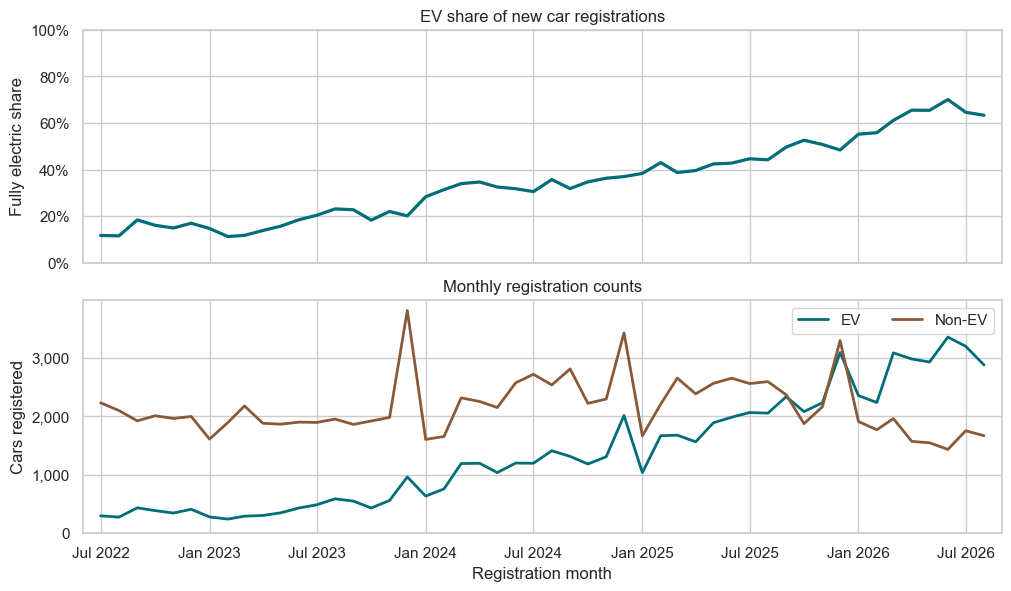

In [6]:
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

def format_eda_dates(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.set_xlabel("Registration or auction month")
    ax.margins(x=0.02)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 5.8), layout="constrained")
axes[0].plot(eda.index, eda.ev_share, color="#006d77", linewidth=2.3)
axes[0].set(ylabel="Fully electric share", title="EV share of new car registrations", ylim=(0, 1))
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
for name, label, colour in [("ev_registrations","EV","#006d77"), ("non_ev_registrations","Non-EV","#895a37")]:
    axes[1].plot(eda.index, eda[name], label=label, color=colour, linewidth=2)
axes[1].set(ylabel="Cars registered", title="Monthly registration counts", ylim=(0,None))
axes[1].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].legend(ncol=2)
format_eda_dates(axes[1])
axes[1].set_xlabel("Registration month")
plt.show()

EV share rose from **11.7% to 63.3%**, while monthly EV registrations increased from **297 to 2,880**. The rise was uneven: from June to July 2026, EV registrations fell while total registrations rose, taking EV share from **70.1% to 64.6%**. In August 2026, EVs accounted for **11.1% of the existing car fleet**; fleet share has a different denominator from the forecast target.

### Figure 2. COE market conditions

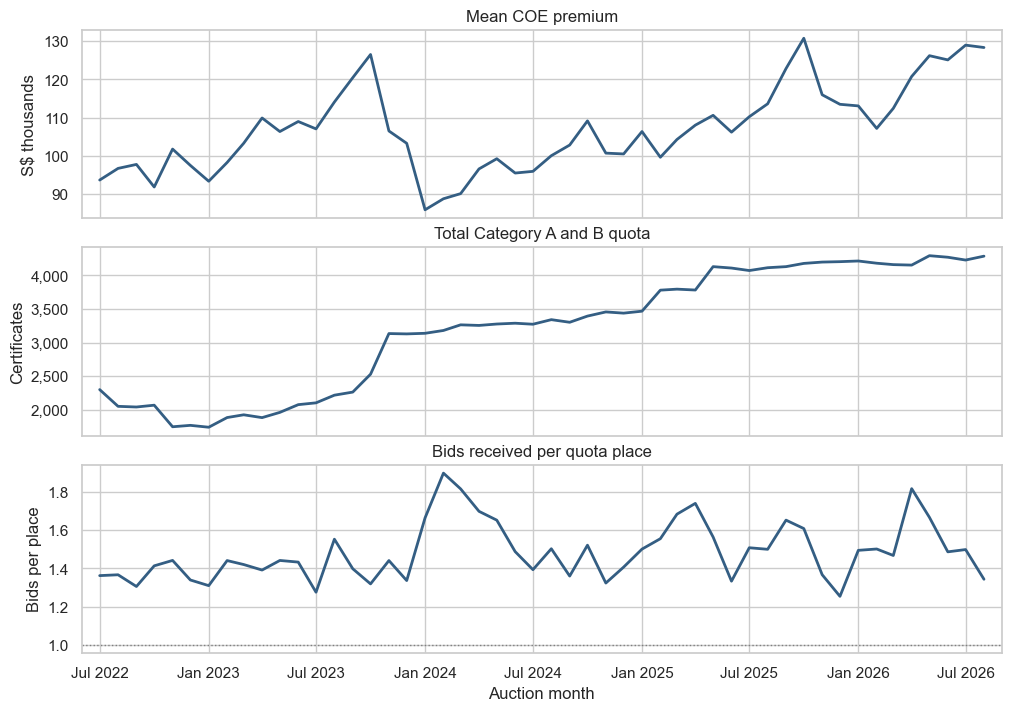

In [7]:
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(10, 7), layout="constrained")
for ax, series, label, unit in zip(axes,
        [eda.coe_premium_mean / 1000, eda.coe_quota_total, eda.bid_to_quota_ratio],
        ["Mean COE premium", "Total Category A and B quota", "Bids received per quota place"],
        ["S$ thousands", "Certificates", "Bids per place"]):
    ax.plot(eda.index, series, linewidth=2, color="#345e83")
    ax.set(title=label, ylabel=unit)
axes[1].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[2].axhline(1, color="grey", linestyle=":", linewidth=1)
format_eda_dates(axes[-1])
axes[-1].set_xlabel("Auction month")
plt.show()

Bids exceeded available quota in all 50 months. The ratio measures auction submissions per quota place; it does not identify EV buyers. The panels show the month each measure was observed. Section 14 uses the **previous month’s** premium, quota and bidding ratio to forecast EV share.

### Table 1. Do COE measures and EV share move together month to month?

In [8]:
eda_measures = pd.DataFrame({
    "Mean COE premium": eda.coe_premium_mean,
    "Category B minus A premium spread": eda.coe_b_premium - eda.coe_a_premium,
    "Total Category A and B quota": eda.coe_quota_total,
})
eda_delta = eda_measures.diff().iloc[1:]
share_delta_pp = 100 * eda.ev_share.diff().iloc[1:]
eda_correlations = pd.DataFrame({
    "Monthly levels (50 months)": eda_measures.corrwith(eda.ev_share),
    "Monthly changes (49 changes)": eda_delta.corrwith(share_delta_pp),
}).rename_axis("COE measure")
display(eda_correlations.round(2))

,Monthly levels (50 months),Monthly changes (49 changes)
COE measure,,
Mean COE premium,0.61,-0.11
Category B minus A premium spread,-0.76,-0.28
Total Category A and B quota,0.92,0.16


Entries are same-month Pearson correlations. Quota and EV share have a strong positive correlation in levels (**+0.92**), but the correlation between their monthly changes is **+0.16**. The premium association also weakens and changes sign. These comparisons describe how series moved together; they neither identify a causal effect nor measure whether earlier COE information improves a forecast.

## Section 9: Shared forecasting design and benchmarks
The primary evaluation produces expanding-window, one-month-ahead predictions for March 2025–August 2026 (18 months). Tree models and autoregressive regressions use 46 complete modelling rows from November 2022–August 2026, after constructing lagged levels and changes. Their training samples expand from 28 to 45 rows. Holt uses EV-share levels from July 2022, giving 32–49 training observations. All models are scored on the same test months, but do not use identical training samples.

EV share is expressed as a percentage; prediction errors are in percentage points (pp). Error means prediction minus actual, so negative mean error indicates underprediction. The last-value benchmark uses the previous month's actual share. Drift adds the average monthly change from the available modelling training rows.

The rolling forecasts assume that the previous month's EV and market figures are available at prediction time; publication timing has not been verified. Parameters are fitted using earlier observations only. However, the evaluation period has informed model development and comparison, so these are exploratory retrospective checks, not an untouched final test. Section 20A separately considers fixed-origin conditional predictions, and Appendix D examines illustrative projections and historical errors by horizon.


In [9]:
# 9A: Data handoff from Section 7's model_df, unit conversions and input validation.
import platform
import matplotlib.pyplot as plt
import scipy
import sklearn
from scipy import stats as forecast_stats
from scipy import optimize as forecast_optimize

FORECAST_START, FORECAST_END = pd.Timestamp("2022-07-01"), pd.Timestamp("2026-08-01")
FORECAST_SEED = 6312          # Seed for the primary tree-model comparisons
FORECAST_N_TEST = 18          # rolling test window: Mar 2025 - Aug 2026

forecast_input = model_df.copy(deep=True)
forecast_input["month"] = pd.to_datetime(forecast_input["month"], errors="raise")
forecast_input = forecast_input.set_index("month").sort_index().loc[FORECAST_START:FORECAST_END].copy()
if not forecast_input.index.equals(pd.date_range(FORECAST_START, FORECAST_END, freq="MS")):
    raise ValueError("Forecast evaluation requires all 50 unique, consecutive months.")
forecast_required = ["ev_share", "ev_registrations", "total_new_registrations", "coe_a_premium", "coe_b_premium",
                 "coe_a_quota", "coe_b_quota", "coe_a_bids_received", "coe_b_bids_received"]
if not np.isfinite(forecast_input[forecast_required].to_numpy(dtype=float)).all():
    raise ValueError("Missing or infinite inputs; no silent imputation or row removal.")
if not forecast_input[["total_new_registrations", "coe_a_quota", "coe_b_quota"]].gt(0).all().all():
    raise ValueError("Registration totals and quotas must be positive.")

# Working units for this section: EV share in percent (0-100), premiums in S$ thousand.
forecast_data = pd.DataFrame(index=forecast_input.index)
forecast_data["ev_share"] = 100 * forecast_input["ev_registrations"] / forecast_input["total_new_registrations"]
np.testing.assert_allclose(forecast_data["ev_share"], 100 * forecast_input["ev_share"], rtol=1e-12, atol=1e-10)
forecast_data["prem_a"] = forecast_input["coe_a_premium"] / 1000
forecast_data["prem_b"] = forecast_input["coe_b_premium"] / 1000
forecast_data["quota_ab"] = forecast_input["coe_a_quota"] + forecast_input["coe_b_quota"]
forecast_data["bids_ab"] = forecast_input["coe_a_bids_received"] + forecast_input["coe_b_bids_received"]
forecast_data["bid_to_quota"] = forecast_data["bids_ab"] / forecast_data["quota_ab"]

In [10]:
# 9B: Lagged features, the rolling evaluation design and the two benchmarks.
forecast_y = forecast_data["ev_share"]
forecast_feature_source = forecast_data.assign(prem_gap=forecast_data["prem_b"] - forecast_data["prem_a"])

forecast_coe_features = pd.DataFrame(index=forecast_data.index)
for c in ["prem_a", "prem_b", "prem_gap", "bid_to_quota", "quota_ab"]:
    for k in (1, 2, 3):
        forecast_coe_features[f"{c}_lag{k}"] = forecast_feature_source[c].shift(k)          # level k months earlier
for c in ["prem_a", "prem_b", "bid_to_quota", "quota_ab"]:
    for k in (1, 2, 3):
        forecast_coe_features[f"d_{c}_lag{k}"] = forecast_feature_source[c].diff().shift(k) # monthly change k months earlier
forecast_ev_features = pd.DataFrame({
    "ev_share_lag1": forecast_y.shift(1), "ev_share_lag2": forecast_y.shift(2),
    "d_ev_share_lag1": forecast_y.diff().shift(1), "d_ev_share_lag2": forecast_y.diff().shift(2),
})
forecast_model_data = forecast_coe_features.join(forecast_ev_features)
forecast_model_data["y"] = forecast_y            # target as a level (EV share, %)
forecast_model_data["dy"] = forecast_y.diff()    # target as the monthly change (pp)
forecast_model_data = forecast_model_data.dropna()

FORECAST_COE_LEVELS = [c for c in forecast_coe_features.columns if not c.startswith("d_")]
FORECAST_COE_CHANGES = [c for c in forecast_coe_features.columns if c.startswith("d_")]
FORECAST_EV_LEVELS = ["ev_share_lag1", "ev_share_lag2"]
FORECAST_EV_CHANGES = ["d_ev_share_lag1", "d_ev_share_lag2"]

forecast_test_idx = forecast_model_data.index[-FORECAST_N_TEST:]
forecast_actual = forecast_model_data.loc[forecast_test_idx, "y"]
assert forecast_model_data.index.equals(pd.date_range("2022-11-01", "2026-08-01", freq="MS"))
assert forecast_test_idx.equals(pd.date_range("2025-03-01", "2026-08-01", freq="MS"))


def forecast_walk_forward(make_model, features, target):
    """Expanding window: for each test month, fit on all earlier modelling rows and predict that month.
    target "y" predicts the share directly; target "dy" predicts the change and adds it to last month's actual share."""
    preds = []
    for i in range(len(forecast_model_data) - FORECAST_N_TEST, len(forecast_model_data)):
        train, test = forecast_model_data.iloc[:i], forecast_model_data.iloc[[i]]
        p = make_model().fit(train[features], train[target]).predict(test[features])[0]
        preds.append(test["ev_share_lag1"].iloc[0] + p if target == "dy" else p)
    return pd.Series(preds, index=forecast_test_idx)


def forecast_score(pred):
    err = pred - forecast_actual        # positive = over-prediction (same sign convention as Section 13)
    return {"RMSE": float(np.sqrt((err**2).mean())), "MAE": float(err.abs().mean()), "mean_error": float(err.mean())}


forecast_results, forecast_predictions = [], {}
def forecast_record(family, model, features, target, pred):
    if not pred.index.equals(forecast_test_idx) or not np.isfinite(pred).all():
        raise ValueError("Prediction alignment or finiteness failure: " + model)
    forecast_predictions[(family, model, features, target)] = pred
    forecast_results.append({"family": family, "model": model, "features": features, "target": target, **forecast_score(pred)})

forecast_naive = forecast_model_data.loc[forecast_test_idx, "ev_share_lag1"]                                   # next month = this month
forecast_drift = pd.Series([forecast_model_data["ev_share_lag1"].iloc[i] + forecast_model_data["dy"].iloc[:i].mean()   # + average past change
                        for i in range(len(forecast_model_data) - FORECAST_N_TEST, len(forecast_model_data))], index=forecast_test_idx)
forecast_record("Benchmark", "Naive (last value)", "-", "-", forecast_naive)
forecast_record("Benchmark", "Naive + drift", "-", "-", forecast_drift)
FORECAST_NAIVE_RMSE = forecast_score(forecast_naive)["RMSE"]
FORECAST_DRIFT_RMSE = forecast_score(forecast_drift)["RMSE"]

print(f"Modelling rows: {len(forecast_model_data)} ({forecast_model_data.index.min():%Y-%m} to {forecast_model_data.index.max():%Y-%m}); "
      f"COE level features: {len(FORECAST_COE_LEVELS)}, COE change features: {len(FORECAST_COE_CHANGES)}")
print(f"Test months: {FORECAST_N_TEST} ({forecast_test_idx.min():%Y-%m} to {forecast_test_idx.max():%Y-%m}); "
      f"training rows grow from {len(forecast_model_data) - FORECAST_N_TEST} to {len(forecast_model_data) - 1}, always ending the month before the test month.")
display(pd.DataFrame(forecast_results).round(3))
def get_forecast_predictions(model, features=None, target=None):
    hits = [p for (fam, m, f, t), p in forecast_predictions.items()
            if m == model and (features is None or f == features) and (target is None or t == target)]
    if len(hits) != 1:
        raise KeyError(f"{model} / {features} / {target}: {len(hits)} matches")
    return hits[0]



Modelling rows: 46 (2022-11 to 2026-08); COE level features: 15, COE change features: 12
Test months: 18 (2025-03 to 2026-08); training rows grow from 28 to 45, always ending the month before the test month.


,family,model,features,target,RMSE,MAE,mean_error
0,Benchmark,Naive (last value),-,-,3.537,2.878,-1.128
1,Benchmark,Naive + drift,-,-,3.400,2.815,-0.162


### 9C. Should EV share be modelled as a level or as a monthly change?

EV share rises substantially over the study period. Regressing trending series on one another can produce misleading associations, so stationarity tests are used to assess whether modelling monthly changes merits further investigation.

- **ADF:** tests the null hypothesis of a unit root. Rejection provides evidence against that null under the chosen specification.
- **KPSS:** tests the null hypothesis of stationarity under the chosen specification. Rejection provides evidence against that null.

Neither test proves that differencing is necessary or that it will improve prediction. Their results depend on the specification and have limited power in this short sample.

The ADF lag-selection settings follow Appendix A2: AIC selection with up to three lags. EV-share levels are also assessed with a deterministic trend.

KPSS here uses the fixed bandwidth rule `int(4 × (n/100)^0.25)`, whereas Appendix A2 uses automatic bandwidth selection. Matching ADF settings do not make the complete stationarity procedures identical.


In [11]:
# 9C: Stationarity screening of levels and monthly changes. ADF and KPSS (numpy/scipy implementations).
def forecast_ols(X, y):
    """OLS with intercept. Returns coefficients, residuals and the design matrix used."""
    y = np.asarray(y, float)
    X = np.ones((len(y), 1)) if X is None else np.column_stack([np.ones(len(y)), np.asarray(X, float)])
    if np.linalg.matrix_rank(X) != X.shape[1]:
        raise ValueError("Rank-deficient design.")
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    return beta, y - X @ beta, X

# MacKinnon (2010) response-surface coefficients for ADF critical values (one variable).
FORECAST_ADF_CRIT = {"c": (-2.86154, -2.8903, -4.234, -40.040), "ct": (-3.41049, -4.3904, -9.036, -45.374)}  # 5% level

def forecast_adf(series, regression="c", max_lag=3):
    """Augmented Dickey-Fuller t-test; lag order by AIC on a common sample (max 3, as in Appendix A2), then refitted."""
    y = np.asarray(series, float)
    dy = np.diff(y)
    def design(p, start):
        t = np.arange(start, len(dy))
        cols = [y[t]] + [dy[t - j] for j in range(1, p + 1)]
        if regression == "ct":
            cols.append(t.astype(float))
        return np.column_stack(cols), dy[t]
    aic = {}
    for p in range(max_lag + 1):
        X, z = design(p, max_lag)
        _, e, Xc = forecast_ols(X, z)
        aic[p] = len(z) * np.log(e @ e / len(z)) + 2 * Xc.shape[1]
    p = min(aic, key=aic.get)
    X, z = design(p, p)
    beta, e, Xc = forecast_ols(X, z)
    se = np.sqrt(np.diag(e @ e / (len(z) - Xc.shape[1]) * np.linalg.inv(Xc.T @ Xc)))
    b, T = FORECAST_ADF_CRIT[regression], len(z)
    return {"stat": beta[1] / se[1], "lags": p, "crit_5%": b[0] + b[1] / T + b[2] / T**2 + b[3] / T**3}

def forecast_kpss(series, regression="c"):
    """KPSS test; Bartlett long-run variance with lag int(4 * (n/100)^(1/4)); 5% critical values from Kwiatkowski et al. (1992)."""
    y = np.asarray(series, float)
    n = len(y)
    _, e, _ = forecast_ols(np.arange(n, dtype=float)[:, None] if regression == "ct" else None, y)
    lags = int(4 * (n / 100) ** 0.25)
    lrv = e @ e / n + 2 * sum((1 - j / (lags + 1)) * (e[j:] @ e[:-j]) / n for j in range(1, lags + 1))
    return {"stat": np.sum(np.cumsum(e) ** 2) / (n**2 * lrv), "crit_5%": {"c": 0.463, "ct": 0.146}[regression]}

forecast_unit_rows = []
for name, s, reg in [
    ("EV share, level (%)", forecast_data["ev_share"], "ct"),
    ("EV share, monthly change (pp)", forecast_data["ev_share"].diff().dropna(), "c"),
    ("Cat A premium, level (S$k)", forecast_data["prem_a"], "c"),
    ("Cat A premium, monthly change", forecast_data["prem_a"].diff().dropna(), "c"),
    ("Cat B premium, level (S$k)", forecast_data["prem_b"], "c"),
    ("Cat B premium, monthly change", forecast_data["prem_b"].diff().dropna(), "c"),
]:
    a, k = forecast_adf(s, reg), forecast_kpss(s, reg)
    forecast_unit_rows.append({"series": name, "terms": {"c": "constant", "ct": "constant + trend"}[reg], "n": len(s),
        "ADF_lags": a["lags"], "ADF_stat": a["stat"], "ADF_5%_crit": a["crit_5%"], "ADF_rejects_unit_root": a["stat"] < a["crit_5%"],
        "KPSS_stat": k["stat"], "KPSS_5%_crit": k["crit_5%"], "KPSS_rejects_stationarity": k["stat"] > k["crit_5%"]})
forecast_unit_root = pd.DataFrame(forecast_unit_rows)
display(forecast_unit_root.round(3))
print("ADF null: unit root. KPSS null: stationary. With 49-50 months both tests have limited power.")

,series,terms,n,ADF_lags,ADF_stat,ADF_5%_crit,ADF_rejects_unit_root,KPSS_stat,KPSS_5%_crit,KPSS_rejects_stationarity
0,"EV share, level (%)",constant + trend,50,0,-3.044,-3.504,False,0.168,0.146,True
1,"EV share, monthly change (pp)",constant,49,0,-8.212,-2.924,True,0.072,0.463,False
2,"Cat A premium, level (S$k)",constant,50,0,-1.226,-2.923,False,0.960,0.463,True
3,"Cat A premium, monthly change",constant,49,3,-4.953,-2.928,True,0.070,0.463,False
4,"Cat B premium, level (S$k)",constant,50,0,-2.452,-2.923,False,0.261,0.463,False
5,"Cat B premium, monthly change",constant,49,0,-7.643,-2.924,True,0.053,0.463,False


ADF null: unit root. KPSS null: stationary. With 49-50 months both tests have limited power.


**Interpretation.** For EV-share levels, ADF does not reject a unit root and KPSS rejects trend stationarity. For Category A premium levels, ADF does not reject a unit root and KPSS rejects level stationarity. Category B premium levels are inconclusive: neither test rejects its respective null. For monthly changes of all three series, ADF rejects a unit root and KPSS does not reject stationarity under the reported settings.

These results support examining monthly changes without proving that differencing is necessary or improves prediction. Section 17 tests level-versus-change regression specifications separately.


## Section 10: Full-sample market-indicator regressions
Three specifications examine premium spread and quota mix using GLSAR, GLSAR with calendar eras, and OLS with a post-2024 intercept shift. The main tables use GLSAR fits with a 100-iteration cap and require convergence. Appendix B retains the original five-iteration replication and stricter-tolerance checks. Section 13 evaluates eligible models on held-out months. Calendar-era associations do not identify causal policy effects.


In [12]:
# 10A: Shared data and features for the market-indicator regressions.
import statsmodels.api as sm
from statsmodels.regression.linear_model import GLSAR
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson

regression_data = dataset.loc[dataset["month"].between(EV_CLASSIFICATION_START, ANALYSIS_END)].copy()
regression_data = regression_data.sort_values("month").reset_index(drop=True)
if not pd.DatetimeIndex(regression_data["month"]).equals(pd.date_range(EV_CLASSIFICATION_START, ANALYSIS_END, freq="MS")):
    raise ValueError("Regression requires the complete 50-month EV window.")
required_regression_columns = ["ev_share", "coe_a_premium", "coe_b_premium", "coe_a_quota", "coe_b_quota", "coe_a_bids_received", "coe_b_bids_received"]
if len(regression_data) != 50 or not np.isfinite(regression_data[required_regression_columns].to_numpy(dtype=float)).all():
    raise ValueError("Expected 50 finite observations; no interpolation or silent row removal.")
if not regression_data[["coe_a_quota", "coe_b_quota"]].gt(0).all().all():
    raise ValueError("Quotas must be positive for ratio calculations.")
regression_data["coe_b_to_a_premium_spread"] = regression_data["coe_b_premium"] - regression_data["coe_a_premium"]
regression_data["quota_supply_mix_ratio"] = regression_data["coe_a_quota"] / regression_data["coe_b_quota"]
regression_data["relative_bidding_heat"] = regression_data["coe_a_bids_received"] / regression_data["coe_a_quota"] - regression_data["coe_b_bids_received"] / regression_data["coe_b_quota"]
regression_data["eeai_cap_15k_era"] = regression_data["month"].between("2024-01-01", "2025-12-01").astype(int)
regression_data["eeai_cap_7k5_era"] = regression_data["month"].ge("2026-01-01").astype(int)
regression_data["post_2024_era"] = regression_data["month"].ge("2024-01-01").astype(int)
for source, target in [("coe_b_to_a_premium_spread", "spread_centered"), ("quota_supply_mix_ratio", "quota_ratio_centered")]:
    regression_data[target] = regression_data[source] - regression_data[source].mean()
regression_y = regression_data["ev_share"]
regression_specs = {
    "R1_GLSAR_market": ["coe_b_to_a_premium_spread", "quota_supply_mix_ratio"],
    "R2_GLSAR_eras": ["spread_centered", "quota_ratio_centered", "eeai_cap_15k_era", "eeai_cap_7k5_era"],
    "R3_OLS_post2024_shift": ["coe_b_to_a_premium_spread", "quota_supply_mix_ratio", "relative_bidding_heat", "post_2024_era"],
}
regression_designs = {name: sm.add_constant(regression_data[features], has_constant="add") for name, features in regression_specs.items()}
for name, design in regression_designs.items():
    if np.linalg.matrix_rank(design.to_numpy()) != design.shape[1]:
        raise ValueError(f"Rank-deficient design: {name}")
regression_models = {}
print("Regression sample:", len(regression_data), "months. Outcome: EV share (0–1).")
print("Era counts:", {"Jul2022_Dec2023": int(regression_data["month"].lt("2024-01-01").sum()), "2024_2025": int(regression_data["eeai_cap_15k_era"].sum()), "2026": int(regression_data["eeai_cap_7k5_era"].sum())})

Regression sample: 50 months. Outcome: EV share (0–1).
Era counts: {'Jul2022_Dec2023': 18, '2024_2025': 24, '2026': 8}


### 10B–D. Fit the three regression specifications

In [13]:
# Full-sample GLSAR fits use a 100-iteration cap and require convergence.
for regression_name in ("R1_GLSAR_market", "R2_GLSAR_eras"):
    regression_fit = GLSAR(regression_y, regression_designs[regression_name], rho=1).iterative_fit(maxiter=100, rtol=1e-4)
    if not regression_fit.converged:
        raise RuntimeError("GLSAR did not converge: " + regression_name)
    regression_models[regression_name] = regression_fit
    print(regression_name)
    print(regression_fit.summary())
regression_fit = sm.OLS(regression_y, regression_designs["R3_OLS_post2024_shift"]).fit()
regression_models["R3_OLS_post2024_shift"] = regression_fit
print("OLS with a post-2024 intercept shift")
print(regression_fit.summary())


R1_GLSAR_market
                           GLSAR Regression Results                           
Dep. Variable:               ev_share   R-squared:                       0.092
Model:                          GLSAR   Adj. R-squared:                  0.053
Method:                 Least Squares   F-statistic:                     2.338
Date:                Sat, 21 Nov 2026   Prob (F-statistic):              0.108
Time:                        23:11:01   Log-Likelihood:                 101.90
No. Observations:                  49   AIC:                            -197.8
Df Residuals:                      46   BIC:                            -192.1
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const 

### 10E. Coefficients, fit and diagnostics

Report every model without selecting a winner. GLSAR’s native R² uses transformed data and should not be compared directly with OLS R². The common-window RMSE below uses original-scale fitted values for August 2022–August 2026 (49 months) for all three models; it is an in-sample descriptive metric, not forecast validation. GLSAR estimates use 49 transformed observations; OLS uses all 50.

For GLSAR, inspect **whitened residuals**, estimated rho and the convergence flag. For OLS, inspect ordinary residuals. Ljung–Box checks at lag 6 are approximate diagnostics (AR parameter adjustment of 1 for GLSAR). VIF is calculated separately for each design. HAC standard errors (three lags) are provided for the same OLS fit as an additional sensitivity check; they do not fix omitted variables, trends or endogeneity.

EV share is bounded between 0 and 1; these linear models do not enforce those bounds. A coefficient of 0.01 corresponds to one percentage point of EV share per predictor unit, holding other regressors fixed. Premium spread is in SGD, so its coefficient is per SGD 1. Era coefficients compare with the omitted calendar period, not with an untreated control group.

In [14]:
# 10E: Main coefficients and diagnostics using converged GLSAR fits.
coefficient_rows, diagnostic_rows, vif_rows = [], [], []
for name, fit in regression_models.items():
    ci = fit.conf_int()
    for variable in fit.params.index:
        coefficient_rows.append({"model": name, "variable": variable, "coefficient": fit.params[variable], "std_error": fit.bse[variable], "p_value": fit.pvalues[variable], "CI_low": ci.loc[variable, 0], "CI_high": ci.loc[variable, 1]})
    is_glsar = name.startswith("R1") or name.startswith("R2")
    residual = np.asarray(fit.wresid if is_glsar else fit.resid)
    lb = acorr_ljungbox(residual, lags=[6], model_df=1 if is_glsar else 0, return_df=True)
    prediction = np.asarray(fit.predict(regression_designs[name]))
    common_error = regression_y.to_numpy()[1:] - prediction[1:]
    diagnostic_rows.append({"model": name, "fit_nobs": int(fit.nobs), "native_R2": fit.rsquared, "common_RMSE_pp": 100*np.sqrt(np.mean(common_error**2)), "rho": float(fit.model.rho[0]) if is_glsar else np.nan, "GLSAR_converged": getattr(fit, "converged", None) if is_glsar else "N/A", "DW_residual": durbin_watson(residual), "LB6_p": lb["lb_pvalue"].iloc[0], "fitted_outside_0_1": int(((prediction<0)|(prediction>1)).sum())})
    design = regression_designs[name]
    for j, variable in enumerate(design.columns):
        if variable != "const":
            vif_rows.append({"model": name, "variable": variable, "VIF": variance_inflation_factor(design.to_numpy(), j)})
regression_coefficients = pd.DataFrame(coefficient_rows)
regression_diagnostics = pd.DataFrame(diagnostic_rows)
regression_vif = pd.DataFrame(vif_rows)
display(regression_coefficients)
display(regression_diagnostics.round(5))
display(regression_vif.round(3))

ols_hac = regression_models["R3_OLS_post2024_shift"].get_robustcov_results(cov_type="HAC", maxlags=3, use_correction=True, use_t=True)
ols_hac_summary = pd.DataFrame({"variable": regression_designs["R3_OLS_post2024_shift"].columns, "coefficient": ols_hac.params, "HAC_std_error": ols_hac.bse, "HAC_p_value": ols_hac.pvalues})
print("R3 OLS: same coefficients, HAC(3) inference sensitivity")
display(ols_hac_summary)
if regression_diagnostics["LB6_p"].lt(0.05).any():
    print("Residual dependence flagged: model-based p-values require caution and further specification review.")
print("Full-sample association only; these fitted-value metrics are not out-of-sample forecast performance.")


,model,variable,coefficient,std_error,p_value,CI_low,CI_high
0,R1_GLSAR_market,const,0.653443,1.425919e-01,0.000035,0.366421,9.404658e-01
1,R1_GLSAR_market,coe_b_to_a_premium_spread,-0.000002,1.024139e-06,0.111126,-0.000004,3.978840e-07
2,R1_GLSAR_market,quota_supply_mix_ratio,-0.042966,6.972504e-02,0.540789,-0.183315,9.738345e-02
3,R2_GLSAR_eras,const,0.434651,9.075624e-02,0.000019,0.251744,6.175586e-01
4,R2_GLSAR_eras,spread_centered,-0.000001,9.670185e-07,0.179776,-0.000003,6.307234e-07
5,R2_GLSAR_eras,quota_ratio_centered,-0.054359,6.393640e-02,0.399814,-0.183214,7.449626e-02
6,R2_GLSAR_eras,eeai_cap_15k_era,0.066258,3.023339e-02,0.033750,0.005327,1.271894e-01
7,R2_GLSAR_eras,eeai_cap_7k5_era,0.141428,4.153452e-02,0.001422,0.057721,2.251357e-01
8,R3_OLS_post2024_shift,const,-0.177223,1.397162e-01,0.211159,-0.458626,1.041794e-01
9,R3_OLS_post2024_shift,coe_b_to_a_premium_spread,-0.000011,1.976893e-06,0.000001,-0.000015,-7.047163e-06


,model,fit_nobs,native_R2,common_RMSE_pp,rho,GLSAR_converged,DW_residual,LB6_p,fitted_outside_0_1
0,R1_GLSAR_market,49,0.09226,26.45005,0.95594,True,2.26860,0.64968,0
1,R2_GLSAR_eras,49,0.28373,18.22970,0.95130,True,2.13309,0.47174,0
2,R3_OLS_post2024_shift,50,0.79698,7.59541,NaN,N/A,0.52623,0.00000,0


,model,variable,VIF
0,R1_GLSAR_market,coe_b_to_a_premium_spread,1.093
1,R1_GLSAR_market,quota_supply_mix_ratio,1.093
2,R2_GLSAR_eras,spread_centered,4.606
3,R2_GLSAR_eras,quota_ratio_centered,3.597
4,R2_GLSAR_eras,eeai_cap_15k_era,7.370
5,R2_GLSAR_eras,eeai_cap_7k5_era,7.884
6,R3_OLS_post2024_shift,coe_b_to_a_premium_spread,2.728
7,R3_OLS_post2024_shift,quota_supply_mix_ratio,3.308
8,R3_OLS_post2024_shift,relative_bidding_heat,1.099
9,R3_OLS_post2024_shift,post_2024_era,6.057


R3 OLS: same coefficients, HAC(3) inference sensitivity


,variable,coefficient,HAC_std_error,HAC_p_value
0,const,-0.177223,0.159466,0.272318
1,coe_b_to_a_premium_spread,-0.000011,0.000003,0.000254
2,quota_supply_mix_ratio,0.507434,0.112958,0.000049
3,relative_bidding_heat,-0.018495,0.066203,0.781249
4,post_2024_era,0.001142,0.054350,0.983328


Residual dependence flagged: model-based p-values require caution and further specification review.
Full-sample association only; these fitted-value metrics are not out-of-sample forecast performance.


### 10F. Observed EV share and fitted values

In-sample fit on the original share scale. Display begins in August 2022 for a common comparison window; no forecasting claim is made.
For GLSAR, the plotted values show the regression component, Xβ, without an autoregressive error adjustment. Numerical convergence does not imply that this component closely tracks observed EV-share levels.


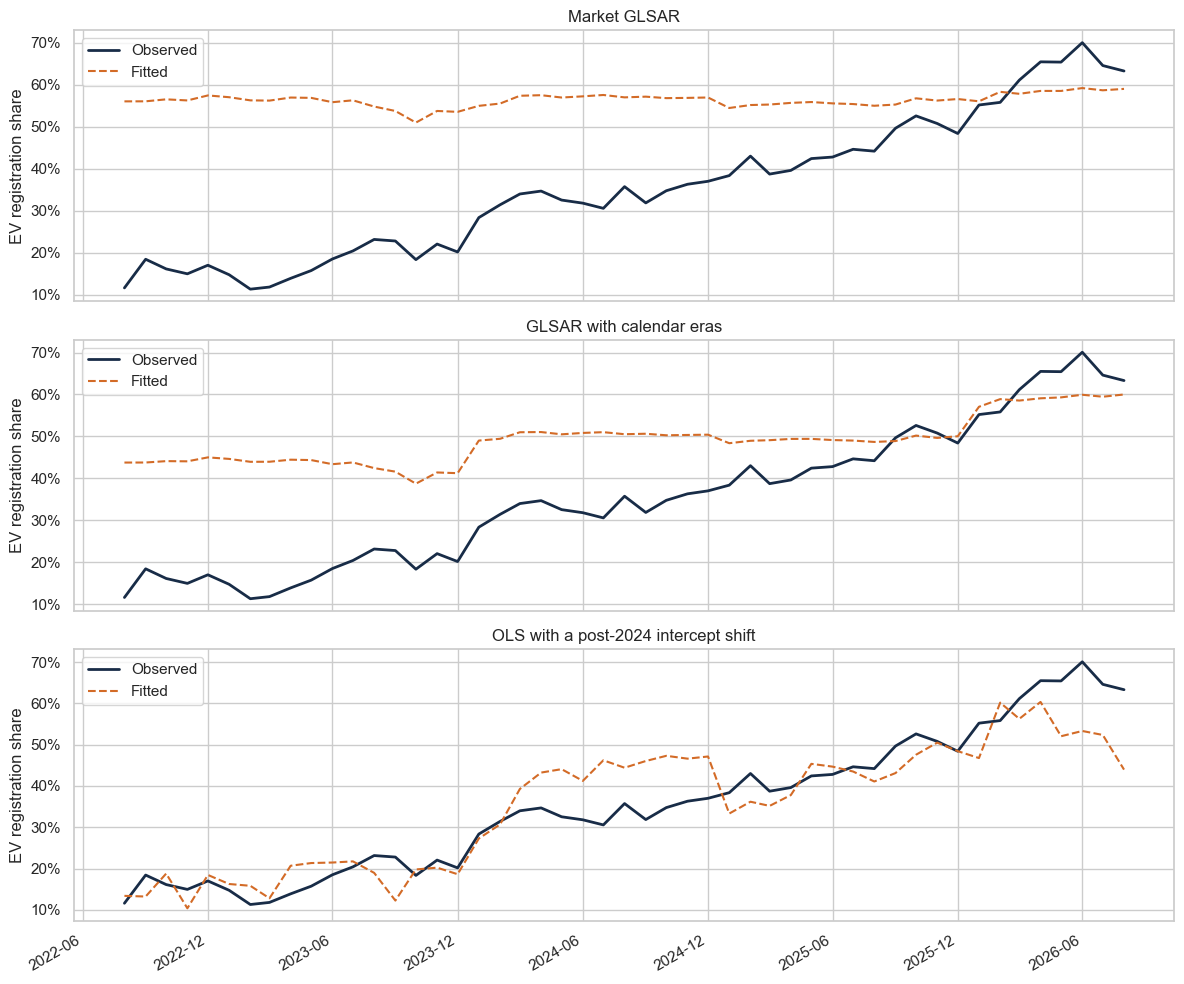

In [15]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
regression_chart_titles = {
    "R1_GLSAR_market": "Market GLSAR",
    "R2_GLSAR_eras": "GLSAR with calendar eras",
    "R3_OLS_post2024_shift": "OLS with a post-2024 intercept shift",
}
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, (name, fit) in zip(axes, regression_models.items()):
    ax.plot(regression_data["month"].iloc[1:], regression_y.iloc[1:], color="#182c47", label="Observed", linewidth=2)
    ax.plot(regression_data["month"].iloc[1:], np.asarray(fit.predict(regression_designs[name]))[1:], color="#d36b27", linestyle="--", label="Fitted")
    ax.set_title(regression_chart_titles[name])
    ax.set_ylabel("EV registration share")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(loc="upper left")
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## Section 11: Random-split premium regression comparison

Design: 50 EV months, a random 80:20 split with seed 67, three unscaled `LinearRegression` models with intercepts, and a training-mean baseline.

| Label | Premium predictor | Other predictors |
|---|---|---|
| Current Premium | `coe_premium_mean` | `coe_quota_total`, `bid_to_quota_ratio` |
| Lag-1 Premium | `coe_premium_lag1` | Same |
| Lag-2 Premium | `coe_premium_lag2` | Same |
| Baseline | None | Mean EV share in training observations |


Random assignment mixes earlier and later dates; this is a reference comparison, not evidence of future-month accuracy.

### 11A–D. Compare premium timings on the same random split

In [16]:
# 11A: Prepare an independent copy for the premium regressions.
from sklearn import metrics as premium_metrics
from sklearn.linear_model import LinearRegression as PremiumLinearRegression
from sklearn.model_selection import train_test_split as premium_train_test_split

premium_data = model_df.loc[model_df["ev_share"].notna()].copy(deep=True)
premium_data["month"] = pd.to_datetime(premium_data["month"], errors="raise")
premium_data = premium_data.sort_values("month").reset_index(drop=True)
premium_expected_months = pd.date_range(EV_CLASSIFICATION_START, ANALYSIS_END, freq="MS")
if len(premium_data) != 50 or not pd.DatetimeIndex(premium_data["month"]).equals(premium_expected_months):
    raise ValueError("The random-split evaluation expects 50 consecutive EV months, Jul 2022–Aug 2026.")
premium_required = ["ev_share", "coe_premium_mean", "coe_quota_total", "bid_to_quota_ratio", "coe_premium_lag1", "coe_premium_lag2"]
if not np.isfinite(premium_data[premium_required].to_numpy(dtype=float)).all():
    raise ValueError("Missing or infinite premium-model inputs; review instead of dropping different rows per model.")
premium_specs = {
    "Current Premium": ["coe_premium_mean", "coe_quota_total", "bid_to_quota_ratio"],
    "Lag-1 Premium": ["coe_premium_lag1", "coe_quota_total", "bid_to_quota_ratio"],
    "Lag-2 Premium": ["coe_premium_lag2", "coe_quota_total", "bid_to_quota_ratio"],
}
print("Premium regression sample:", len(premium_data), "months;", premium_data["month"].min().strftime("%Y-%m"), "to", premium_data["month"].max().strftime("%Y-%m"))

# 11B: One random split shared by the training-mean benchmark and three premium regressions.
premium_train_indices, premium_test_indices = premium_train_test_split(
    premium_data.index.to_numpy(), test_size=0.2, random_state=67, shuffle=True
)
assert len(premium_train_indices) == 40 and len(premium_test_indices) == 10
assert set(premium_train_indices).isdisjoint(premium_test_indices)
premium_y_train = premium_data.loc[premium_train_indices, "ev_share"]
premium_y_test = premium_data.loc[premium_test_indices, "ev_share"]
premium_split_audit = premium_data[["month"]].copy()
premium_split_audit["split"] = "Train"
premium_split_audit.loc[premium_test_indices, "split"] = "Test"
print("Random split: 40 training months; 10 testing months; seed 67.")
print("Training dates span", premium_data.loc[premium_train_indices, "month"].min().strftime("%Y-%m"), "to", premium_data.loc[premium_train_indices, "month"].max().strftime("%Y-%m"))
print("Test months:", premium_data.loc[premium_test_indices, "month"].sort_values().dt.strftime("%Y-%m").tolist())

# 11C: Training-mean baseline (never uses the test target to calculate the mean).
premium_baseline_value = float(premium_y_train.mean())
premium_predictions = {"Baseline": np.full(len(premium_test_indices), premium_baseline_value)}
premium_models = {}
premium_metric_rows = []

def premium_score_prediction(label, prediction):
    mae = premium_metrics.mean_absolute_error(premium_y_test, prediction)
    mse = premium_metrics.mean_squared_error(premium_y_test, prediction)
    return {"Model": label, "MAE": mae, "MSE": mse, "RMSE": np.sqrt(mse), "MAE_pp": 100*mae, "RMSE_pp": 100*np.sqrt(mse)}

premium_metric_rows.append(premium_score_prediction("Baseline", premium_predictions["Baseline"]))

# 11D: Fit the three premium regressions on the same training and test observations.
for premium_name, premium_features in premium_specs.items():
    premium_model = PremiumLinearRegression()
    premium_model.fit(premium_data.loc[premium_train_indices, premium_features], premium_y_train)
    premium_models[premium_name] = premium_model
    premium_predictions[premium_name] = premium_model.predict(premium_data.loc[premium_test_indices, premium_features])
    premium_metric_rows.append(premium_score_prediction(premium_name, premium_predictions[premium_name]))
premium_comparison = pd.DataFrame(premium_metric_rows).sort_values("RMSE").reset_index(drop=True)
print("Random-split comparison; lower error is better within this split.")
display(premium_comparison.round(6))

Premium regression sample: 50 months; 2022-07 to 2026-08
Random split: 40 training months; 10 testing months; seed 67.
Training dates span 2022-07 to 2026-08
Test months: ['2022-08', '2023-01', '2023-06', '2023-10', '2023-11', '2024-03', '2025-03', '2025-07', '2025-11', '2026-06']
Random-split comparison; lower error is better within this split.


,Model,MAE,MSE,RMSE,MAE_pp,RMSE_pp
0,Current Premium,0.060532,0.005813,0.076242,6.053192,7.624199
1,Lag-2 Premium,0.059256,0.006261,0.079129,5.925550,7.912896
2,Lag-1 Premium,0.068481,0.008556,0.092498,6.848084,9.249812
3,Baseline,0.155803,0.032855,0.181261,15.580297,18.126068


## Section 12: time-ordered evaluation

This chronological evaluation retains the three predictor sets and linear-regression estimator. It trains once on **July 2022–October 2025 (40 months)** and evaluates **November 2025–August 2026 (10 months)**. No test outcome is used for fitting, centering, selecting variables or updating the model. No tuning is performed here.

Two fixed benchmarks are fitted using training observations only:

- **Training mean:** predict the average training EV share for all ten test months.
- **Last training value:** predict October 2025’s EV share for all ten test months. This benchmark is not updated with outcomes from the test period.

**Scope:** predictions are conditional on the observed predictor values for each test month. Current-month quota and bidding intensity remain inputs to every model, and current premium remains an input to one model. Therefore, this is not a ten-month-ahead forecast made in October 2025. It tests whether coefficients learned earlier generalise to later months given their observed market indicators.

The test months have already been examined in previous EDA and random-split work, so this is a retrospective sensitivity evaluation, not a previously untouched final holdout. Random and chronological splits test different dates; their score differences cannot be attributed solely to splitting method. The full-sample fits are not ranked against these test scores.

### 12A. Fixed chronological split

In [17]:
# 12A: Independent data copy and explicit chronological boundary.
from sklearn.linear_model import LinearRegression as TemporalLinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

temporal_data = model_df.loc[model_df["ev_share"].notna()].copy(deep=True)
temporal_data["month"] = pd.to_datetime(temporal_data["month"], errors="raise")
temporal_data = temporal_data.sort_values("month").reset_index(drop=True)
if len(temporal_data) != 50 or not pd.DatetimeIndex(temporal_data["month"]).equals(pd.date_range(EV_CLASSIFICATION_START, ANALYSIS_END, freq="MS")):
    raise ValueError("Expected the complete 50-month EV sample from July 2022 through August 2026.")
temporal_specs = {name: list(features) for name, features in premium_specs.items()}
temporal_required = ["ev_share"] + sorted({c for features in temporal_specs.values() for c in features})
if not np.isfinite(temporal_data[temporal_required].to_numpy(dtype=float)).all():
    raise ValueError("Missing or infinite values; no temporal evaluation rows may be silently removed.")
temporal_train = temporal_data.loc[temporal_data["month"] <= pd.Timestamp("2025-10-01")].copy()
temporal_test = temporal_data.loc[temporal_data["month"] >= pd.Timestamp("2025-11-01")].copy()
assert len(temporal_train) == 40 and len(temporal_test) == 10
assert temporal_train["month"].max() < temporal_test["month"].min()
temporal_y_train = temporal_train["ev_share"]
temporal_y_test = temporal_test["ev_share"]
temporal_split_summary = pd.DataFrame([
    {"split": "Train", "months": len(temporal_train), "start": temporal_train["month"].min(), "end": temporal_train["month"].max()},
    {"split": "Test", "months": len(temporal_test), "start": temporal_test["month"].min(), "end": temporal_test["month"].max()},
])
display(temporal_split_summary)

,split,months,start,end
0,Train,40,2022-07-01,2025-10-01
1,Test,10,2025-11-01,2026-08-01


### 12B. Three regression models and two fixed benchmarks

In [18]:
# 12B: Train once; predict each test month using its observed predictors.
temporal_models = {}
temporal_predictions = {
    "Training mean": np.full(len(temporal_test), float(temporal_y_train.mean())),
    "Last training value": np.full(len(temporal_test), float(temporal_y_train.iloc[-1])),
}
for temporal_name, temporal_features in temporal_specs.items():
    temporal_model = TemporalLinearRegression()
    temporal_model.fit(temporal_train[temporal_features], temporal_y_train)
    temporal_models[temporal_name] = temporal_model
    temporal_predictions[temporal_name] = temporal_model.predict(temporal_test[temporal_features])
print(f"Fixed training-mean prediction: {100*temporal_y_train.mean():.2f}% EV share")
print(f"Fixed October 2025 prediction: {100*temporal_y_train.iloc[-1]:.2f}% EV share")

Fixed training-mean prediction: 28.44% EV share
Fixed October 2025 prediction: 52.60% EV share


### 12C. Error metrics and reference comparison

In [19]:
# 12C: Compare all five predictions on exactly the same ten dates.
temporal_metric_rows = []
for temporal_name, temporal_pred in temporal_predictions.items():
    temporal_error = temporal_pred - temporal_y_test.to_numpy()
    temporal_metric_rows.append({
        "Model": temporal_name,
        "Test_months": len(temporal_test),
        "MAE_pp": 100*mean_absolute_error(temporal_y_test, temporal_pred),
        "RMSE_pp": 100*np.sqrt(mean_squared_error(temporal_y_test, temporal_pred)),
        "Mean_error_pp": 100*temporal_error.mean(),
        "Outside_0_1": int(((temporal_pred < 0) | (temporal_pred > 1)).sum()),
    })
temporal_comparison = pd.DataFrame(temporal_metric_rows).sort_values("RMSE_pp").reset_index(drop=True)
display(temporal_comparison.round(3))
print("Errors are percentage points of EV share. Negative mean error means underprediction.")
temporal_mean_rmse = float(temporal_comparison.loc[temporal_comparison["Model"].eq("Training mean"), "RMSE_pp"].iloc[0])
temporal_last_rmse = float(temporal_comparison.loc[temporal_comparison["Model"].eq("Last training value"), "RMSE_pp"].iloc[0])
for temporal_name in temporal_specs:
    temporal_rmse = float(temporal_comparison.loc[temporal_comparison["Model"].eq(temporal_name), "RMSE_pp"].iloc[0])
    print(temporal_name, "| Beats mean:", temporal_rmse < temporal_mean_rmse, "| Beats last training value:", temporal_rmse < temporal_last_rmse)

# Report random-split and chronological scores separately because their test months differ.
temporal_split_comparison = premium_comparison.loc[premium_comparison["Model"].isin(temporal_specs), ["Model", "MAE_pp", "RMSE_pp"]].rename(columns={"MAE_pp":"Random_MAE_pp", "RMSE_pp":"Random_RMSE_pp"})
temporal_split_comparison = temporal_split_comparison.merge(temporal_comparison[["Model", "MAE_pp", "RMSE_pp"]], on="Model", validate="one_to_one").rename(columns={"MAE_pp":"Chronological_MAE_pp", "RMSE_pp":"Chronological_RMSE_pp"})
display(temporal_split_comparison.round(3))
print("Different splits contain different test months; these are sensitivity results, not a controlled comparison of split methods.")

,Model,Test_months,MAE_pp,RMSE_pp,Mean_error_pp,Outside_0_1
0,Last training value,10,8.627,10.027,-7.424,0
1,Current Premium,10,13.480,14.446,-13.480,0
2,Lag-1 Premium,10,14.123,15.272,-14.123,0
3,Lag-2 Premium,10,15.057,16.202,-15.057,0
4,Training mean,10,31.592,32.303,-31.592,0


Errors are percentage points of EV share. Negative mean error means underprediction.
Current Premium | Beats mean: True | Beats last training value: False
Lag-1 Premium | Beats mean: True | Beats last training value: False
Lag-2 Premium | Beats mean: True | Beats last training value: False


,Model,Random_MAE_pp,Random_RMSE_pp,Chronological_MAE_pp,Chronological_RMSE_pp
0,Current Premium,6.053,7.624,13.480,14.446
1,Lag-2 Premium,5.926,7.913,15.057,16.202
2,Lag-1 Premium,6.848,9.250,14.123,15.272


Different splits contain different test months; these are sensitivity results, not a controlled comparison of split methods.


### 12D. Prediction comparison

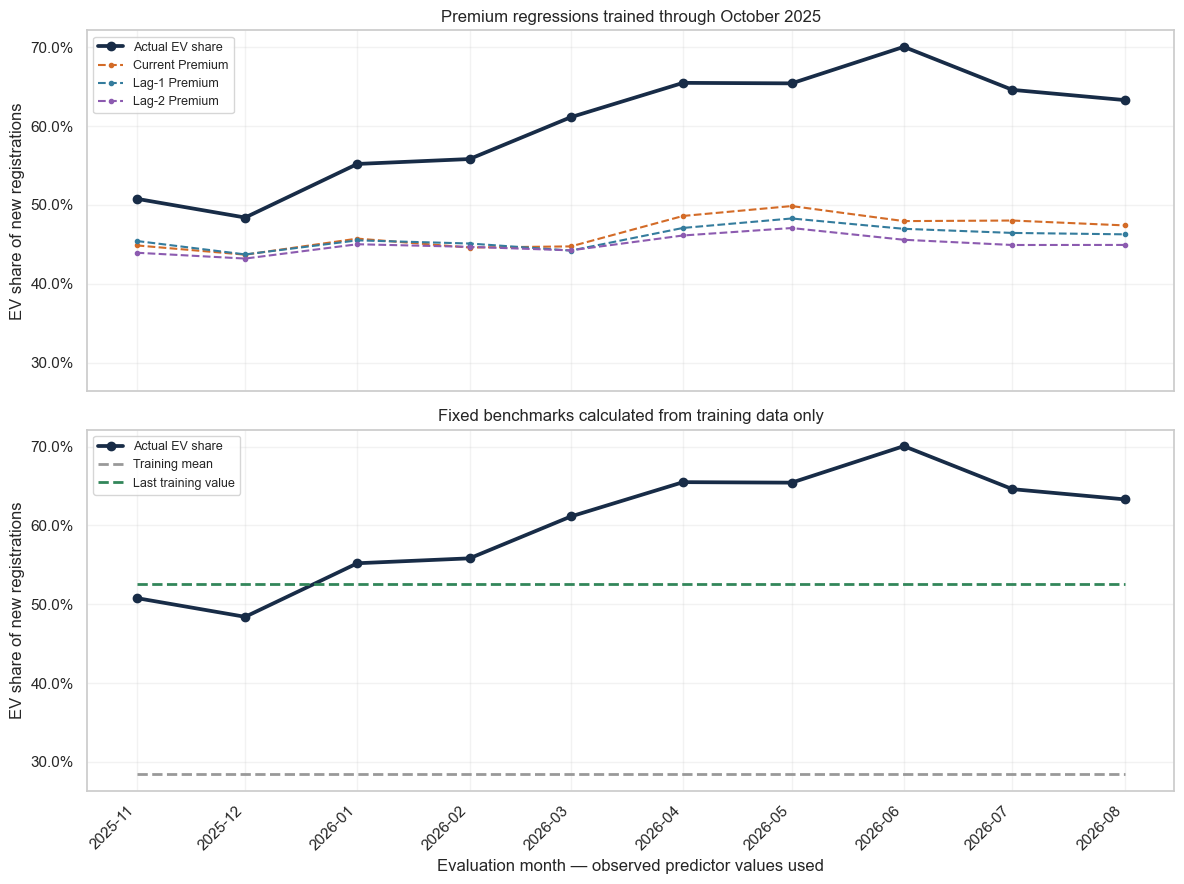

In [20]:
# 12D: Actual versus predicted EV share on the shared test window.
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True, sharey=True)
temporal_dates = temporal_test["month"]
for ax in axes:
    ax.plot(temporal_dates, temporal_y_test, color="#182c47", linewidth=2.7, marker="o", label="Actual EV share")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylabel("EV share of new registrations")
    ax.grid(alpha=0.25)
for temporal_name, color in zip(temporal_specs, ["#d36b27", "#347c9d", "#8c5bb0"]):
    axes[0].plot(temporal_dates, temporal_predictions[temporal_name], linestyle="--", marker=".", color=color, label=temporal_name)
for temporal_name, color in [("Training mean", "#999999"), ("Last training value", "#32865a")]:
    axes[1].plot(temporal_dates, temporal_predictions[temporal_name], linestyle="--", linewidth=2, color=color, label=temporal_name)
axes[0].set_title("Premium regressions trained through October 2025")
axes[1].set_title("Fixed benchmarks calculated from training data only")
for ax in axes:
    ax.legend(loc="upper left", fontsize=9)
axes[1].xaxis.set_major_locator(mdates.MonthLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[1].set_xlabel("Evaluation month — observed predictor values used")
fig.autofmt_xdate(rotation=45)
fig.tight_layout()
plt.show()

## Section 13: common chronological evaluation

All models below use the same **40 input training months (July 2022–October 2025)** and **10 test months (November 2025–August 2026)**. Fits use training outcomes only. No tuning or feature selection uses test outcomes. These dates have already been explored, so this is a retrospective comparison, not a new untouched final holdout.

The comparison includes Market GLSAR (R1), OLS with a post-2024 intercept shift (R3), the current-premium, lag-1-premium and lag-2-premium regressions, and the training-mean and last-training-value benchmarks. R1 loses its first observation through AR(1) whitening, giving 39 transformed training observations; the other regressions use 40. All models share the same available training history and test observations.

**Era GLSAR (R2) is excluded from this comparison:** its 2026 indicator is zero throughout training and its effect is unidentifiable. No full-sample coefficient is borrowed, and the indicator is neither dropped nor assigned a zero effect. It remains available as a full-sample explanatory specification in Section 10 and Appendix B. A revised R2 would be a separately labelled model.

Predictions use actual test-month market inputs. They are conditional out-of-time estimates, not ten-month-ahead forecasts made in October 2025. For R1, predictions are the regression component `X @ beta`, consistent with earlier reporting; AR(1) affects coefficient estimation, and no observed test residuals or lagged test outcomes update predictions. This is not a complete AR-error forecasting comparison. R1 and R3 require no centering; their features are calculated within each row. Premium lags retain their existing past-only definitions.



In [21]:
# 13A: Prepare the common sample and independently fit eligible models.
common_data = model_df.loc[model_df["ev_share"].notna()].copy(deep=True)
common_data["month"] = pd.to_datetime(common_data["month"], errors="raise")
common_data = common_data.sort_values("month").reset_index(drop=True)
if not pd.DatetimeIndex(common_data["month"]).equals(pd.date_range("2022-07-01", "2026-08-01", freq="MS")):
    raise ValueError("Expected the same 50-month EV sample.")
if not common_data[["coe_a_quota", "coe_b_quota"]].gt(0).all().all():
    raise ValueError("Positive quotas are required.")
common_data["coe_b_to_a_premium_spread"] = common_data["coe_b_premium"] - common_data["coe_a_premium"]
common_data["quota_supply_mix_ratio"] = common_data["coe_a_quota"] / common_data["coe_b_quota"]
common_data["relative_bidding_heat"] = common_data["coe_a_bids_received"] / common_data["coe_a_quota"] - common_data["coe_b_bids_received"] / common_data["coe_b_quota"]
common_data["post_2024_era"] = common_data["month"].ge("2024-01-01").astype(int)
common_train = common_data.loc[common_data["month"].le("2025-10-01")].copy()
common_test = common_data.loc[common_data["month"].ge("2025-11-01")].copy()
assert len(common_train) == 40 and len(common_test) == 10
assert common_train["month"].max() < common_test["month"].min()
assert common_test["month"].reset_index(drop=True).equals(temporal_test["month"].reset_index(drop=True))
common_specs = {
    "Market GLSAR": ["coe_b_to_a_premium_spread", "quota_supply_mix_ratio"],
    "OLS with a post-2024 intercept shift": ["coe_b_to_a_premium_spread", "quota_supply_mix_ratio", "relative_bidding_heat", "post_2024_era"],
    **{"Premium model: " + name: list(features) for name, features in premium_specs.items()},
}
common_required = ["ev_share"] + sorted({f for features in common_specs.values() for f in features})
if not np.isfinite(common_data[common_required].to_numpy(dtype=float)).all():
    raise ValueError("Non-finite model input; no silent row removal allowed.")
common_y_train = common_train["ev_share"]
common_y_test = common_test["ev_share"].to_numpy()
common_models = {}
common_predictions = {
    "Training mean": np.full(10, float(common_y_train.mean())),
    "Last training value": np.full(10, float(common_y_train.iloc[-1])),
}
common_fit_rows = []
for common_name, common_features in common_specs.items():
    common_x_train = sm.add_constant(common_train[common_features], has_constant="add")
    common_x_test = sm.add_constant(common_test[common_features], has_constant="add")
    if np.linalg.matrix_rank(common_x_train.to_numpy()) != common_x_train.shape[1]:
        raise ValueError("Rank-deficient training design: " + common_name)
    if common_name == "Market GLSAR":
        common_fit = GLSAR(common_y_train, common_x_train, rho=1).iterative_fit(maxiter=100, rtol=1e-4)
        if not common_fit.converged:
            raise RuntimeError("Training-only R1 did not converge; inspect before comparing.")
        common_strict = GLSAR(common_y_train, common_x_train, rho=1).iterative_fit(maxiter=1000, rtol=1e-8)
        if not common_strict.converged:
            raise RuntimeError("Stricter training-only R1 check did not converge.")
        common_pred = np.asarray(common_fit.predict(common_x_test))
        common_r1_sensitivity_pp = float(100*np.max(np.abs(common_pred - common_strict.predict(common_x_test))))
    elif common_name == "OLS with a post-2024 intercept shift":
        common_fit = sm.OLS(common_y_train, common_x_train).fit()
        common_pred = np.asarray(common_fit.predict(common_x_test))
    else:
        common_fit = TemporalLinearRegression().fit(common_train[common_features], common_y_train)
        common_pred = common_fit.predict(common_test[common_features])
        np.testing.assert_allclose(common_pred, temporal_predictions[common_name.removeprefix("Premium model: ")], rtol=1e-10, atol=1e-12)
    common_models[common_name] = common_fit
    common_predictions[common_name] = common_pred
    common_fit_rows.append({
        "Model": common_name, "Training_input_months": 40,
        "Fitted_observations": int(common_fit.nobs) if common_name in {"Market GLSAR", "OLS with a post-2024 intercept shift"} else 40,
        "GLSAR_converged": bool(common_fit.converged) if common_name == "Market GLSAR" else "N/A",
        "GLSAR_iterations": int(common_fit.iter) if common_name == "Market GLSAR" else np.nan,
        "rho": float(common_fit.model.rho[0]) if common_name == "Market GLSAR" else np.nan,
    })
display(pd.DataFrame(common_fit_rows))
print("R1 stricter-tolerance maximum test-prediction change (percentage points):", common_r1_sensitivity_pp)
print("R2 excluded: no training observations in the 2026 era.")

,Model,Training_input_months,Fitted_observations,GLSAR_converged,GLSAR_iterations,rho
0,Market GLSAR,40,39,True,12.0,0.918371
1,OLS with a post-2024 intercept shift,40,40,N/A,NaN,NaN
2,Premium model: Current Premium,40,40,N/A,NaN,NaN
3,Premium model: Lag-1 Premium,40,40,N/A,NaN,NaN
4,Premium model: Lag-2 Premium,40,40,N/A,NaN,NaN


R1 stricter-tolerance maximum test-prediction change (percentage points): 1.6168740968325324e-05
R2 excluded: no training observations in the 2026 era.


In [22]:
# 13B: Identical test dates, target values and metrics for every model.
common_rows = []
for common_name, common_pred in common_predictions.items():
    common_error = np.asarray(common_pred) - common_y_test
    common_rows.append({
        "Model": common_name, "Test_months": len(common_y_test),
        "MAE_pp": 100*np.mean(np.abs(common_error)),
        "RMSE_pp": 100*np.sqrt(np.mean(common_error**2)),
        "Mean_error_pp": 100*np.mean(common_error),
        "Outside_0_1": int(((common_pred < 0) | (common_pred > 1)).sum()),
    })
common_comparison = pd.DataFrame(common_rows).sort_values("RMSE_pp").reset_index(drop=True)
common_last_rmse = float(common_comparison.loc[common_comparison["Model"].eq("Last training value"), "RMSE_pp"].iloc[0])
common_comparison["Beats_last_RMSE"] = common_comparison["RMSE_pp"].lt(common_last_rmse)
display(common_comparison.round(3))

,Model,Test_months,MAE_pp,RMSE_pp,Mean_error_pp,Outside_0_1,Beats_last_RMSE
0,Last training value,10,8.627,10.027,-7.424,0,False
1,Premium model: Current Premium,10,13.480,14.446,-13.480,0,False
2,Premium model: Lag-1 Premium,10,14.123,15.272,-14.123,0,False
3,Premium model: Lag-2 Premium,10,15.057,16.202,-15.057,0,False
4,Market GLSAR,10,17.436,18.374,-17.436,0,False
5,OLS with a post-2024 intercept shift,10,20.835,22.562,-20.835,0,False
6,Training mean,10,31.592,32.303,-31.592,0,False


### Common-window findings

For this fixed ten-month window, the last-training-value benchmark has the lowest RMSE (**10.03 percentage points**). The current-premium model is the lowest-error regression among these initial market-indicator specifications (14.45 pp), followed by lag-1 (15.27 pp), lag-2 (16.20 pp), Market GLSAR (R1) (18.37 pp) and OLS with a post-2024 intercept shift (R3) (22.56 pp). All five regressions beat the training-mean benchmark (32.30 pp), but none beats the last-training-value benchmark. Every regression underpredicts every test month.

Market GLSAR (R1) converges on the training-only sample in 12 iterations; its fitted rho is approximately 0.918. The stricter fit changes test predictions by less than 0.00002 percentage points. Numerical instability therefore does not explain its observed test error here.

## Section 14 · Predicting future EV share with trend and adoption history
Each linear regression includes an intercept. Compare the contribution of a calendar trend and the last observed EV share against three COE measures: previous-month mean premium, total quota and bids per quota. All market inputs are lagged. Benchmark predictions use the training mean, the last observed share or the last share plus average historical monthly growth (drift).

The primary evaluation refits each month over March 2025–August 2026. A separate ten-month path holds training fixed through October 2025, recursively updating predicted EV share. Market inputs subsequently observed in that path make it conditional. Both use November 2022 as the first modelling row for comparability with the tree and time-series evaluations. Errors are in percentage points; negative mean error indicates underprediction.

In [23]:
# 14A: Isolated input preparation and explicit model definitions.
import numpy as np
import pandas as pd
import sklearn
import platform
import hashlib
from sklearn.linear_model import LinearRegression as RegressionLinearModel

REGRESSION_START = pd.Timestamp("2022-07-01")
REGRESSION_END = pd.Timestamp("2026-08-01")
REGRESSION_MODEL_START = pd.Timestamp("2022-11-01")
REGRESSION_ROLL_START = pd.Timestamp("2025-03-01")
REGRESSION_FIXED_START = pd.Timestamp("2025-11-01")

regression_source = model_df.copy(deep=True)
regression_source["month"] = pd.to_datetime(regression_source["month"], errors="raise")
regression_source = regression_source.set_index("month").sort_index().loc[REGRESSION_START:REGRESSION_END].copy()
if not regression_source.index.equals(pd.date_range(REGRESSION_START, REGRESSION_END, freq="MS")):
    raise ValueError("Expected all 50 unique EV-window months; no silent row removal.")
regression_required = ["ev_share", "ev_registrations", "total_new_registrations", "coe_premium_mean", "coe_quota_total", "bid_to_quota_ratio"]
if not np.isfinite(regression_source[regression_required].to_numpy(dtype=float)).all():
    raise ValueError("Non-finite data; review the pipeline before this experiment.")
if not regression_source[["total_new_registrations", "coe_quota_total"]].gt(0).all().all():
    raise ValueError("Registration totals and quotas must be positive.")
forecast_regression_data = pd.DataFrame(index=regression_source.index)
forecast_regression_data["y_pct"] = 100 * regression_source["ev_registrations"] / regression_source["total_new_registrations"]
np.testing.assert_allclose(forecast_regression_data["y_pct"], 100*regression_source["ev_share"], rtol=1e-12, atol=1e-10)
if not forecast_regression_data["y_pct"].between(0, 100).all():
    raise ValueError("Observed EV share is outside 0–100.")
# Deterministic calendar position: July 2022 = 0. No outcome-based trend estimation here.
forecast_regression_data["trend_month"] = (forecast_regression_data.index.year-REGRESSION_START.year)*12 + forecast_regression_data.index.month-REGRESSION_START.month
forecast_regression_data["ev_share_lag1_pct"] = forecast_regression_data["y_pct"].shift(1)
forecast_regression_data["premium_lag1_SGD_k"] = (regression_source["coe_premium_mean"]/1000).shift(1)
forecast_regression_data["quota_lag1_k"] = (regression_source["coe_quota_total"]/1000).shift(1)
forecast_regression_data["bidding_ratio_lag1"] = regression_source["bid_to_quota_ratio"].shift(1)
forecast_regression_data["dy_pp"] = forecast_regression_data["y_pct"].diff()
regression_coe = ["premium_lag1_SGD_k", "quota_lag1_k", "bidding_ratio_lag1"]
regression_specifications = {
    "COE only": regression_coe.copy(),
    "COE + trend": regression_coe + ["trend_month"],
    "COE + previous share": regression_coe + ["ev_share_lag1_pct"],
    "COE + trend + previous share": regression_coe + ["trend_month", "ev_share_lag1_pct"],
    "Trend only": ["trend_month"],
    "Previous share": ["ev_share_lag1_pct"],
    "Trend + previous share": ["trend_month", "ev_share_lag1_pct"],
}
if not np.isfinite(forecast_regression_data.loc[REGRESSION_MODEL_START:].to_numpy(dtype=float)).all():
    raise ValueError("Incomplete common modelling window.")
display(pd.DataFrame({"model": list(regression_specifications), "predictors": [", ".join(x) for x in regression_specifications.values()]}))

,model,predictors
0,COE only,"premium_lag1_SGD_k, quota_lag1_k, bidding_rati..."
1,COE + trend,"premium_lag1_SGD_k, quota_lag1_k, bidding_rati..."
2,COE + previous share,"premium_lag1_SGD_k, quota_lag1_k, bidding_rati..."
3,COE + trend + previous share,"premium_lag1_SGD_k, quota_lag1_k, bidding_rati..."
4,Trend only,trend_month
5,Previous share,ev_share_lag1_pct
6,Trend + previous share,"trend_month, ev_share_lag1_pct"


In [24]:
# Predictor overlap in the initial training data for the primary 18-month rolling test.
overlap_train = forecast_regression_data.loc[REGRESSION_MODEL_START:REGRESSION_ROLL_START - pd.offsets.MonthBegin(1)]
overlap_r = overlap_train["trend_month"].corr(overlap_train["ev_share_lag1_pct"])
print(f"Trend and previous EV share: r = {overlap_r:.3f} across {len(overlap_train)} training months "
      f"({overlap_train.index.min():%b %Y}–{overlap_train.index.max():%b %Y}).")
print("The predictors overlap in this period, so their coefficients are difficult to interpret separately.")

Trend and previous EV share: r = 0.937 across 28 training months (Nov 2022–Feb 2025).
The predictors overlap in this period, so their coefficients are difficult to interpret separately.


In [25]:
# 14B: Shared evaluation engine; fitting and prediction use only the stated information.
def evaluate_regression(frame, specs, test_start, protocol):
    if protocol not in ("Rolling one month", "Fixed conditional path"):
        raise ValueError("Unknown evaluation protocol.")
    dates = pd.date_range(test_start, REGRESSION_END, freq="MS")
    fixed_cutoff = test_start - pd.offsets.MonthBegin(1)
    model_names = list(specs) + ["Training mean", "Last value", "Drift"]
    predictions = pd.DataFrame(index=dates, columns=model_names, dtype=float)
    audit_rows, coefficients, conditioning = [], [], []
    paths = {name: frame.loc[:fixed_cutoff, "y_pct"].copy() for name in specs}
    fixed_fits = {}
    fixed_train = frame.loc[REGRESSION_MODEL_START:fixed_cutoff].copy()
    fixed_last = float(frame.loc[fixed_cutoff, "y_pct"])
    fixed_drift = float(fixed_train["dy_pp"].mean())
    for horizon, month in enumerate(dates, start=1):
        cutoff = month-pd.offsets.MonthBegin(1) if protocol == "Rolling one month" else fixed_cutoff
        train = frame.loc[REGRESSION_MODEL_START:cutoff].copy()
        if len(train) == 0 or train.index.max() >= month:
            raise ValueError("Invalid training cutoff.")
        audit_rows.append({"protocol": protocol, "test_month": month,
            "training_start": train.index.min(), "training_end": train.index.max(), "training_rows": len(train),
            "latest_observed_EV_month": cutoff,
            "COE_input_month": month-pd.offsets.MonthBegin(1),
            "EV_input_type": "Previous actual" if protocol == "Rolling one month" or horizon == 1 else "Own recursive prediction"})
        if protocol == "Rolling one month":
            last = float(frame.loc[cutoff, "y_pct"])
            predictions.loc[month, "Training mean"] = float(train["y_pct"].mean())
            predictions.loc[month, "Last value"] = last
            predictions.loc[month, "Drift"] = last + float(train["dy_pp"].mean())
        else:
            predictions.loc[month, "Training mean"] = float(fixed_train["y_pct"].mean())
            predictions.loc[month, "Last value"] = fixed_last
            predictions.loc[month, "Drift"] = fixed_last + horizon*fixed_drift
        for name, features in specs.items():
            if protocol == "Rolling one month" or name not in fixed_fits:
                x = train[features]
                design = np.column_stack([np.ones(len(x)), x.to_numpy(dtype=float)])
                if np.linalg.matrix_rank(design) != design.shape[1]:
                    raise ValueError("Rank-deficient training design: " + name)
                fit = RegressionLinearModel().fit(x, train["y_pct"])
                if protocol == "Fixed conditional path":
                    fixed_fits[name] = fit
                for variable, value in zip(["Intercept"]+features, [fit.intercept_]+list(fit.coef_)):
                    coefficients.append({"protocol": protocol, "model": name, "fit_through": cutoff,
                        "variable": variable, "coefficient": float(value)})
                # A scaled training-only condition number flags weak coefficient identification.
                sd = x.std(ddof=0)
                scaled = (x-x.mean())/sd.replace(0, 1)
                cond = float(np.linalg.cond(np.column_stack([np.ones(len(x)), scaled.to_numpy()])))
                conditioning.append({"protocol": protocol, "model": name, "fit_through": cutoff,
                    "scaled_design_condition_number": cond})
            else:
                fit = fixed_fits[name]
            row = frame.loc[[month], features].copy()
            if protocol == "Fixed conditional path" and "ev_share_lag1_pct" in features:
                row.loc[month, "ev_share_lag1_pct"] = float(paths[name].iloc[-1])
            p = float(fit.predict(row)[0])
            if not np.isfinite(p):
                raise ValueError("Non-finite prediction: " + name)
            predictions.loc[month, name] = p
            if protocol == "Fixed conditional path":
                paths[name].loc[month] = p
    actual = frame.loc[dates, "y_pct"]
    metric_rows = []
    for name in predictions:
        error = predictions[name]-actual
        metric_rows.append({"protocol": protocol, "model": name, "test_months": len(dates),
            "RMSE_pp": float(np.sqrt(np.mean(error**2))), "MAE_pp": float(np.mean(np.abs(error))),
            "mean_error_pp": float(error.mean()), "underpredicted_months": int((error<0).sum()),
            "outside_0_100": int(((predictions[name]<0)|(predictions[name]>100)).sum())})
    metrics = pd.DataFrame(metric_rows)
    last_rmse = float(metrics.loc[metrics["model"].eq("Last value"), "RMSE_pp"].iloc[0])
    drift_rmse = float(metrics.loc[metrics["model"].eq("Drift"), "RMSE_pp"].iloc[0])
    metrics["beats_last_RMSE"] = metrics["RMSE_pp"] < last_rmse
    metrics["beats_drift_RMSE"] = metrics["RMSE_pp"] < drift_rmse
    return {"predictions": predictions, "actual": actual, "metrics": metrics,
            "audit": pd.DataFrame(audit_rows), "coefficients": pd.DataFrame(coefficients),
            "conditioning": pd.DataFrame(conditioning)}

regression_results = {
    "Rolling one month": evaluate_regression(forecast_regression_data, regression_specifications, REGRESSION_ROLL_START, "Rolling one month"),
    "Fixed conditional path": evaluate_regression(forecast_regression_data, regression_specifications, REGRESSION_FIXED_START, "Fixed conditional path"),
}
for regression_protocol, regression_result in regression_results.items():
    print(regression_protocol)
    display(regression_result["metrics"].drop(columns="protocol").round(4))

print("Negative mean error indicates underprediction. No predictions are clipped.")

Rolling one month


,model,test_months,RMSE_pp,MAE_pp,mean_error_pp,underpredicted_months,outside_0_100,beats_last_RMSE,beats_drift_RMSE
0,COE only,18,8.2033,6.2780,-5.8345,15,0,False,False
1,COE + trend,18,4.4905,3.5737,-2.5059,11,0,False,False
2,COE + previous share,18,3.8164,3.1602,-0.9306,10,0,False,False
3,COE + trend + previous share,18,3.5839,2.9431,-1.0765,10,0,False,False
4,Trend only,18,4.5689,3.4900,-2.2446,10,0,False,False
5,Previous share,18,3.5713,2.9481,-0.1504,9,0,False,False
6,Trend + previous share,18,3.3569,2.8320,-0.6230,10,0,True,True
7,Training mean,18,23.6198,22.5963,-22.5963,18,0,False,False
8,Last value,18,3.5372,2.8781,-1.1277,11,0,False,False
9,Drift,18,3.4000,2.8148,-0.1623,9,0,True,False


Fixed conditional path


,model,test_months,RMSE_pp,MAE_pp,mean_error_pp,underpredicted_months,outside_0_100,beats_last_RMSE,beats_drift_RMSE
0,COE only,10,13.7631,12.2609,-12.2609,10,0,False,False
1,COE + trend,10,8.3740,7.3170,-7.2954,9,0,True,False
2,COE + previous share,10,10.5432,9.1830,-7.9158,8,0,False,False
3,COE + trend + previous share,10,7.7997,6.7184,-6.2849,8,0,True,False
4,Trend only,10,7.2018,6.1445,-5.7007,9,0,True,False
5,Previous share,10,4.1339,3.4559,-0.6201,5,0,True,True
6,Trend + previous share,10,6.3934,5.3973,-4.3554,8,0,True,False
7,Training mean,10,30.7862,30.0392,-30.0392,10,0,False,False
8,Last value,10,10.0274,8.6275,-7.4237,8,0,False,False
9,Drift,10,4.8485,3.9147,-1.8484,6,0,True,False


Negative mean error indicates underprediction. No predictions are clipped.


In [26]:
# 14C: Incremental RMSE comparisons and benchmark consistency checks
regression_pairs = [
    ("Add time trend to COE", "COE only", "COE + trend"),
    ("Add previous EV share to COE", "COE only", "COE + previous share"),
    ("Add both to COE", "COE only", "COE + trend + previous share"),
    ("Add COE to EV history", "Previous share", "COE + previous share"),
    ("Add COE to trend and EV history", "Trend + previous share", "COE + trend + previous share"),
]
regression_pair_rows = []
for regression_protocol, regression_result in regression_results.items():
    regression_scores = regression_result["metrics"].set_index("model")
    for regression_question, regression_reference, regression_extended in regression_pairs:
        regression_pair_rows.append({"protocol": regression_protocol, "question": regression_question,
            "reference_RMSE_pp": regression_scores.loc[regression_reference, "RMSE_pp"],
            "extended_RMSE_pp": regression_scores.loc[regression_extended, "RMSE_pp"],
            "change_RMSE_pp": regression_scores.loc[regression_extended, "RMSE_pp"]-regression_scores.loc[regression_reference, "RMSE_pp"]})
regression_incremental_comparison = pd.DataFrame(regression_pair_rows)
display(regression_incremental_comparison.round(4))
# If Section 9 was run, reconcile identical baseline definitions.
if "forecast_naive" in globals() and "forecast_drift" in globals():
    np.testing.assert_allclose(regression_results["Rolling one month"]["predictions"]["Last value"], forecast_naive, rtol=1e-10, atol=1e-9)
    np.testing.assert_allclose(regression_results["Rolling one month"]["predictions"]["Drift"], forecast_drift, rtol=1e-10, atol=1e-9)
    print("Rolling last-value and drift predictions match the Section 9 benchmarks.")

,protocol,question,reference_RMSE_pp,extended_RMSE_pp,change_RMSE_pp
0,Rolling one month,Add time trend to COE,8.2033,4.4905,-3.7128
1,Rolling one month,Add previous EV share to COE,8.2033,3.8164,-4.3869
2,Rolling one month,Add both to COE,8.2033,3.5839,-4.6194
3,Rolling one month,Add COE to EV history,3.5713,3.8164,0.2452
4,Rolling one month,Add COE to trend and EV history,3.3569,3.5839,0.2269
5,Fixed conditional path,Add time trend to COE,13.7631,8.3740,-5.3890
6,Fixed conditional path,Add previous EV share to COE,13.7631,10.5432,-3.2199
7,Fixed conditional path,Add both to COE,13.7631,7.7997,-5.9634
8,Fixed conditional path,Add COE to EV history,4.1339,10.5432,6.4093
9,Fixed conditional path,Add COE to trend and EV history,6.3934,7.7997,1.4063


Rolling last-value and drift predictions match the Section 9 benchmarks.


## Section 15 · Does the evaluation period change the findings?
Score the same monthly forecasts over nested 24-, 18- and 12-month windows. They share observations and are not three independent tests. Compare two training starts: November 2022 (46 usable rows) and August 2022 (49). Paired COE comparisons change only the three COE predictors.

In [27]:
SAMPLE_STARTS = {"Primary 46 rows": pd.Timestamp("2022-11-01"),
                 "Secondary 49 rows": pd.Timestamp("2022-08-01")}
WINDOW_STARTS = {24:pd.Timestamp("2024-09-01"),18:pd.Timestamp("2025-03-01"),12:pd.Timestamp("2025-09-01")}
BASELINES = ["Training mean", "Last value", "Drift"]

def rolling_predictions(frame, specs, train_start):
    prediction_rows, audit_rows, coefficient_rows = [], [], []
    for month in pd.date_range(WINDOW_STARTS[24], REGRESSION_END, freq="MS"):
        cutoff = month - pd.offsets.MonthBegin(1)
        train = frame.loc[train_start:cutoff].copy()
        assert train.index.max() < month
        assert np.isfinite(train.to_numpy(dtype=float)).all()
        last = float(frame.loc[cutoff,"y_pct"])
        values = {"Training mean":float(train.y_pct.mean()), "Last value":last,
                  "Drift":last+float(train.dy_pp.mean())}
        for name, features in specs.items():
            x = train[features]
            design = np.column_stack([np.ones(len(x)),x.to_numpy()])
            if np.linalg.matrix_rank(design) != design.shape[1]:
                raise ValueError(f"Rank-deficient design for {name} at {month}")
            fit = RegressionLinearModel().fit(x,train.y_pct)
            values[name] = float(fit.predict(frame.loc[[month],features])[0])
            for variable,value in zip(["Intercept"]+features,[fit.intercept_]+list(fit.coef_)):
                coefficient_rows.append({"forecast_month":month,"training_end":cutoff,
                    "model":name,"variable":variable,"coefficient":float(value)})
        if not np.isfinite(list(values.values())).all():
            raise ValueError("Non-finite prediction")
        prediction_rows.append({"month":month,**values})
        audit_rows.append({"forecast_month":month,"training_start":train.index.min(),
            "training_end":cutoff,"training_rows":len(train),"latest_predictor_month":cutoff})
    return (pd.DataFrame(prediction_rows).set_index("month"),pd.DataFrame(audit_rows),pd.DataFrame(coefficient_rows))

predictions, audits, coefficients = {}, {}, {}
for sample, start in SAMPLE_STARTS.items():
    predictions[sample],audits[sample],coefficients[sample] = rolling_predictions(forecast_regression_data,regression_specifications,start)
audit = pd.concat([a.assign(sample=s) for s,a in audits.items()],ignore_index=True)
assert (audit.training_end < audit.forecast_month).all()
window_rows, metric_rows = [], []
for sample, pred in predictions.items():
    for months, start in WINDOW_STARTS.items():
        subset = pred.loc[start:]
        actual = forecast_regression_data.loc[subset.index,"y_pct"]
        assert len(subset)==months
        initial_n = int(audits[sample].set_index("forecast_month").loc[start,"training_rows"])
        expected = (46 if sample=="Primary 46 rows" else 49)-months
        assert initial_n==expected
        window_rows.append({"sample":sample,"test_months":months,"test_start":start.date(),
            "test_end":REGRESSION_END.date(),"initial_training_months":initial_n})
        for name in list(regression_specifications)+BASELINES:
            err = subset[name]-actual
            metric_rows.append({"sample":sample,"test_months":months,"model":name,
                "RMSE_pp":float(np.sqrt(np.mean(err**2))),"MAE_pp":float(err.abs().mean()),
                "mean_error_pp":float(err.mean()),"under_months":int((err<0).sum()),
                "over_months":int((err>0).sum()),"equal_months":int((err==0).sum()),
                "outside_0_100":int(((subset[name]<0)|(subset[name]>100)).sum())})
window_audit = pd.DataFrame(window_rows)
performance = pd.DataFrame(metric_rows)
display(window_audit)
display(performance.pivot(index="model", columns=["sample","test_months"],values="RMSE_pp").round(3))
shared = predictions["Primary 46 rows"].loc[REGRESSION_ROLL_START:]
reference = regression_results["Rolling one month"]["predictions"]
np.testing.assert_allclose(shared[reference.columns], reference, atol=1e-9)

,sample,test_months,test_start,test_end,initial_training_months
0,Primary 46 rows,24,2024-09-01,2026-08-01,22
1,Primary 46 rows,18,2025-03-01,2026-08-01,28
2,Primary 46 rows,12,2025-09-01,2026-08-01,34
3,Secondary 49 rows,24,2024-09-01,2026-08-01,25
4,Secondary 49 rows,18,2025-03-01,2026-08-01,31
5,Secondary 49 rows,12,2025-09-01,2026-08-01,37


sample                       Primary 46 rows                  \
test_months                               24      18      12   
model                                                          
COE + previous share                   3.619   3.816   4.413   
COE + trend                            4.046   4.490   5.318   
COE + trend + previous share           3.337   3.584   4.153   
COE only                               7.478   8.203   9.996   
Drift                                  3.235   3.400   3.802   
Last value                             3.385   3.537   4.025   
Previous share                         3.403   3.571   4.006   
Training mean                         21.481  23.620  26.891   
Trend + previous share                 3.160   3.357   3.820   
Trend only                             4.122   4.569   5.455   

sample                       Secondary 49 rows                  
test_months                                 24      18      12  
model                                                           
COE + previous share                     3.628   3.825   4.436  
COE + trend                              5.133   5.707   6.915  
COE + trend + previous share             3.550   3.804   4.482  
COE only                                 7.432   8.107   9.875  
Drift                                    3.229   3.395   3.792  
Last value                               3.385   3.537   4.025  
Previous share                           3.402   3.561   4.009  
Training mean                           22.538  24.729  28.059  
Trend + previous share                   3.180   3.396   3.929  
Trend only                               4.477   5.037   6.122

In [28]:
PAIRS = [("EV history", "Previous share", "COE + previous share"),
         ("Trend and EV history", "Trend + previous share", "COE + trend + previous share"),
         ("Trend", "Trend only", "COE + trend")]
incremental_rows = []
for (sample,months), block in performance.groupby(["sample","test_months"],sort=False):
    indexed = block.set_index("model")
    for label,base,extended in PAIRS:
        b,e = indexed.loc[base],indexed.loc[extended]
        incremental_rows.append({"sample":sample,"test_months":months,"comparison":label,
            "without_COE":base,"with_COE":extended,
            "without_RMSE_pp":b.RMSE_pp,"with_RMSE_pp":e.RMSE_pp,
            "delta_RMSE_pp":e.RMSE_pp-b.RMSE_pp,"delta_MAE_pp":e.MAE_pp-b.MAE_pp,
            "RMSE_reduction_pct":100*(b.RMSE_pp-e.RMSE_pp)/b.RMSE_pp})
incremental_coe = pd.DataFrame(incremental_rows)
display(incremental_coe.pivot(index=["sample","comparison"],columns="test_months",values=["delta_RMSE_pp","delta_MAE_pp"]).round(3))

delta_RMSE_pp                \
test_months                                       12     18     24   
sample            comparison                                         
Primary 46 rows   EV history                   0.407  0.245  0.215   
                  Trend                       -0.138 -0.078 -0.076   
                  Trend and EV history         0.333  0.227  0.177   
Secondary 49 rows EV history                   0.427  0.264  0.225   
                  Trend                        0.793  0.671  0.656   
                  Trend and EV history         0.554  0.408  0.371   

                                       delta_MAE_pp                
test_months                                      12     18     24  
sample            comparison                                       
Primary 46 rows   EV history                  0.386  0.212  0.216  
                  Trend                       0.076  0.084  0.034  
                  Trend and EV history        0.203  0.111  0.133  
Secondary 49 rows EV history                  0.413  0.235  0.220  
                  Trend                       0.773  0.585  0.718  
                  Trend and EV history        0.440  0.284  0.342

### Bias and coefficient stability
Compare non-overlapping six-month blocks within the longest test. Error signs show when the models overshot or missed the observed rise. A coefficient’s range reflects changing training data, not a confidence interval.

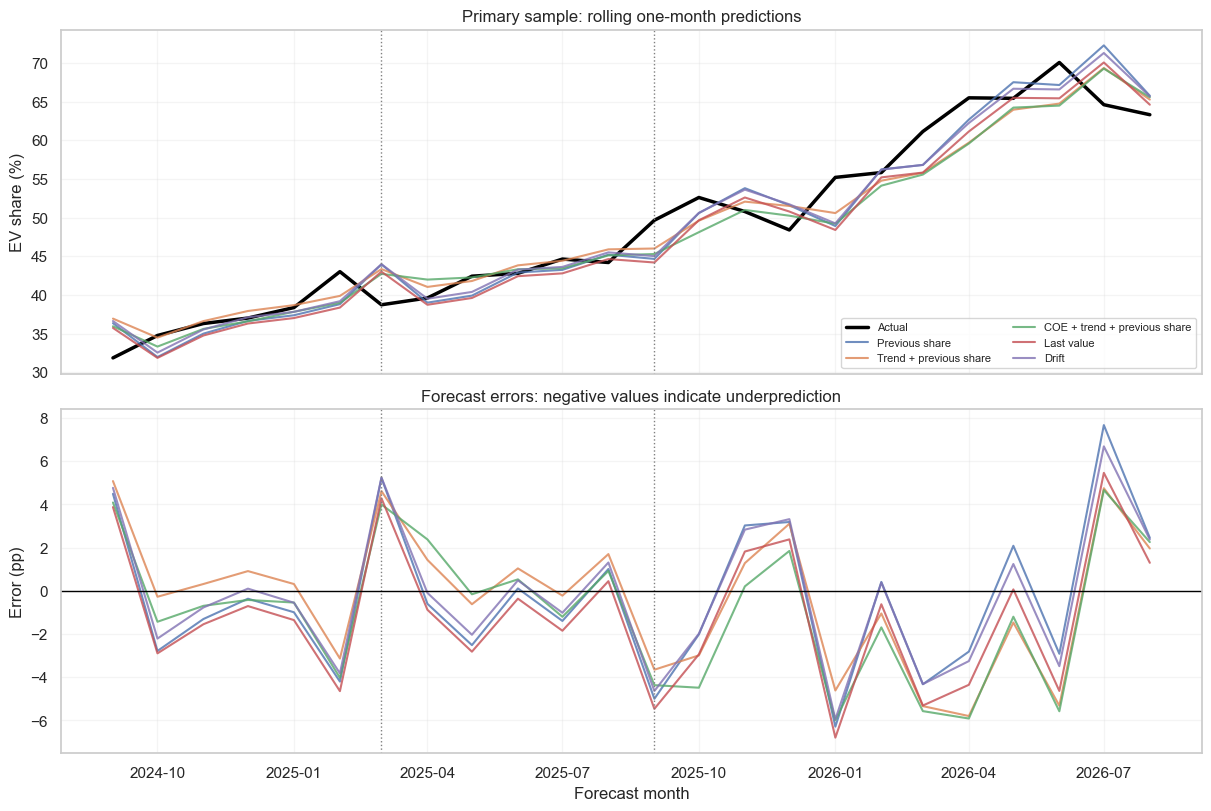

,model,COE + trend + previous share,Drift,Last value,Previous share,Trend + previous share
start,end,,,,,
2024-09,2025-02,-0.507,-0.415,-1.214,-0.861,0.535
2025-03,2025-08,1.077,0.648,-0.197,0.305,1.323
2025-09,2026-02,-2.416,-1.008,-1.939,-1.115,-1.321
2026-03,2026-08,-1.891,-0.128,-1.247,0.359,-1.871


In [29]:
FOCUS = ["Previous share","Trend + previous share","COE + trend + previous share","Last value","Drift"]
monthly_errors = {s:p.sub(forecast_regression_data.loc[p.index,"y_pct"],axis=0) for s,p in predictions.items()}
fig,axes = plt.subplots(2,1,figsize=(12,8),sharex=True,constrained_layout=True)
p = predictions["Primary 46 rows"]
axes[0].plot(p.index,forecast_regression_data.loc[p.index,"y_pct"],color="black",lw=2.5,label="Actual")
for model in FOCUS:
    axes[0].plot(p.index,p[model],label=model,alpha=0.8)
    axes[1].plot(p.index,monthly_errors["Primary 46 rows"][model],label=model,alpha=0.8)
for ax in axes:
    for months in [18,12]:ax.axvline(WINDOW_STARTS[months],color="grey",ls=":",lw=1)
    ax.grid(alpha=0.2)
axes[0].set(title="Primary sample: rolling one-month predictions",ylabel="EV share (%)")
axes[0].legend(fontsize=8,ncol=2)
axes[1].axhline(0,color="black",lw=1)
axes[1].set(title="Forecast errors: negative values indicate underprediction",ylabel="Error (pp)",xlabel="Forecast month")
plt.show()
bias_rows=[]
for sample,err in monthly_errors.items():
    for offset in range(0,24,6):
        part=err.iloc[offset:offset+6]
        for model in FOCUS:
            e=part[model]
            bias_rows.append({"sample":sample,"start":part.index.min().strftime("%Y-%m"),
                "end":part.index.max().strftime("%Y-%m"),"model":model,
                "mean_error_pp":e.mean(),"MAE_pp":e.abs().mean(),"under_months":int((e<0).sum()),
                "over_months":int((e>0).sum())})
bias_by_block=pd.DataFrame(bias_rows)
display(bias_by_block.query('sample == "Primary 46 rows"').pivot(index=["start","end"], columns="model",values="mean_error_pp").round(3))

In [30]:
stability = incremental_coe.groupby(["sample","comparison"],sort=False).agg(
    windows=("delta_RMSE_pp","size"),
    windows_COE_lowers_RMSE=("delta_RMSE_pp",lambda x:int((x<0).sum())),
    best_delta_RMSE_pp=("delta_RMSE_pp","min"),worst_delta_RMSE_pp=("delta_RMSE_pp","max")).reset_index()

row_sensitivity = performance.pivot(index=["test_months","model"],columns="sample",values="RMSE_pp")
row_sensitivity["delta_49_minus_46_pp"] = row_sensitivity["Secondary 49 rows"]-row_sensitivity["Primary 46 rows"]


coefficient_rows=[]
for sample,table in coefficients.items():
    for months,start in WINDOW_STARTS.items():
        sub=table.loc[table.forecast_month.ge(start) & table.model.isin(FOCUS[:3])]
        for (model,variable),group in sub.groupby(["model","variable"],sort=False):
            values=group.sort_values("forecast_month").coefficient.to_numpy()
            signs=np.sign(values[np.abs(values)>1e-10])
            coefficient_rows.append({"sample":sample,"test_months":months,"model":model,"variable":variable,
                "first":values[0],"last":values[-1],"min":values.min(),"max":values.max(),
                "sign_changes":int(np.sum(signs[1:]!=signs[:-1]))})
coefficient_stability=pd.DataFrame(coefficient_rows)
print("Primary 24-month coefficient summary; other windows and 49-row sample are in coefficient_stability.")
display(coefficient_stability.query('sample == "Primary 46 rows" and test_months == 24').drop(columns=["sample","test_months"]).round(5))

Primary 24-month coefficient summary; other windows and 49-row sample are in coefficient_stability.


,model,variable,first,last,min,max,sign_changes
0,COE + trend + previous share,Intercept,5.37054,7.76696,-0.76084,10.75065,4
1,COE + trend + previous share,premium_lag1_SGD_k,-0.06275,-0.04794,-0.07058,-0.01521,0
2,COE + trend + previous share,quota_lag1_k,1.31370,-2.82395,-2.82395,2.00906,1
3,COE + trend + previous share,bidding_ratio_lag1,2.72055,2.55302,0.89913,4.69639,0
4,COE + trend + previous share,trend_month,0.57848,0.74919,0.53036,0.74919,0
5,COE + trend + previous share,ev_share_lag1_pct,0.37322,0.54763,0.24561,0.63793,0
6,Previous share,Intercept,1.33683,0.98568,0.29493,2.08382,0
7,Previous share,ev_share_lag1_pct,0.97977,1.00264,0.93808,1.02736,0
8,Trend + previous share,Intercept,2.50954,1.99072,1.40859,4.12911,0
9,Trend + previous share,trend_month,0.53942,0.46005,0.38931,0.59950,0


## Section 16 · Sensitivity to individual months
Compare earlier and later halves of each forecast exercise. Re-score the rolling predictions after omitting one test month at a time, without changing the fits. These checks show whether a few months determine a ranking. Training residuals, forecast errors and coefficient paths remain separate.

In [31]:
# 16A: Performance stability across chronological halves.
if "regression_results" not in globals():
    raise RuntimeError("Run the Section 14 data preparation and evaluation cells before Section 16.")
robustness_models = ["Previous share", "Trend + previous share", "COE + trend + previous share",
              "Last value", "Drift"]
robustness_rows = []
robustness_errors = {}
for robustness_protocol, robustness_result in regression_results.items():
    robustness_predictions = robustness_result["predictions"][robustness_models].copy()
    robustness_actual = robustness_result["actual"].reindex(robustness_predictions.index)
    assert robustness_predictions.notna().all().all() and robustness_actual.notna().all()
    robustness_prediction_errors = robustness_predictions.sub(robustness_actual, axis=0)  # prediction minus actual, in pp
    robustness_errors[robustness_protocol] = robustness_prediction_errors
    robustness_midpoint = len(robustness_prediction_errors)//2
    for robustness_period, robustness_period_errors in [("All", robustness_prediction_errors), ("Earlier half", robustness_prediction_errors.iloc[:robustness_midpoint]),
                                 ("Later half", robustness_prediction_errors.iloc[robustness_midpoint:])]:
        for robustness_model in robustness_models:
            robustness_model_errors = robustness_period_errors[robustness_model]
            robustness_rmse = float(np.sqrt(np.mean(robustness_model_errors**2)))
            robustness_rows.append({"protocol":robustness_protocol,"period":robustness_period,
                "start":robustness_period_errors.index.min().strftime("%Y-%m"),"end":robustness_period_errors.index.max().strftime("%Y-%m"),
                "model":robustness_model,"months":len(robustness_model_errors),"RMSE_pp":robustness_rmse,
                "MAE_pp":float(robustness_model_errors.abs().mean()),"bias_pp":float(robustness_model_errors.mean()),
                "underpredicted_months":int((robustness_model_errors<0).sum()),
                "RMSE_minus_last_pp":robustness_rmse-float(np.sqrt(np.mean(robustness_period_errors["Last value"]**2))),
                "RMSE_minus_drift_pp":robustness_rmse-float(np.sqrt(np.mean(robustness_period_errors["Drift"]**2)))})
robustness_period_metrics = pd.DataFrame(robustness_rows)
for robustness_protocol in regression_results:
    print(robustness_protocol, "— negative RMSE differences favour the regression")
    display(robustness_period_metrics.query("protocol == @robustness_protocol").drop(columns="protocol").round(4))
# Removing a month from SCORING only: predictions and training fits do not change.
# This is not leave-one-out cross-validation and creates no independent test set.
robustness_sensitivity_rows = []
robustness_rolling_errors = robustness_errors["Rolling one month"]
for robustness_model in robustness_models[:3]:
    for robustness_baseline in robustness_models[3:]:
        robustness_deltas = []
        for robustness_month in robustness_rolling_errors.index:
            robustness_retained_errors = robustness_rolling_errors.drop(index=robustness_month)
            robustness_deltas.append(float(np.sqrt(np.mean(robustness_retained_errors[robustness_model]**2))-
                                    np.sqrt(np.mean(robustness_retained_errors[robustness_baseline]**2))))
        robustness_sensitivity_rows.append({"model":robustness_model,"baseline":robustness_baseline,
            "omissions":len(robustness_deltas),"min_delta_RMSE_pp":min(robustness_deltas),
            "max_delta_RMSE_pp":max(robustness_deltas),
            "omissions_model_has_lower_RMSE":int(np.sum(np.array(robustness_deltas)<0))})
robustness_scoring_sensitivity = pd.DataFrame(robustness_sensitivity_rows)
print("Rolling scoring sensitivity: does the comparison change when one test month is omitted?")
display(robustness_scoring_sensitivity.round(4))

Rolling one month — negative RMSE differences favour the regression


,period,start,end,model,months,RMSE_pp,MAE_pp,bias_pp,underpredicted_months,RMSE_minus_last_pp,RMSE_minus_drift_pp
0,All,2025-03,2026-08,Previous share,18,3.5713,2.9481,-0.1504,9,0.0340,0.1713
1,All,2025-03,2026-08,Trend + previous share,18,3.3569,2.8320,-0.6230,10,-0.1803,-0.0431
2,All,2025-03,2026-08,COE + trend + previous share,18,3.5839,2.9431,-1.0765,10,0.0466,0.1838
3,All,2025-03,2026-08,Last value,18,3.5372,2.8781,-1.1277,11,0.0000,0.1372
4,All,2025-03,2026-08,Drift,18,3.4000,2.8148,-0.1623,9,-0.1372,0.0000
5,Earlier half,2025-03,2025-11,Previous share,9,2.8916,2.3229,-0.2403,5,0.0495,0.1396
6,Earlier half,2025-03,2025-11,Trend + previous share,9,2.3972,1.9511,0.2858,4,-0.4449,-0.3548
7,Earlier half,2025-03,2025-11,COE + trend + previous share,9,2.6572,2.0284,-0.2436,4,-0.1849,-0.0948
8,Earlier half,2025-03,2025-11,Last value,9,2.8421,2.3192,-0.8637,6,0.0000,0.0901
9,Earlier half,2025-03,2025-11,Drift,9,2.7520,2.1832,0.0107,5,-0.0901,0.0000


Fixed conditional path — negative RMSE differences favour the regression


,period,start,end,model,months,RMSE_pp,MAE_pp,bias_pp,underpredicted_months,RMSE_minus_last_pp,RMSE_minus_drift_pp
15,All,2025-11,2026-08,Previous share,10,4.1339,3.4559,-0.6201,5,-5.8934,-0.7146
16,All,2025-11,2026-08,Trend + previous share,10,6.3934,5.3973,-4.3554,8,-3.6340,1.5448
17,All,2025-11,2026-08,COE + trend + previous share,10,7.7997,6.7184,-6.2849,8,-2.2277,2.9512
18,All,2025-11,2026-08,Last value,10,10.0274,8.6275,-7.4237,8,0.0000,5.1788
19,All,2025-11,2026-08,Drift,10,4.8485,3.9147,-1.8484,6,-5.1788,0.0000
20,Earlier half,2025-11,2026-03,Previous share,5,3.5404,2.9532,1.9920,1,-1.1710,0.0844
21,Earlier half,2025-11,2026-03,Trend + previous share,5,3.5993,3.1195,-1.0357,3,-1.1120,0.1434
22,Earlier half,2025-11,2026-03,COE + trend + previous share,5,4.6838,3.8337,-2.9668,3,-0.0275,1.2279
23,Earlier half,2025-11,2026-03,Last value,5,4.7113,4.0759,-1.6685,3,0.0000,1.2554
24,Earlier half,2025-11,2026-03,Drift,5,3.4560,2.7601,1.3726,1,-1.2554,0.0000


Rolling scoring sensitivity: does the comparison change when one test month is omitted?


,model,baseline,omissions,min_delta_RMSE_pp,max_delta_RMSE_pp,omissions_model_has_lower_RMSE
0,Previous share,Last value,18,-0.2215,0.1445,4
1,Previous share,Drift,18,0.0688,0.2115,0
2,Trend + previous share,Last value,18,-0.3284,0.0231,17
3,Trend + previous share,Drift,18,-0.2535,0.1567,13
4,COE + trend + previous share,Last value,18,-0.0860,0.1448,3
5,COE + trend + previous share,Drift,18,-0.0111,0.4099,1


Forecast-error correlation is descriptive only: 18 observations, no significance claim.


,model,months,lag1_error_correlation,largest_absolute_error_pp,largest_error_month
0,Previous share,18,-0.1192,7.6735,2026-07
1,Trend + previous share,18,0.1383,5.8005,2026-04
2,COE + trend + previous share,18,0.1699,5.9908,2026-01
3,Last value,18,-0.1273,6.8002,2026-01
4,Drift,18,-0.1283,6.6879,2026-07


Initial-training residuals use actual minus fitted; training ends February 2025.
Training residuals assess fit; they are not out-of-sample forecast accuracy.


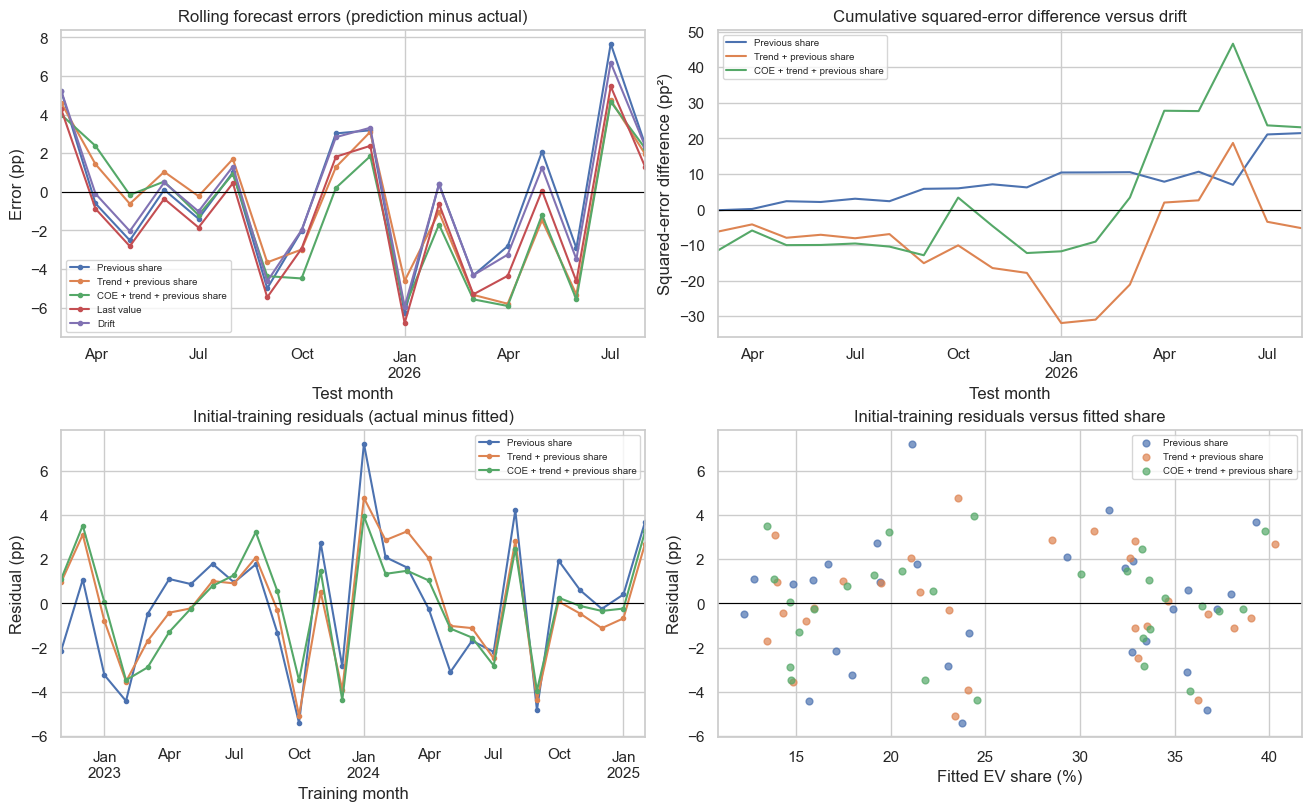

In [32]:
# 16B: Rolling forecast errors and initial-training residuals are kept separate.
import matplotlib.pyplot as plt
robustness_error_summary = []
for robustness_model in robustness_models:
    robustness_model_errors = robustness_rolling_errors[robustness_model]
    robustness_error_summary.append({"model":robustness_model,"months":len(robustness_model_errors),
        "lag1_error_correlation":robustness_model_errors.autocorr(lag=1),
        "largest_absolute_error_pp":robustness_model_errors.abs().max(),
        "largest_error_month":robustness_model_errors.abs().idxmax().strftime("%Y-%m")})
print("Forecast-error correlation is descriptive only: 18 observations, no significance claim.")
display(pd.DataFrame(robustness_error_summary).round(4))
robustness_training_data = forecast_regression_data.loc[REGRESSION_MODEL_START:REGRESSION_ROLL_START-pd.offsets.MonthBegin(1)].copy()
robustness_initial_residuals = pd.DataFrame(index=robustness_training_data.index)
robustness_initial_fitted = pd.DataFrame(index=robustness_training_data.index)
for robustness_model in robustness_models[:3]:
    robustness_features = regression_specifications[robustness_model]
    robustness_fit = RegressionLinearModel().fit(robustness_training_data[robustness_features], robustness_training_data["y_pct"])
    robustness_initial_fitted[robustness_model] = robustness_fit.predict(robustness_training_data[robustness_features])
    robustness_initial_residuals[robustness_model] = robustness_training_data["y_pct"]-robustness_initial_fitted[robustness_model]
print("Initial-training residuals use actual minus fitted; training ends February 2025.")
print("Training residuals assess fit; they are not out-of-sample forecast accuracy.")
robustness_figure, robustness_axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
robustness_rolling_errors.plot(ax=robustness_axes[0,0], marker=".")
robustness_axes[0,0].axhline(0,color="black",lw=0.8)
robustness_axes[0,0].set(title="Rolling forecast errors (prediction minus actual)",ylabel="Error (pp)",xlabel="Test month")
robustness_axes[0,0].legend(fontsize=7)
(robustness_rolling_errors[robustness_models[:3]].pow(2).sub(robustness_rolling_errors["Drift"].pow(2),axis=0).cumsum()).plot(ax=robustness_axes[0,1])
robustness_axes[0,1].axhline(0,color="black",lw=0.8)
robustness_axes[0,1].set(title="Cumulative squared-error difference versus drift",ylabel="Squared-error difference (pp²)",xlabel="Test month")
robustness_axes[0,1].legend(fontsize=7)
robustness_initial_residuals.plot(ax=robustness_axes[1,0],marker=".")
robustness_axes[1,0].axhline(0,color="black",lw=0.8)
robustness_axes[1,0].set(title="Initial-training residuals (actual minus fitted)",ylabel="Residual (pp)",xlabel="Training month")
robustness_axes[1,0].legend(fontsize=7)
for robustness_model in robustness_models[:3]:
    robustness_axes[1,1].scatter(robustness_initial_fitted[robustness_model],robustness_initial_residuals[robustness_model],label=robustness_model,alpha=0.7,s=24)
robustness_axes[1,1].axhline(0,color="black",lw=0.8)
robustness_axes[1,1].set(title="Initial-training residuals versus fitted share",xlabel="Fitted EV share (%)",ylabel="Residual (pp)")
robustness_axes[1,1].legend(fontsize=7)
plt.show()

Coefficients retain their original units; do not compare magnitudes across different variables.
Overlapping training windows are not independent samples; coefficient ranges are not confidence intervals.


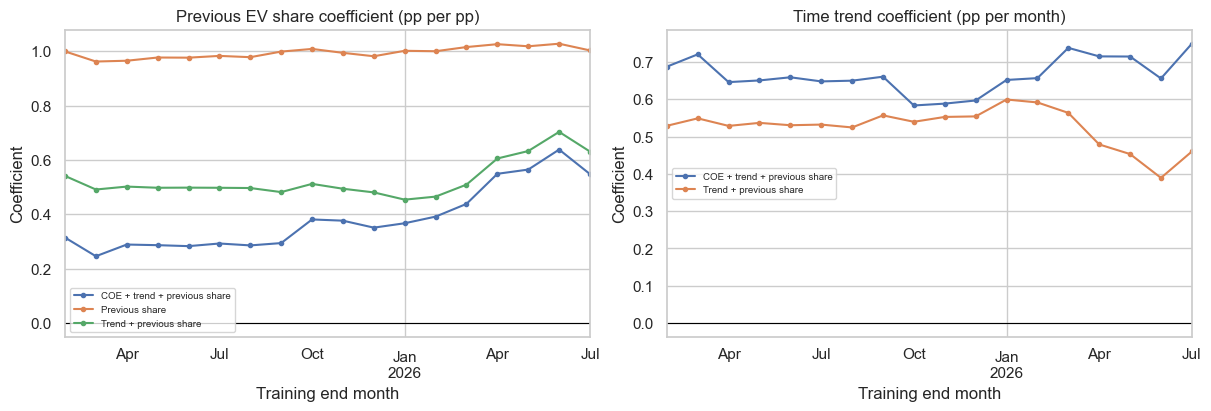

In [33]:
# 16C: Coefficient stability across the 18 expanding-window fits.
robustness_coefficients = regression_results["Rolling one month"]["coefficients"].copy()
robustness_coefficients = robustness_coefficients[robustness_coefficients["model"].isin(robustness_models[:3])]
robustness_stability_rows = []
for (robustness_model, robustness_variable), robustness_group in robustness_coefficients.groupby(["model","variable"],sort=False):
    robustness_group = robustness_group.sort_values("fit_through")
    robustness_values = robustness_group["coefficient"].to_numpy()
    assert len(robustness_values)==18
    robustness_nonzero_signs = np.sign(robustness_values[np.abs(robustness_values)>1e-10])
    robustness_stability_rows.append({"model":robustness_model,"variable":robustness_variable,
        "first":robustness_values[0],"last":robustness_values[-1],"minimum":robustness_values.min(),
        "maximum":robustness_values.max(),"last_minus_first":robustness_values[-1]-robustness_values[0],
        "sign_changes":int(np.sum(robustness_nonzero_signs[1:]!=robustness_nonzero_signs[:-1]))})
robustness_coefficient_stability = pd.DataFrame(robustness_stability_rows)

print("Coefficients retain their original units; do not compare magnitudes across different variables.")
print("Overlapping training windows are not independent samples; coefficient ranges are not confidence intervals.")
coefficient_figure, coefficient_axes = plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for robustness_axis, robustness_variable, robustness_label in zip(coefficient_axes,["ev_share_lag1_pct","trend_month"],
        ["Previous EV share coefficient (pp per pp)","Time trend coefficient (pp per month)"]):
    robustness_table = robustness_coefficients[robustness_coefficients["variable"].eq(robustness_variable)].pivot(index="fit_through",columns="model",values="coefficient")
    robustness_table.plot(ax=robustness_axis,marker=".")
    robustness_axis.axhline(0,color="black",lw=0.8)
    robustness_axis.set(title=robustness_label,xlabel="Training end month",ylabel="Coefficient")
    robustness_axis.legend(fontsize=7)
plt.show()

## Section 17 · Forecasting the level versus the monthly change
Fit the previous EV-share change alone, with lagged COE levels, and with lagged COE changes. Add each predicted change back to last month’s actual share and score in the same units and on the same months as the level models. A control regression verifies that rewriting the target alone, while retaining the same trend and previous-share predictors, gives equivalent forecasts.

In [34]:
change_frame = forecast_regression_data.copy(deep=True)
change_frame["dy_lag1_pp"] = change_frame["dy_pp"].shift(1)
# Predictors for month t use differences from t-2 to t-1, never t-1 to t.
change_coe = []
for feature in regression_coe:
    name = "change_"+feature
    change_frame[name] = change_frame[feature].diff()
    change_coe.append(name)
assert np.isfinite(change_frame.loc[REGRESSION_MODEL_START:].to_numpy()).all()
assert len(change_frame.loc[REGRESSION_MODEL_START:])==46
level_specs = {name:regression_specifications[name] for name in ["Previous share","Trend + previous share","COE + trend + previous share"]}
difference_specs = {"Previous change":["dy_lag1_pp"],
                    "Previous change + COE levels":["dy_lag1_pp"]+regression_coe,
                    "Previous change + COE changes":["dy_lag1_pp"]+change_coe}
window_starts = {24:pd.Timestamp("2024-09-01"),18:pd.Timestamp("2025-03-01"),12:pd.Timestamp("2025-09-01")}

def evaluate_changes(frame):
    rows, audits, coefficient_rows, controls = [], [], [], []
    for month in pd.date_range(window_starts[24],REGRESSION_END,freq="MS"):
        cutoff = month-pd.offsets.MonthBegin(1)
        train = frame.loc[REGRESSION_MODEL_START:cutoff]
        assert train.index.max()<month
        last = float(frame.loc[month,"ev_share_lag1_pct"])
        values={"Last value":last,"Drift":last+float(train.dy_pp.mean())}
        for target,specs in [("y_pct",level_specs),("dy_pp",difference_specs)]:
            for model,features in specs.items():
                x=train[features]
                design=np.column_stack([np.ones(len(x)),x.to_numpy()])
                if np.linalg.matrix_rank(design)!=design.shape[1]:
                    raise ValueError(f"Rank-deficient design: {model} at {month}")
                fit=RegressionLinearModel().fit(x,train[target])
                prediction=float(fit.predict(frame.loc[[month],features])[0])
                values[model]=prediction+(last if target=="dy_pp" else 0)
                for variable,value in zip(["Intercept"]+features,[fit.intercept_]+list(fit.coef_)):
                    coefficient_rows.append({"model":model,"forecast_month":month,"training_end":cutoff,
                        "target":target,"variable":variable,"coefficient":float(value)})
        features=level_specs["Trend + previous share"]
        equivalent_fit=RegressionLinearModel().fit(train[features],train.dy_pp)
        equivalent=last+float(equivalent_fit.predict(frame.loc[[month],features])[0])
        controls.append({"month":month,"level_prediction":values["Trend + previous share"],
            "equivalent_change_prediction":equivalent,
            "absolute_difference":abs(equivalent-values["Trend + previous share"])})
        rows.append({"month":month,**values})
        audits.append({"forecast_month":month,"training_start":train.index.min(),"training_end":cutoff,
            "training_rows":len(train),"latest_predictor_month":cutoff,
            "change_predictor_start_month":cutoff-pd.offsets.MonthBegin(1)})
    return pd.DataFrame(rows).set_index("month"),pd.DataFrame(audits),pd.DataFrame(coefficient_rows),pd.DataFrame(controls)

change_predictions, change_audit, change_coefficients, equivalence_control=evaluate_changes(change_frame)
np.testing.assert_allclose(equivalence_control.level_prediction,equivalence_control.equivalent_change_prediction,rtol=1e-10,atol=1e-9)
assert np.isfinite(change_predictions.to_numpy()).all()
shared_names = list(level_specs) + ["Last value","Drift"]
np.testing.assert_allclose(change_predictions[shared_names], predictions["Primary 46 rows"][shared_names], atol=1e-9)

In [35]:
change_metrics=[]
for months,start in window_starts.items():
    p=change_predictions.loc[start:]
    actual=change_frame.loc[p.index,"y_pct"]
    assert len(p)==months
    for model in p:
        e=p[model]-actual
        # Reconstruction identity: share forecast error equals monthly-change forecast error.
        delta_prediction=p[model]-change_frame.loc[p.index,"ev_share_lag1_pct"]
        np.testing.assert_allclose(e,delta_prediction-change_frame.loc[p.index,"dy_pp"],atol=1e-10)
        change_metrics.append({"test_months":months,"model":model,
            "RMSE_pp":float(np.sqrt(np.mean(e**2))),"MAE_pp":float(e.abs().mean()),
            "mean_error_pp":float(e.mean()),"under_months":int((e<0).sum()),
            "over_months":int((e>0).sum()),"outside_0_100":int(((p[model]<0)|(p[model]>100)).sum())})
change_performance=pd.DataFrame(change_metrics)
display(change_performance.pivot(index="model",columns="test_months",values=["RMSE_pp","MAE_pp"]).round(3))
change_pairs=[("Change history vs level history","Previous share","Previous change"),
              ("Change model vs trend and EV history","Trend + previous share","Previous change"),
              ("Change model vs drift","Drift","Previous change"),
              ("Add COE levels to change model","Previous change","Previous change + COE levels"),
              ("Add COE changes to change model","Previous change","Previous change + COE changes")]
change_pair_rows=[]
for months in window_starts:
    block=change_performance.query("test_months == @months").set_index("model")
    for label,reference,candidate in change_pairs:
        a,b=block.loc[reference],block.loc[candidate]
        change_pair_rows.append({"test_months":months,"comparison":label,
            "reference_RMSE_pp":a.RMSE_pp,"candidate_RMSE_pp":b.RMSE_pp,
            "delta_RMSE_pp":b.RMSE_pp-a.RMSE_pp,"delta_MAE_pp":b.MAE_pp-a.MAE_pp})
change_comparisons=pd.DataFrame(change_pair_rows)

RMSE_pp               MAE_pp              
test_months                        12     18     24     12     18     24
model                                                                   
COE + trend + previous share    4.153  3.584  3.337  3.649  2.943  2.675
Drift                           3.802  3.400  3.235  3.373  2.815  2.621
Last value                      4.025  3.537  3.385  3.430  2.878  2.785
Previous change                 3.849  3.400  3.236  3.519  2.898  2.680
Previous change + COE changes   3.969  3.483  3.301  3.605  3.073  2.803
Previous change + COE levels    3.960  3.589  3.458  3.488  2.988  2.763
Previous share                  4.006  3.571  3.403  3.517  2.948  2.801
Trend + previous share          3.820  3.357  3.160  3.445  2.832  2.542

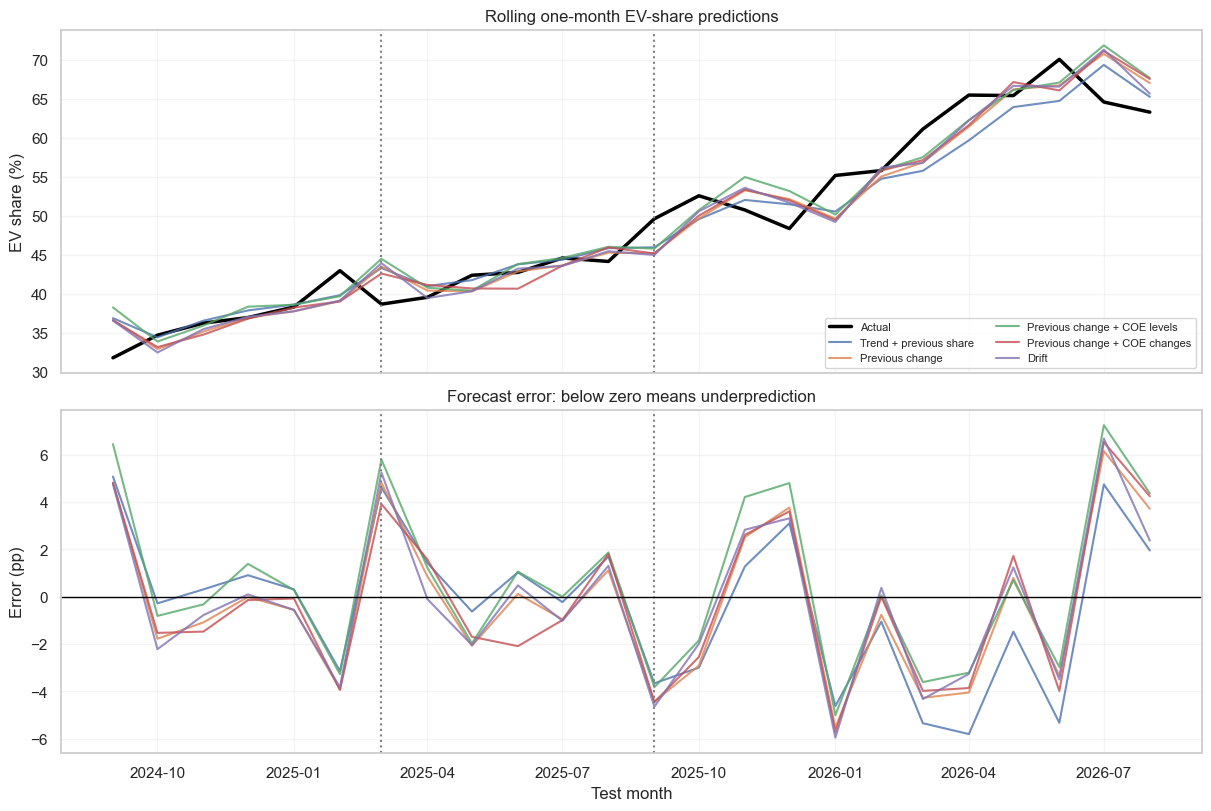

,model,Drift,Previous change,Previous change + COE changes,Previous change + COE levels,Trend + previous share
start,end,,,,,
2024-09,2025-02,-0.415,-0.415,-0.388,0.623,0.535
2025-03,2025-08,0.648,0.649,0.425,1.333,1.323
2025-09,2026-02,-1.008,-1.219,-1.079,-0.264,-1.321
2026-03,2026-08,-0.128,-0.161,0.117,0.425,-1.871


In [36]:
change_focus=["Trend + previous share","Previous change","Previous change + COE levels","Previous change + COE changes","Drift"]
change_errors=change_predictions.sub(change_frame.loc[change_predictions.index,"y_pct"],axis=0)
change_fig,change_axes=plt.subplots(2,1,figsize=(12,8),sharex=True,constrained_layout=True)
change_axes[0].plot(change_predictions.index,change_frame.loc[change_predictions.index,"y_pct"],color="black",lw=2.5,label="Actual")
for model in change_focus:
    change_axes[0].plot(change_predictions.index,change_predictions[model],label=model,alpha=0.8)
    change_axes[1].plot(change_errors.index,change_errors[model],label=model,alpha=0.8)
for ax in change_axes:
    ax.grid(alpha=0.2)
    for months in [18,12]:ax.axvline(window_starts[months],color="grey",ls=":")
change_axes[0].set(title="Rolling one-month EV-share predictions",ylabel="EV share (%)")
change_axes[0].legend(fontsize=8,ncol=2)
change_axes[1].axhline(0,color="black",lw=1)
change_axes[1].set(title="Forecast error: below zero means underprediction",ylabel="Error (pp)",xlabel="Test month")
plt.show()
change_bias_rows=[]
for offset in range(0,24,6):
    part=change_errors.iloc[offset:offset+6]
    for model in change_focus:
        e=part[model]
        change_bias_rows.append({"start":part.index.min().strftime("%Y-%m"),"end":part.index.max().strftime("%Y-%m"),
            "model":model,"bias_pp":e.mean(),"MAE_pp":e.abs().mean(),"under_months":int((e<0).sum())})
change_bias=pd.DataFrame(change_bias_rows)
display(change_bias.pivot(index=["start","end"],columns="model",values="bias_pp").round(3))

### Regression synthesis
- **What helped:** On the primary 18-month rolling test, trend and previous EV share together recorded RMSE of **3.357 percentage points**, compared with **8.203** for the tested COE-only regression. The chronological comparison also showed why the training mean is too easy a benchmark for a rising series.
- **Incremental COE value:** Adding the tested lagged COE-level variables to trend and previous share worsened RMSE in all three evaluation windows under both the 46-row and 49-row modelling samples. This is a specification-specific predictive finding, not evidence that COE policy has no effect.
- **Sensitivity to sample and window:** With 46 rows, trend plus previous share recorded RMSE of **3.160, 3.357 and 3.820 pp** over 24, 18 and 12 months; drift recorded **3.235, 3.400 and 3.802 pp**. With 49 rows, the corresponding regression errors were **3.180, 3.396 and 3.929 pp**, versus **3.229, 3.395 and 3.792 pp** for drift. Its small advantage is therefore sensitive to the training sample and evaluation window.
- **Other findings:** Predicting changes did not deliver a consistent gain. Underprediction was concentrated in particular later periods, rather than occurring in every month. Fixed-origin evaluation produced a different ranking.
- **Implication:** Retain trend plus previous EV share as a relatively simple candidate for monthly updating, alongside drift and last value. It is not consistently superior to drift. Trend and lagged share overlap, so coefficients do not establish separate causal effects. The following AR/ARX regressions examine other existing dynamic specifications; they were not included in the same 12-/24-month robustness exercise.


## Section 18: Autoregressive regressions and a smoothing comparator
The autoregressive (AR) and autoregressive-with-market-inputs (ARX) models are OLS regressions with intercepts. They predict monthly EV-share changes and add each prediction to the previous month's actual share. They are refitted each month on earlier modelling rows only. After the AR/ARX regressions, Holt is reported as a separate exponential-smoothing comparator applied directly to EV-share levels, using the longer history described in Section 9.

| Model | Specification |
|---|---|
| AR(1) on changes | Monthly EV-share change regressed on its previous-month change, with an intercept; an ARIMA(1,1,0)-type specification estimated by OLS. |
| ARX: six premium lags | AR(1) plus Category A and B premium changes at lags 1, 2 and 3. |
| ARX: Cat B lag 2 (chosen with hindsight) | AR(1) plus the Category B premium change two months earlier; this fixed specification was identified after examining the full dataset. |
| ARX: lag chosen each month by AIC or BIC | At each origin, compare eight candidates using training rows only: AR(1), six individual premium-lag extensions, and the six-premium-lag extension. The lowest-criterion candidate predicts the next month. |
| Holt linear trend | Exponential smoothing of EV-share level and trend, with weights optimised on training data and initial trend based on the first two observations. |

Training-only lag selection avoids using the next month's outcome for that selection step, but does not make the broader research exercise independent of earlier exploration. The intercept in an AR/ARX regression is the predicted monthly change when its lagged changes are zero, not necessarily average monthly growth.


In [37]:
# 18A: AR/ARX models with fixed or training-selected lags, evaluated on the shared 18-month window.
from sklearn.linear_model import LinearRegression as ForecastLinearRegression

FORECAST_TS_SPECS = {
    "AR(1) on changes": ["d_ev_share_lag1"],
    "ARX: six premium lags": ["d_ev_share_lag1"] + [f"d_{c}_lag{k}" for c in ("prem_a", "prem_b") for k in (1, 2, 3)],
    "ARX: Cat B lag 2 (chosen with hindsight)": ["d_ev_share_lag1", "d_prem_b_lag2"],
}
for name, feats in FORECAST_TS_SPECS.items():
    forecast_record("Time series", name, "+".join(feats), "change", forecast_walk_forward(ForecastLinearRegression, feats, "dy"))

# Training-only lag selection: each month, pick among 8 candidates by AIC/BIC on the training rows only.
FORECAST_LAG_CANDIDATES = {"AR(1) only": ["d_ev_share_lag1"]}
for cat in ("a", "b"):
    for k in (1, 2, 3):
        FORECAST_LAG_CANDIDATES[f"AR(1) + Cat {cat.upper()} lag {k}"] = ["d_ev_share_lag1", f"d_prem_{cat}_lag{k}"]
FORECAST_LAG_CANDIDATES["AR(1) + six premium lags"] = FORECAST_TS_SPECS["ARX: six premium lags"]

forecast_fixed = {name: [] for name in FORECAST_LAG_CANDIDATES}
forecast_selected = {"AIC": [], "BIC": []}
forecast_choices = []
for i in range(len(forecast_model_data) - FORECAST_N_TEST, len(forecast_model_data)):
    train, test = forecast_model_data.iloc[:i], forecast_model_data.iloc[[i]]
    ic, pred = {}, {}
    for name, feats in FORECAST_LAG_CANDIDATES.items():
        b, e, X = forecast_ols(train[feats], train["dy"])
        n, k = len(e), X.shape[1]
        ic[name] = {"AIC": n * np.log(e @ e / n) + 2 * k, "BIC": n * np.log(e @ e / n) + np.log(n) * k}
        pred[name] = float(test["ev_share_lag1"].iloc[0] + np.concatenate([[1.0], test[feats].to_numpy(float)[0]]) @ b)
        forecast_fixed[name].append(pred[name])
    row = {"test_month": forecast_model_data.index[i], "training_rows": len(train)}
    for crit in ("AIC", "BIC"):
        pick = min(ic, key=lambda m: ic[m][crit])
        forecast_selected[crit].append(pred[pick])
        row[f"{crit}_choice"] = pick
    forecast_choices.append(row)
forecast_choices = pd.DataFrame(forecast_choices)
np.testing.assert_allclose(forecast_fixed["AR(1) + Cat B lag 2"],
                           forecast_predictions[("Time series", "ARX: Cat B lag 2 (chosen with hindsight)", "d_ev_share_lag1+d_prem_b_lag2", "change")], atol=1e-9)
for crit in ("AIC", "BIC"):
    forecast_record("Time series", f"ARX: lag chosen each month by {crit}", "8 candidates", "change",
                pd.Series(forecast_selected[crit], index=forecast_test_idx))



### 18A. Holt smoothing comparator and shared performance tables
Holt is exponential smoothing, not a regression. Its existing results are shown alongside AR/ARX and the benchmarks on the same test months; it uses the longer training history stated in Section 9. The following diagnostic tables distinguish full-sample regression residuals from rolling forecast errors.

In [38]:
# Holt's linear trend forecasts EV-share levels; smoothing weights are optimised on training data.
def forecast_holt_fit(series):
    s = np.asarray(series, float)
    def run(params):
        alpha, beta = params
        level, trend, sse = s[0], s[1] - s[0], 0.0
        for obs in s[1:]:
            forecast = level + trend
            sse += (obs - forecast) ** 2
            new_level = alpha * obs + (1 - alpha) * forecast
            trend = beta * (new_level - level) + (1 - beta) * trend
            level = new_level
        return sse, level, trend
    best = forecast_optimize.minimize(lambda p: run(p)[0], x0=[0.5, 0.1], bounds=[(0.01, 0.99), (0.01, 0.99)], method="L-BFGS-B")
    if not best.success:
        raise RuntimeError("Holt optimisation failed: " + str(best.message))
    _, level, trend = run(best.x)
    return level, trend, best.x

forecast_holt_rows = []
for month in forecast_test_idx:
    level, trend, (alpha, beta) = forecast_holt_fit(forecast_data.loc[forecast_data.index < month, "ev_share"])
    forecast_holt_rows.append({"test_month": month, "prediction": level + trend, "alpha": alpha, "beta": beta})
forecast_holt = pd.DataFrame(forecast_holt_rows).set_index("test_month")
forecast_hw = forecast_holt[["alpha", "beta"]].to_numpy()
if (np.isclose(forecast_hw, 0.01) | np.isclose(forecast_hw, 0.99)).any():
    print("Note: at least one Holt smoothing weight sits on its bound.")
forecast_record("Time series", "Holt linear trend", "EV share history", "level", forecast_holt["prediction"])

forecast_res = pd.DataFrame(forecast_results)
forecast_ts_table = forecast_res[forecast_res["family"].isin(["Benchmark", "Time series"])][["family", "model", "RMSE", "MAE", "mean_error"]]
forecast_ts_table = forecast_ts_table.assign(beats_naive=forecast_ts_table["RMSE"] < FORECAST_NAIVE_RMSE, beats_drift=forecast_ts_table["RMSE"] < FORECAST_DRIFT_RMSE)
display(forecast_ts_table.round(3))

forecast_rmse = lambda p: float(np.sqrt(np.mean((np.asarray(p) - forecast_actual.to_numpy()) ** 2)))
forecast_candidates = pd.DataFrame({"fixed candidate": list(forecast_fixed), "RMSE": [forecast_rmse(p) for p in forecast_fixed.values()]})
forecast_candidates["rank"] = forecast_candidates["RMSE"].rank().astype(int)
display(forecast_candidates.sort_values("rank").round(3))
display(forecast_choices["AIC_choice"].value_counts().rename_axis("model chosen by training-window AIC").to_frame("months"))
print("BIC chooses the same model as AIC in", int((forecast_choices["AIC_choice"] == forecast_choices["BIC_choice"]).sum()), "of 18 months.")

,family,model,RMSE,MAE,mean_error,beats_naive,beats_drift
0,Benchmark,Naive (last value),3.537,2.878,-1.128,False,False
1,Benchmark,Naive + drift,3.400,2.815,-0.162,True,False
2,Time series,AR(1) on changes,3.400,2.898,-0.244,True,False
3,Time series,ARX: six premium lags,3.505,3.109,-0.502,True,False
4,Time series,ARX: Cat B lag 2 (chosen with hindsight),3.096,2.651,-0.317,True,True
5,Time series,ARX: lag chosen each month by AIC,3.319,2.852,-0.279,True,True
6,Time series,ARX: lag chosen each month by BIC,3.319,2.852,-0.279,True,True
7,Time series,Holt linear trend,3.457,2.922,-0.149,True,False


,fixed candidate,RMSE,rank
5,AR(1) + Cat B lag 2,3.096,1
2,AR(1) + Cat A lag 2,3.332,2
3,AR(1) + Cat A lag 3,3.339,3
6,AR(1) + Cat B lag 3,3.380,4
0,AR(1) only,3.400,5
4,AR(1) + Cat B lag 1,3.405,6
1,AR(1) + Cat A lag 1,3.413,7
7,AR(1) + six premium lags,3.505,8


,months
model chosen by training-window AIC,
AR(1) + Cat B lag 2,14
AR(1) + Cat A lag 2,4


BIC chooses the same model as AIC in 18 of 18 months.


**Result.** AR(1) on changes and drift have almost identical RMSE after rounding (3.400 pp), but their forecasts are not identical. Holt records 3.457 pp and the six-premium-lag ARX records 3.505 pp. The larger ARX specification performs worse here; greater estimation uncertainty in a short training sample is a possible explanation, not an established cause.

The fixed Category B lag-two model has the lowest RMSE among the eight retrospectively compared candidates (3.096 pp). Training-only AIC selection records 3.319 pp, about 2.4% below drift. However, its MAE is slightly higher than drift (2.852 versus 2.815 pp), so the improvement is specific to RMSE. The smaller gain under training-only selection illustrates sensitivity to the selection procedure; it does not quantify the amount of hindsight bias.

AIC selects Category B lag two in 14 months and Category A lag two in four. BIC makes the same selections in all 18 months. These repeated selections occur in strongly overlapping training samples and are not independent confirmation of a stable relationship.


### 18B. Residual and forecast-error diagnostics
The first table examines residuals from three AR/ARX specifications fitted on all 46 modelling rows:

- **Breusch–Godfrey:** residual autocorrelation at orders 1 and 3, allowing lagged dependent regressors.
- **Breusch–Pagan, Koenker version:** association between residual variance and the model's regressors.
- **Jarque–Bera:** departures from normality. Normality is not required to calculate point predictions, but distributional assumptions matter for conventional inference and prediction intervals.

The second table reports mean error, a conventional mean-error t-test, lag-one error autocorrelation and a three-lag Ljung–Box test for the benchmarks and time-series forecasts. Tree forecasts are excluded from this table. These are 18 out-of-sample forecast errors, distinct from the 46 full-sample fitted residuals. The conventional t-test is not adjusted for serial dependence, and the short samples limit all diagnostic conclusions.


In [39]:
# 18B: Residual checks on the full-sample fits, and checks on the 18 rolling forecast errors.
def forecast_breusch_godfrey(X, e, order):
    """LM test for leftover autocorrelation up to `order`; valid with a lagged dependent regressor."""
    lagged = np.column_stack([np.concatenate([np.zeros(j), e[:-j]]) for j in range(1, order + 1)])
    _, u, _ = forecast_ols(np.column_stack([X[:, 1:], lagged]), e)
    return forecast_stats.chi2.sf(len(e) * (1 - (u @ u) / np.sum((e - e.mean()) ** 2)), order)

def forecast_breusch_pagan(X, e):
    """LM test of constant residual variance against the model's regressors."""
    _, u, _ = forecast_ols(X[:, 1:], e**2)
    return forecast_stats.chi2.sf(len(e) * (1 - (u @ u) / np.sum((e**2 - np.mean(e**2)) ** 2)), X.shape[1] - 1)

def forecast_ljung_box(x, lags):
    x = np.asarray(x, float) - np.mean(x)
    acf = np.array([(x[k:] @ x[:-k]) / (x @ x) for k in range(1, lags + 1)])
    q = len(x) * (len(x) + 2) * np.sum(acf**2 / (len(x) - np.arange(1, lags + 1)))
    return forecast_stats.chi2.sf(q, lags), acf[0]

forecast_resid_rows = []
for name, feats in FORECAST_TS_SPECS.items():
    _, e, X = forecast_ols(forecast_model_data[feats], forecast_model_data["dy"])
    forecast_resid_rows.append({"model (full-sample fit, n = 46)": name,
        "Breusch-Godfrey p, order 1": forecast_breusch_godfrey(X, e, 1), "Breusch-Godfrey p, order 3": forecast_breusch_godfrey(X, e, 3),
        "Breusch-Pagan (Koenker) p": forecast_breusch_pagan(X, e), "Jarque-Bera p": forecast_stats.jarque_bera(e).pvalue})
display(pd.DataFrame(forecast_resid_rows).round(3))

forecast_error_rows = []
for (family, model, features, target), pred in forecast_predictions.items():
    if family == "Tree":
        continue
    err = (pred - forecast_actual).to_numpy()
    lb, r1 = forecast_ljung_box(err, 3)
    forecast_error_rows.append({"forecast": model, "mean_error_pp": err.mean(), "mean-error t-test p (unadjusted)": forecast_stats.ttest_1samp(err, 0).pvalue,
                            "lag-1 autocorrelation": r1, "Ljung-Box p, 3 lags": lb})
display(pd.DataFrame(forecast_error_rows).round(3))
print("Small p-values would flag a problem. Large ones, with 18-46 observations, are weak evidence of adequacy.")

,"model (full-sample fit, n = 46)","Breusch-Godfrey p, order 1","Breusch-Godfrey p, order 3",Breusch-Pagan (Koenker) p,Jarque-Bera p
0,AR(1) on changes,0.579,0.671,0.623,0.644
1,ARX: six premium lags,0.863,0.991,0.737,0.349
2,ARX: Cat B lag 2 (chosen with hindsight),0.156,0.546,0.473,0.467


,forecast,mean_error_pp,mean-error t-test p (unadjusted),lag-1 autocorrelation,"Ljung-Box p, 3 lags"
0,Naive (last value),-1.128,0.183,-0.112,0.950
1,Naive + drift,-0.162,0.846,-0.113,0.947
2,AR(1) on changes,-0.244,0.771,0.039,0.961
3,ARX: six premium lags,-0.502,0.558,-0.015,0.830
4,ARX: Cat B lag 2 (chosen with hindsight),-0.317,0.677,-0.026,0.868
5,ARX: lag chosen each month by AIC,-0.279,0.732,0.042,0.896
6,ARX: lag chosen each month by BIC,-0.279,0.732,0.042,0.896
7,Holt linear trend,-0.149,0.860,0.065,0.954


Small p-values would flag a problem. Large ones, with 18-46 observations, are weak evidence of adequacy.


**Interpretation.** The reported full-sample tests do not reject the tested residual assumptions at 5%. The forecast-error tests also do not reject zero mean error or the tested absence of autocorrelation. These are limited diagnostic findings, not proof of unbiased, independent or correctly distributed errors. In particular, 18 forecast errors provide little power to detect problems, and the conventional mean-error t-test depends on assumptions about those errors.


### 18C. In-sample Category B lag-two association
The selected Category B lag-two specification is examined using conventional OLS, HC1 heteroskedasticity-robust and Newey–West standard errors (Bartlett weights, three lags). The covariance estimates change the reported uncertainty, not the fitted coefficients. Reported p-values use a t reference distribution with residual degrees of freedom and are approximate in this small dynamic-regression sample.

Bonferroni and Holm adjustments are calculated separately for conventional and Newey–West p-values across the six individual premium-lag specifications. They cover that six-test family only, not the wider set of modelling decisions. Robust covariance estimates do not establish exogeneity or causality, and the adjustments used here do not correct a selected coefficient's magnitude for selection bias.


In [40]:
# 18C: The Cat B lag-2 coefficient with classical, heteroskedasticity-robust and Newey-West standard errors.
def forecast_inference(X_raw, y):
    beta, e, X = forecast_ols(X_raw, y)
    n, k = X.shape
    xtx_inverse = np.linalg.inv(X.T @ X)
    score_cross_product = (X * e[:, None]).T @ (X * e[:, None])
    se = {"OLS": np.sqrt(np.diag(xtx_inverse * (e @ e) / (n - k))),
          "HC1": np.sqrt(np.diag(xtx_inverse @ score_cross_product @ xtx_inverse) * n / (n - k))}
    lags = int(4 * (n / 100) ** (2 / 9))
    hac_score_cross_product = score_cross_product.copy()
    for j in range(1, lags + 1):
        g = (X[j:] * e[j:, None]).T @ (X[:-j] * e[:-j, None])
        hac_score_cross_product += (1 - j / (lags + 1)) * (g + g.T)
    se[f"Newey-West ({lags} lags)"] = np.sqrt(np.diag(xtx_inverse @ hac_score_cross_product @ xtx_inverse) * n / (n - k))
    pvals = {label: 2 * forecast_stats.t.sf(np.abs(beta / s), n - k) for label, s in se.items()}
    r2 = 1 - (e @ e) / np.sum((np.asarray(y) - np.mean(y)) ** 2)
    return beta, se, pvals, r2

forecast_lag2_features = FORECAST_TS_SPECS["ARX: Cat B lag 2 (chosen with hindsight)"]
forecast_beta, forecast_se, forecast_p, forecast_r2 = forecast_inference(forecast_model_data[forecast_lag2_features], forecast_model_data["dy"])
forecast_coef = pd.DataFrame({"coefficient": forecast_beta},
                         index=["Intercept (change when lagged changes are zero, pp)"] + forecast_lag2_features)
for label in forecast_se:
    forecast_coef[f"SE {label}"], forecast_coef[f"p {label}"] = forecast_se[label], forecast_p[label]
print(f"Full-sample fit on {len(forecast_model_data)} months; R-squared for monthly changes = {forecast_r2:.3f}")
display(forecast_coef.round(4))
print(f"A S$10,000 higher Cat B premium change two months earlier is associated with a {10 * forecast_beta[2]:.2f} pp change in this "
      "month's EV-share change, holding last month's change fixed. This association does not establish causation.")

# Adjust p-values across the six individual premium-lag specifications.
forecast_scan = []
for name, feats in FORECAST_LAG_CANDIDATES.items():
    if len(feats) == 2:
        b, _, p, _ = forecast_inference(forecast_model_data[feats], forecast_model_data["dy"])
        forecast_scan.append({"candidate": name, "premium_coefficient": b[2], "p_OLS": p["OLS"][2],
                          "p_Newey_West": [v for kk, v in p.items() if kk.startswith("Newey")][0][2]})
forecast_scan = pd.DataFrame(forecast_scan)
for col in ("p_OLS", "p_Newey_West"):
    forecast_scan[f"{col}_Bonferroni"] = (forecast_scan[col] * len(forecast_scan)).clip(upper=1)
    sorted_p_values = forecast_scan[col].sort_values()
    forecast_scan[f"{col}_Holm"] = (sorted_p_values * np.arange(len(sorted_p_values), 0, -1)).cummax().clip(upper=1).reindex(forecast_scan.index)
display(forecast_scan.round(4))
print("Corrections cover the six premium lags only; they do not account for the wider specification search.")

Full-sample fit on 46 months; R-squared for monthly changes = 0.194


,coefficient,SE OLS,p OLS,SE HC1,p HC1,SE Newey-West (3 lags),p Newey-West (3 lags)
"Intercept (change when lagged changes are zero, pp)",1.1751,0.4404,0.0107,0.4656,0.0154,0.4321,0.0094
d_ev_share_lag1,-0.0940,0.1372,0.4969,0.1393,0.5033,0.1158,0.4213
d_prem_b_lag2,-0.1597,0.0528,0.0042,0.0503,0.0028,0.0415,0.0004


A S$10,000 higher Cat B premium change two months earlier is associated with a -1.60 pp change in this month's EV-share change, holding last month's change fixed. This association does not establish causation.


,candidate,premium_coefficient,p_OLS,p_Newey_West,p_OLS_Bonferroni,p_OLS_Holm,p_Newey_West_Bonferroni,p_Newey_West_Holm
0,AR(1) + Cat A lag 1,0.0447,0.5616,0.4274,1.0000,1.0000,1.0000,0.8547
1,AR(1) + Cat A lag 2,-0.1921,0.0101,0.0111,0.0606,0.0505,0.0666,0.0555
2,AR(1) + Cat A lag 3,-0.1480,0.0721,0.0204,0.4329,0.2886,0.1224,0.0816
3,AR(1) + Cat B lag 1,0.0372,0.5262,0.4919,1.0000,1.0000,1.0000,0.8547
4,AR(1) + Cat B lag 2,-0.1597,0.0042,0.0004,0.0250,0.0250,0.0023,0.0023
5,AR(1) + Cat B lag 3,-0.0505,0.4314,0.2019,1.0000,1.0000,1.0000,0.6056


Corrections cover the six premium lags only; they do not account for the wider specification search.


**Result.** A SGD 10,000 larger monthly change in the Category B premium two months earlier is associated with approximately 1.60 pp lower monthly change in EV share, holding the previous EV-share change fixed. The estimated coefficient is −0.1597 pp per SGD 1,000 of premium change.

The negative association remains significant under the reported conventional, HC1 and Newey–West calculations (p = 0.0042, 0.0028 and 0.0004 respectively). Across the six premium-lag tests, both Bonferroni and Holm give approximately 0.0250 for its conventional p-value and 0.0023 for its Newey–West p-value. These are sensitivity checks on an in-sample association, not evidence of stability across periods or removal of exploratory selection effects.

Category A lag two has a negative coefficient of −0.1921, but does not pass the 5% threshold after the reported Holm adjustments (0.0505 using conventional inference; 0.0555 using Newey–West). The selected Category B model has in-sample R² = 0.194 for monthly changes; this is not forecast accuracy. None of these associations identifies a causal policy effect.


## Section 19: tree-based models
Three algorithms are evaluated: a decision tree, a random forest with 300 trees, and gradient boosting with 150 trees. Each uses COE features only, EV-history features only, or both, for each of two target specifications. This gives 18 specifications.

| Specification | Target | COE inputs | EV-history inputs |
|---|---|---|---|
| Level | EV-share level | 15 lagged level features | Previous two EV-share levels |
| Change | Monthly EV-share change | 12 lagged change features | Previous two monthly EV-share changes |

Both the target and predictor transformations change between these specifications. Their comparison therefore does not isolate the contribution of target differencing. Hyperparameters are held fixed across evaluations and no hyperparameter search is implemented. Nevertheless, selecting the lowest-error specification from the 18 comparisons uses the same evaluation period and remains exploratory.

For a change target, the predicted change is added to the previous month's actual EV share. Thus, “COE only” describes inputs to the change-prediction model; the final share prediction still uses the previous EV-share level.


In [41]:
# 19A: 3 algorithms x 3 feature sets x 2 targets = 18 tree specifications, scored on the same 18 rolling months.
from sklearn.tree import DecisionTreeRegressor as ForecastDecisionTree
from sklearn.ensemble import RandomForestRegressor as ForecastRandomForest
from sklearn.ensemble import GradientBoostingRegressor as ForecastGradientBoosting

# Hyperparameters are held fixed; no hyperparameter search is implemented.
FORECAST_TREES = {
    "Decision tree": lambda seed=FORECAST_SEED: ForecastDecisionTree(max_depth=3, min_samples_leaf=3, random_state=seed),
    "Random forest": lambda seed=FORECAST_SEED: ForecastRandomForest(n_estimators=300, min_samples_leaf=2, random_state=seed),
    "Gradient boosting": lambda seed=FORECAST_SEED: ForecastGradientBoosting(n_estimators=150, max_depth=2, learning_rate=0.05,
                                                                   subsample=0.8, random_state=seed),
}
FORECAST_FEATURE_SETS = {
    "y":  {"COE only": FORECAST_COE_LEVELS, "EV history only": FORECAST_EV_LEVELS, "COE + EV history": FORECAST_COE_LEVELS + FORECAST_EV_LEVELS},
    "dy": {"COE only": FORECAST_COE_CHANGES, "EV history only": FORECAST_EV_CHANGES, "COE + EV history": FORECAST_COE_CHANGES + FORECAST_EV_CHANGES},
}
FORECAST_TARGET_NAME = {"y": "level", "dy": "change"}

for target, sets in FORECAST_FEATURE_SETS.items():
    for set_name, feats in sets.items():
        for model_name, make in FORECAST_TREES.items():
            forecast_record("Tree", model_name, set_name, FORECAST_TARGET_NAME[target], forecast_walk_forward(make, feats, target))

forecast_res = pd.DataFrame(forecast_results)
forecast_tree_table = (forecast_res[forecast_res["family"] == "Tree"]
                   .pivot_table(index=["target", "features"], columns="model", values="RMSE")
                   .reindex(columns=list(FORECAST_TREES))
                   .reindex(["COE only", "EV history only", "COE + EV history"], level="features")
                   .sort_index(level="target", ascending=False, sort_remaining=False))
print(f"Rolling one-step RMSE, percentage points. Benchmarks: naive {FORECAST_NAIVE_RMSE:.3f}, drift {FORECAST_DRIFT_RMSE:.3f}.")
display(forecast_tree_table.round(3))
forecast_tree_res = forecast_res[forecast_res["family"] == "Tree"].assign(
    beats_naive=lambda d: d["RMSE"] < FORECAST_NAIVE_RMSE, beats_drift=lambda d: d["RMSE"] < FORECAST_DRIFT_RMSE,
    outside_0_100=[int(((forecast_predictions[("Tree", m, f, t)] < 0) | (forecast_predictions[("Tree", m, f, t)] > 100)).sum())
                   for m, f, t in zip(forecast_res.loc[forecast_res["family"] == "Tree", "model"],
                                      forecast_res.loc[forecast_res["family"] == "Tree", "features"],
                                      forecast_res.loc[forecast_res["family"] == "Tree", "target"])])
print("Change-target trees beating both benchmarks:",
      int(forecast_tree_res.query("target == 'change'")[["beats_naive", "beats_drift"]].all(axis=1).sum()), "of 9;",
      "level-target trees beating naive:", int(forecast_tree_res.query("target == 'level'")["beats_naive"].sum()), "of 9;",
      "predictions outside 0-100:", int(forecast_tree_res["outside_0_100"].sum()))

Rolling one-step RMSE, percentage points. Benchmarks: naive 3.537, drift 3.400.


model                    Decision tree  Random forest  Gradient boosting
target features                                                         
level  COE only                  6.045          6.979              6.003
       EV history only           4.902          5.075              4.694
       COE + EV history          7.311          6.492              5.328
change COE only                  3.364          3.280              2.983
       EV history only           4.135          3.809              4.096
       COE + EV history          3.386          3.271              3.002

Change-target trees beating both benchmarks: 6 of 9; level-target trees beating naive: 0 of 9; predictions outside 0-100: 0


**Result.** All nine tested level-target specifications have higher RMSE than the last-value benchmark (3.537 pp); the lowest level-target RMSE is 4.694 pp. All six change-target specifications containing COE features have lower RMSE than both last value and drift (3.400 pp), with RMSE ranging from 2.983 to 3.386 pp. The three EV-history-only change models have RMSE of 3.809–4.135 pp.

Within the change-target models, adding COE features to the EV-history inputs lowers RMSE for all three algorithms. Within the level-target models, it raises RMSE for all three. The change-target specifications also outperform their corresponding level-target specifications, but both targets and input transformations differ. These results cannot be attributed to target differencing alone.

Gradient boosting with COE-change inputs records the lowest RMSE among the tested trees in this window. This is an observed ranking, not established superiority on future data. Appendix C reports supplementary exploratory forecast comparisons.


### 19B. Does the result depend on the random seed?

Random forests and gradient boosting with subsample=0.8 use randomness, so their results can vary with the random seed. The four stochastic COE-based change-target specifications are evaluated with 20 additional seeds while keeping the data, evaluation period and other settings unchanged.

In [42]:
# 19B: Evaluate sensitivity to the random seed while holding all other settings fixed.
forecast_seed_specs = [("Gradient boosting", "COE only"), ("Gradient boosting", "COE + EV history"),
                   ("Random forest", "COE only"), ("Random forest", "COE + EV history")]
forecast_seeds = list(range(20))
forecast_seed_rows = []
for model_name, set_name in forecast_seed_specs:
    feats = FORECAST_FEATURE_SETS["dy"][set_name]
    scores = np.array([forecast_score(forecast_walk_forward(lambda s=s: FORECAST_TREES[model_name](s), feats, "dy"))["RMSE"]
                       for s in forecast_seeds])
    forecast_seed_rows.append({"model": model_name, "features (change target)": set_name,
        f"RMSE, seed {FORECAST_SEED}": forecast_score(forecast_predictions[("Tree", model_name, set_name, "change")])["RMSE"],
        "min": scores.min(), "median": np.median(scores), "max": scores.max(),
        "seeds beating naive": f"{int((scores < FORECAST_NAIVE_RMSE).sum())}/{len(scores)}",
        "seeds beating drift": f"{int((scores < FORECAST_DRIFT_RMSE).sum())}/{len(scores)}"})
forecast_seed_table = pd.DataFrame(forecast_seed_rows)
display(forecast_seed_table.round(3))
print(f"Seeds 0-{forecast_seeds[-1]} plus {FORECAST_SEED}; every other setting unchanged.")

,model,features (change target),"RMSE, seed 6312",min,median,max,seeds beating naive,seeds beating drift
0,Gradient boosting,COE only,2.983,2.794,2.988,3.185,20/20,20/20
1,Gradient boosting,COE + EV history,3.002,2.929,3.090,3.334,20/20,20/20
2,Random forest,COE only,3.280,3.152,3.170,3.254,20/20,20/20
3,Random forest,COE + EV history,3.271,3.161,3.205,3.301,20/20,20/20


Seeds 0-19 plus 6312; every other setting unchanged.


**Seed sensitivity.** Each of the four stochastic COE-based change specifications has lower RMSE than both benchmarks for all 20 additional seeds, as well as the original seed. The additional-seed RMSE ranges overlap, so the original ranking should not be treated as fixed. These checks assess algorithm randomness on the same observations; they do not validate performance across different economic periods, training samples or forecast horizons.


### 19C. Extrapolation limits and descriptive feature importance
Under the fitted settings, a decision tree predicts averages of training targets within leaves, and a random forest averages these tree predictions. Their level predictions cannot exceed the highest training target. The dotted line shows this training maximum at each rolling origin. Gradient boosting does not share exactly this restriction, although the tested level specification also struggles with the rising share. Reconstructing a level from the previous share and a predicted change permits predictions above earlier training levels; it does not guarantee accuracy.

The importance table shows the six highest-ranked features from one change-target random forest fitted on all 46 modelling rows. Importance is the normalised reduction in training impurity attributed to each feature, not a measure of out-of-sample forecasting value or causal influence. The printed group total sums all 12 COE features, which receive approximately 92.9% of this importance, compared with 7.1% for the two EV-history features. Unequal feature counts, correlated inputs and full-sample fitting limit interpretation. This does not mean that COE explains 92.9% of EV adoption.


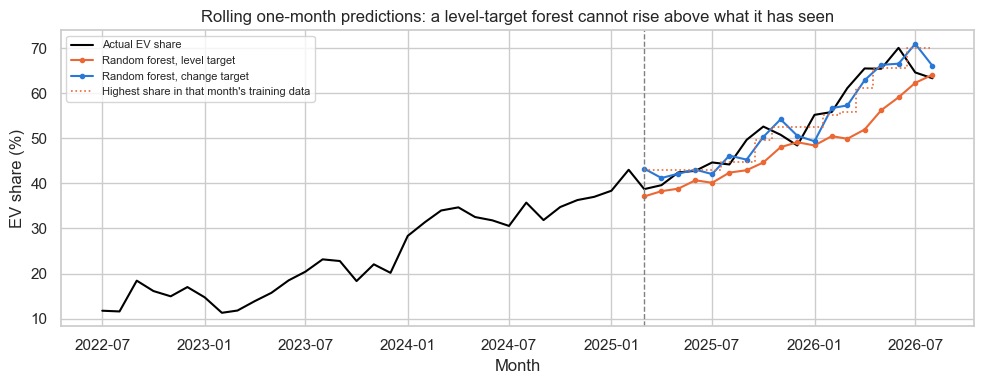

,full_sample_impurity_importance
d_prem_b_lag2,0.286
d_bid_to_quota_lag2,0.138
d_prem_a_lag2,0.099
d_prem_a_lag3,0.086
d_bid_to_quota_lag1,0.051
d_bid_to_quota_lag3,0.049


Share of impurity importance on the 12 COE features: 92.9%; on the 2 EV-history features: 7.1%.


In [43]:
# 19C: Level vs change target, shown for the same random forest; full-sample split importance (descriptive only).
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(forecast_data.index, forecast_data["ev_share"], color="black", label="Actual EV share")
for target, colour in [("level", "#eb6834"), ("change", "#2a78d6")]:
    p = forecast_predictions[("Tree", "Random forest", "COE + EV history", target)]
    ax.plot(p.index, p, color=colour, marker="o", markersize=3, label=f"Random forest, {target} target")
forecast_train_max = pd.Series([forecast_model_data["y"].iloc[:i].max() for i in range(len(forecast_model_data) - FORECAST_N_TEST, len(forecast_model_data))], index=forecast_test_idx)
ax.step(forecast_train_max.index, forecast_train_max, where="mid", color="#eb6834", linestyle=":", linewidth=1.2,
        label="Highest share in that month's training data")
ax.axvline(forecast_test_idx.min(), color="grey", linestyle="--", linewidth=1)
ax.set(title="Rolling one-month predictions: a level-target forest cannot rise above what it has seen",
       ylabel="EV share (%)", xlabel="Month")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

forecast_rf_full = FORECAST_TREES["Random forest"]().fit(forecast_model_data[FORECAST_COE_CHANGES + FORECAST_EV_CHANGES], forecast_model_data["dy"])
forecast_importance = pd.Series(forecast_rf_full.feature_importances_, index=FORECAST_COE_CHANGES + FORECAST_EV_CHANGES).sort_values(ascending=False)
display(forecast_importance.head(6).to_frame("full_sample_impurity_importance").round(3))
print(f"Share of impurity importance on the 12 COE features: {forecast_importance[FORECAST_COE_CHANGES].sum():.1%}; "
      f"on the 2 EV-history features: {forecast_importance[FORECAST_EV_CHANGES].sum():.1%}.")

## Section 20: Consolidated model comparisons
Section 20A refits the existing model specifications for the fixed-origin conditional evaluation. Section 20B consolidates the rolling and fixed-origin results. No new model specifications are introduced. Rolling one-month predictions and fixed-origin conditional paths are reported separately. Shared test dates do not imply identical training samples or predictor availability. Rankings are descriptive and reflect the explored specifications, not an untouched final model-selection test.

### 20A. Fixed-origin conditional evaluation over ten months
Models are fitted using data available through October 2025 and evaluated over November 2025–August 2026 without updating EV outcomes. Tree and AR/ARX fits use 36 complete modelling rows from November 2022; Holt uses 40 EV-share observations from July 2022. These are the same evaluation dates as Section 13, but the usable training samples and predictor timings differ.

Where EV-history inputs are required, later values come from each model's own recursive predictions. COE inputs use subsequently observed market information where applicable. Thus, these are fixed-origin conditional predictions, not ten-month-ahead forecasts that could all have been issued using only information available in October 2025. The evaluation period has already informed the broader modelling exercise.


,model,RMSE_pp,MAE_pp,mean_error_pp,beats_last_training_value
0,"Gradient boosting, COE only (change)",3.738,2.967,-1.140,True
1,"Decision tree, COE + EV history (change)",3.799,2.995,-0.954,True
2,"Decision tree, COE only (change)",3.799,2.995,-0.954,True
3,"Gradient boosting, COE + EV history (change)",3.882,3.087,-1.285,True
4,"Random forest, COE only (change)",3.960,3.170,-0.871,True
5,"Random forest, EV history only (change)",3.985,3.419,0.999,True
6,ARX: lag chosen by training AIC (AR(1) + Cat B...,4.173,3.380,-1.718,True
7,ARX: Cat B lag 2 (chosen with hindsight),4.173,3.380,-1.718,True
8,"Decision tree, EV history only (change)",4.181,3.496,-0.313,True
9,"Random forest, COE + EV history (change)",4.196,3.352,-1.270,True


Last-training-value benchmark: 10.027 pp (Section 13 reports 10.027 pp for the same benchmark).
Negative mean error = under-prediction. Same test dates as Section 13; training samples and predictor timings differ. Market-dependent paths are conditional.


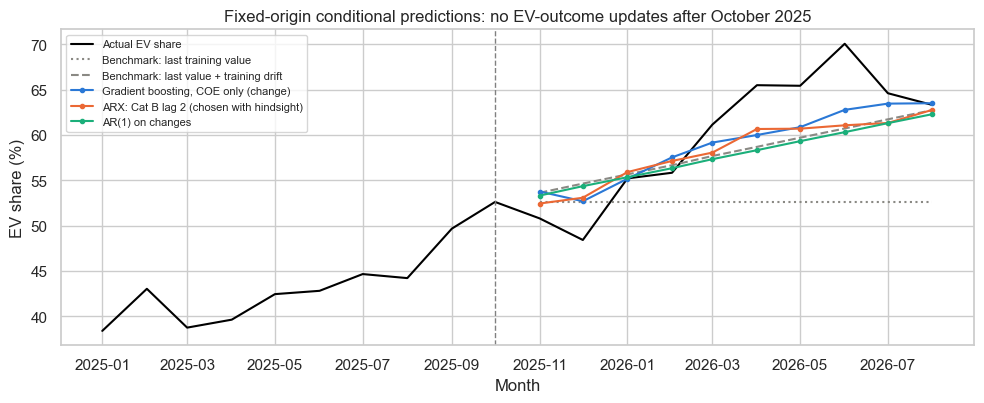

In [44]:
# 20A: Fixed-origin conditional evaluation: 36 complete modelling rows through Oct 2025; test Nov 2025 - Aug 2026,
# using no EV-share outcome after Oct 2025 (EV-history inputs come from each model's own predictions).
FORECAST_FIXED_ORIGIN_TRAIN_END = pd.Timestamp("2025-10-01")
forecast_fixed_origin_months = pd.date_range("2025-11-01", "2026-08-01", freq="MS")
forecast_fixed_origin_training_data = forecast_model_data.loc[forecast_model_data.index <= FORECAST_FIXED_ORIGIN_TRAIN_END]
forecast_fixed_origin_actual = forecast_data.loc[forecast_fixed_origin_months, "ev_share"]
assert len(forecast_fixed_origin_training_data) == 36 and len(forecast_fixed_origin_months) == 10   # 40 input months, minus 4 used to build lags

def forecast_fixed_origin_path(predict_row, target):
    """Recursive 10-month path. COE inputs are observed lags (as Section 13 uses observed market inputs);
    EV-history inputs come from the simulated path, never from test-period outcomes."""
    path = forecast_data["ev_share"].loc[:FORECAST_FIXED_ORIGIN_TRAIN_END].copy()
    for m in forecast_fixed_origin_months:
        row = forecast_model_data.loc[[m]].copy()
        s1, s2, s3 = path.iloc[-1], path.iloc[-2], path.iloc[-3]
        row["ev_share_lag1"], row["ev_share_lag2"] = s1, s2
        row["d_ev_share_lag1"], row["d_ev_share_lag2"] = s1 - s2, s2 - s3
        p = predict_row(row)
        path.loc[m] = s1 + p if target == "dy" else p
    return path.loc[forecast_fixed_origin_months]

forecast_fixed_origin_results = {}
for target, sets in FORECAST_FEATURE_SETS.items():
    for set_name, feats in sets.items():
        for model_name, make in FORECAST_TREES.items():
            fit = make().fit(forecast_fixed_origin_training_data[feats], forecast_fixed_origin_training_data[target])
            forecast_fixed_origin_results[f"{model_name}, {set_name} ({FORECAST_TARGET_NAME[target]})"] = forecast_fixed_origin_path(
                lambda r, fit=fit, feats=feats: fit.predict(r[feats])[0], target)
for name, feats in FORECAST_TS_SPECS.items():
    fit = ForecastLinearRegression().fit(forecast_fixed_origin_training_data[feats], forecast_fixed_origin_training_data["dy"])
    forecast_fixed_origin_results[name] = forecast_fixed_origin_path(lambda r, fit=fit, feats=feats: fit.predict(r[feats])[0], "dy")
forecast_fixed_origin_information_criteria = {}
for name, feats in FORECAST_LAG_CANDIDATES.items():
    _, e, X = forecast_ols(forecast_fixed_origin_training_data[feats], forecast_fixed_origin_training_data["dy"])
    forecast_fixed_origin_information_criteria[name] = len(e) * np.log(e @ e / len(e)) + 2 * X.shape[1]
forecast_fixed_origin_selected_model = min(forecast_fixed_origin_information_criteria, key=forecast_fixed_origin_information_criteria.get)
fit = ForecastLinearRegression().fit(forecast_fixed_origin_training_data[FORECAST_LAG_CANDIDATES[forecast_fixed_origin_selected_model]], forecast_fixed_origin_training_data["dy"])
forecast_fixed_origin_results[f"ARX: lag chosen by training AIC ({forecast_fixed_origin_selected_model})"] = forecast_fixed_origin_path(
    lambda r: fit.predict(r[FORECAST_LAG_CANDIDATES[forecast_fixed_origin_selected_model]])[0], "dy")
level, trend, _ = forecast_holt_fit(forecast_data.loc[:FORECAST_FIXED_ORIGIN_TRAIN_END, "ev_share"])
forecast_fixed_origin_results["Holt linear trend"] = pd.Series(level + trend * np.arange(1, 11), index=forecast_fixed_origin_months)
forecast_last = float(forecast_data.loc[FORECAST_FIXED_ORIGIN_TRAIN_END, "ev_share"])
forecast_fixed_origin_results["Benchmark: last training value"] = pd.Series(forecast_last, index=forecast_fixed_origin_months)
forecast_fixed_origin_results["Benchmark: last value + training drift"] = pd.Series(
    forecast_last + forecast_fixed_origin_training_data["dy"].mean() * np.arange(1, 11), index=forecast_fixed_origin_months)

forecast_fixed_origin_table = pd.DataFrame([{"model": n, "RMSE_pp": float(np.sqrt(np.mean((p - forecast_fixed_origin_actual) ** 2))),
                                "MAE_pp": float(np.mean(np.abs(p - forecast_fixed_origin_actual))), "mean_error_pp": float(np.mean(p - forecast_fixed_origin_actual))}
                               for n, p in forecast_fixed_origin_results.items()]).sort_values("RMSE_pp").reset_index(drop=True)
forecast_fixed_origin_last_value_rmse = float(forecast_fixed_origin_table.loc[forecast_fixed_origin_table["model"] == "Benchmark: last training value", "RMSE_pp"].iloc[0])
forecast_fixed_origin_table["beats_last_training_value"] = forecast_fixed_origin_table["RMSE_pp"] < forecast_fixed_origin_last_value_rmse
display(forecast_fixed_origin_table.round(3))
print(f"Last-training-value benchmark: {forecast_fixed_origin_last_value_rmse:.3f} pp (Section 13 reports 10.027 pp for the same benchmark).")
print("Negative mean error = under-prediction. Same test dates as Section 13; training samples and predictor timings differ. Market-dependent paths are conditional.")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(forecast_data.loc["2025-01":].index, forecast_data.loc["2025-01":, "ev_share"], color="black", label="Actual EV share")
for name, colour, style in [("Benchmark: last training value", "#8a8984", ":"), ("Benchmark: last value + training drift", "#8a8984", "--"),
                            ("Gradient boosting, COE only (change)", "#2a78d6", "-"), ("ARX: Cat B lag 2 (chosen with hindsight)", "#eb6834", "-"),
                            ("AR(1) on changes", "#1baf7a", "-")]:
    ax.plot(forecast_fixed_origin_results[name].index, forecast_fixed_origin_results[name], color=colour, linestyle=style, marker="o" if style == "-" else None, markersize=3, label=name)
ax.axvline(FORECAST_FIXED_ORIGIN_TRAIN_END, color="grey", linestyle="--", linewidth=1)
ax.set(title="Fixed-origin conditional predictions: no EV-outcome updates after October 2025", ylabel="EV share (%)", xlabel="Month")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

**Result.** Gradient boosting with COE-change inputs records the lowest RMSE among the specifications in this section (3.738 pp), compared with 4.849 pp for drift and 10.027 pp for the last training value. All six COE-based change-target tree specifications outperform drift on RMSE. All nine level-target trees have higher RMSE than the last training value (10.877–14.821 pp). Target, predictors and algorithms vary, so these differences cannot be attributed solely to differencing.

The fixed Category B lag-two ARX records 4.173 pp. Training-only AIC at the October 2025 cutoff selects that same specification and produces identical predictions; these two table entries are not independent supporting results. AR(1) on changes and the six-premium-lag ARX record 5.026 and 5.554 pp respectively, while Holt records 4.338 pp.

Section 13's lowest-error market-indicator regression records 14.45 pp, but it is not the strongest regression subsequently examined in this notebook. Section 14's previous-share regression records 4.134 pp on the fixed ten-month exercise, compared with 3.738 pp for the lowest-error tree here. These are retrospective comparisons on shared evaluation dates, not evidence that an algorithm is generally superior.


### 20B. Shared overview of existing performance results
Errors are in percentage points; mean error is prediction minus actual. The training-mean benchmark in these overview tables uses the 36-row/28–45-row forecasting sample; Section 13 separately reports its original 40-row training-mean benchmark.

In [45]:
# Model descriptions used in the performance-comparison tables.
comparison_regression_descriptions = {
    "COE only": "Previous-month mean premium, total quota and bids per quota",
    "COE + trend": "Previous-month COE measures plus calendar trend",
    "COE + previous share": "Previous-month COE measures and EV share",
    "COE + trend + previous share": "Previous-month COE measures and EV share, plus calendar trend",
    "Trend only": "Calendar trend",
    "Previous share": "Regression on previous-month EV share, with an intercept",
    "Trend + previous share": "Calendar trend and previous-month EV share, with an intercept",
    "Training mean": "Mean EV share in the available training sample",
    "Last value": "Previous month's actual EV share",
    "Drift": "Previous month's actual EV share plus average training-period monthly change",
}

def comparison_forecast_description(model, features, target):
    if model == "Holt linear trend":
        return "Exponential smoothing of EV-share level and trend"
    if model == "AR(1) on changes":
        return "Previous-month EV-share change; predicted change added to previous actual share"
    if model == "ARX: six premium lags":
        return "Previous EV-share change plus Category A and B premium changes at lags 1–3"
    if model == "ARX: Cat B lag 2 (chosen with hindsight)":
        return "Previous EV-share change plus Category B premium change at lag 2; retrospectively chosen"
    if model.startswith("ARX: lag chosen each month"):
        return "Training-only selection among eight AR/ARX candidates; target: monthly change"
    feature_text = {
        ("COE only", "level"): "Lagged COE levels; target: EV share",
        ("EV history only", "level"): "Previous two EV shares; target: EV share",
        ("COE + EV history", "level"): "Lagged COE levels and previous two EV shares; target: EV share",
        ("COE only", "change"): "Lagged COE changes; target: monthly EV-share change",
        ("EV history only", "change"): "Previous two EV-share changes; target: monthly EV-share change",
        ("COE + EV history", "change"): "Lagged COE changes and previous two EV-share changes; target: monthly EV-share change",
    }
    return feature_text[(features, target)]

def comparison_fixed_information(model):
    descriptions = {
        "Training mean": "Fixed mean of training EV shares through October 2025",
        "Last value": "October 2025 actual EV share, held constant",
        "Drift": "October 2025 EV share plus accumulated average training-period monthly change",
        "Trend only": "Calendar trend extrapolated from the fixed training fit",
        "Previous share": "Own previous EV-share prediction after the first test month",
        "Trend + previous share": "Calendar trend and own previous EV-share prediction after the first test month",
        "COE only": "Subsequently observed previous-month COE measures; no EV-history predictor",
        "COE + trend": "Subsequently observed previous-month COE measures and calendar trend",
        "COE + previous share": "Subsequently observed previous-month COE measures and own recursive EV-share predictions",
        "COE + trend + previous share": "Subsequently observed previous-month COE measures, calendar trend and own recursive EV-share predictions",
        "Holt linear trend": "Level and trend fitted through October 2025, extrapolated without later outcomes",
        "AR(1) on changes": "Own recursively predicted EV-share changes, accumulated from October 2025 share",
        "Market GLSAR": "Observed test-month premium spread and quota mix; regression component only",
        "OLS with a post-2024 intercept shift": "Observed test-month premium spread, quota mix and relative bidding heat, plus period indicator",
        "Premium model: Current Premium": "Observed test-month mean premium, quota and bidding ratio",
        "Premium model: Lag-1 Premium": "Observed premium at lag 1; test-month quota and bidding ratio",
        "Premium model: Lag-2 Premium": "Observed premium at lag 2; test-month quota and bidding ratio",
    }
    if model in descriptions:
        return descriptions[model]
    if model.startswith("ARX:"):
        return "Own recursive EV-share changes and observed lagged premium changes; changes accumulated into EV share"
    if model.endswith("(change)"):
        if ", COE only " in model:
            return "Observed lagged COE changes; predicted changes accumulated from October 2025 EV share"
        if ", EV history only " in model:
            return "Own recursive EV-share changes used as predictors and accumulated into EV share"
        if ", COE + EV history " in model:
            return "Observed lagged COE changes and own recursive EV-share changes; predicted changes accumulated into EV share"
    if model.endswith("(level)"):
        if ", COE only " in model:
            return "Observed lagged COE levels; no EV-history predictor"
        if ", EV history only " in model:
            return "Own recursive EV-share levels after the initial observed history"
        if ", COE + EV history " in model:
            return "Observed lagged COE levels and own recursive EV-share levels"
    raise KeyError("Missing comparison description: " + model)

def display_comparison_table(table):
    # Local HTML formatting avoids truncation without changing global display settings.
    from IPython.display import HTML
    comparison_style = (
        "<style>.model-comparison th, .model-comparison td {"
        "white-space:normal; overflow-wrap:anywhere; vertical-align:top;"
        "text-align:left; max-width:340px; padding:6px 8px;}"
        ".model-comparison {border-collapse:collapse; width:100%;}</style>"
    )
    with pd.option_context("display.max_colwidth", None):
        comparison_html = table.to_html(
            float_format=lambda value: f"{value:.3f}", escape=True,
            max_rows=None, max_cols=None, border=0, classes="model-comparison")
    display(HTML(comparison_style + comparison_html))

# Consolidate existing metrics only; no fitting or additional evaluation.
comparison_rolling_rows = []
for comparison_row in regression_results["Rolling one month"]["metrics"].to_dict("records"):
    comparison_rolling_rows.append({"Model": comparison_row["model"], "Specification": comparison_regression_descriptions[comparison_row["model"]],
        "Training rows": "28–45", "RMSE_pp": comparison_row["RMSE_pp"], "MAE_pp": comparison_row["MAE_pp"], "Mean_error_pp": comparison_row["mean_error_pp"]})
for comparison_row in forecast_results:
    if comparison_row["family"] == "Benchmark":
        continue  # Identical benchmarks are already included above.
    comparison_rolling_rows.append({"Model": comparison_row["model"],
        "Specification": comparison_forecast_description(comparison_row["model"], comparison_row["features"], comparison_row["target"]),
        "Training rows": "32–49" if comparison_row["model"] == "Holt linear trend" else "28–45",
        "RMSE_pp": comparison_row["RMSE"], "MAE_pp": comparison_row["MAE"], "Mean_error_pp": comparison_row["mean_error"]})
comparison_rolling_table = pd.DataFrame(comparison_rolling_rows).sort_values("RMSE_pp").reset_index(drop=True)
print("Rolling one-month evaluation: March 2025–August 2026 (18 months).")
print("Monthly outcome updates; predictors and target transformations differ by specification.")
display_comparison_table(comparison_rolling_table)

comparison_fixed_rows = []
for comparison_row in regression_results["Fixed conditional path"]["metrics"].to_dict("records"):
    comparison_fixed_rows.append({"Model": comparison_row["model"], "Training rows": "36",
        "Information": comparison_fixed_information(comparison_row["model"]),
        "RMSE_pp": comparison_row["RMSE_pp"], "MAE_pp": comparison_row["MAE_pp"], "Mean_error_pp": comparison_row["mean_error_pp"]})
for comparison_row in forecast_fixed_origin_table.to_dict("records"):
    if comparison_row["model"].startswith("Benchmark"):
        continue
    comparison_fixed_rows.append({"Model": comparison_row["model"],
        "Training rows": "40" if comparison_row["model"] == "Holt linear trend" else "36",
        "Information": comparison_fixed_information(comparison_row["model"]),
        "RMSE_pp": comparison_row["RMSE_pp"], "MAE_pp": comparison_row["MAE_pp"], "Mean_error_pp": comparison_row["mean_error_pp"]})
for comparison_row in common_comparison.to_dict("records"):
    if comparison_row["Model"] in {"Training mean", "Last training value"}:
        continue
    comparison_fixed_rows.append({"Model": comparison_row["Model"],
        "Training rows": "40 input / 39 transformed" if comparison_row["Model"] == "Market GLSAR" else "40",
        "Information": comparison_fixed_information(comparison_row["Model"]),
        "RMSE_pp": comparison_row["RMSE_pp"], "MAE_pp": comparison_row["MAE_pp"], "Mean_error_pp": comparison_row["Mean_error_pp"]})
comparison_fixed_table = pd.DataFrame(comparison_fixed_rows).sort_values("RMSE_pp").reset_index(drop=True)
print("Fixed-origin evaluation: November 2025–August 2026 (10 months); training ends October 2025.")
print("Market-dependent paths are conditional on subsequently observed COE; these are not fully ex-ante ten-month forecasts.")
display_comparison_table(comparison_fixed_table)


Rolling one-month evaluation: March 2025–August 2026 (18 months).
Monthly outcome updates; predictors and target transformations differ by specification.


,Model,Specification,Training rows,RMSE_pp,MAE_pp,Mean_error_pp
0,Gradient boosting,Lagged COE changes; target: monthly EV-share change,28–45,2.983,2.578,0.040
1,Gradient boosting,Lagged COE changes and previous two EV-share changes; target: monthly EV-share change,28–45,3.002,2.603,-0.065
2,ARX: Cat B lag 2 (chosen with hindsight),Previous EV-share change plus Category B premium change at lag 2; retrospectively chosen,28–45,3.096,2.651,-0.317
3,Random forest,Lagged COE changes and previous two EV-share changes; target: monthly EV-share change,28–45,3.271,2.788,-0.035
4,Random forest,Lagged COE changes; target: monthly EV-share change,28–45,3.280,2.778,0.029
5,ARX: lag chosen each month by BIC,Training-only selection among eight AR/ARX candidates; target: monthly change,28–45,3.319,2.852,-0.279
6,ARX: lag chosen each month by AIC,Training-only selection among eight AR/ARX candidates; target: monthly change,28–45,3.319,2.852,-0.279
7,Trend + previous share,"Calendar trend and previous-month EV share, with an intercept",28–45,3.357,2.832,-0.623
8,Decision tree,Lagged COE changes; target: monthly EV-share change,28–45,3.364,2.825,0.083
9,Decision tree,Lagged COE changes and previous two EV-share changes; target: monthly EV-share change,28–45,3.386,2.781,-0.306


Fixed-origin evaluation: November 2025–August 2026 (10 months); training ends October 2025.
Market-dependent paths are conditional on subsequently observed COE; these are not fully ex-ante ten-month forecasts.


,Model,Training rows,Information,RMSE_pp,MAE_pp,Mean_error_pp
0,"Gradient boosting, COE only (change)",36,Observed lagged COE changes; predicted changes accumulated from October 2025 EV share,3.738,2.967,-1.140
1,"Decision tree, COE only (change)",36,Observed lagged COE changes; predicted changes accumulated from October 2025 EV share,3.799,2.995,-0.954
2,"Decision tree, COE + EV history (change)",36,Observed lagged COE changes and own recursive EV-share changes; predicted changes accumulated into EV share,3.799,2.995,-0.954
3,"Gradient boosting, COE + EV history (change)",36,Observed lagged COE changes and own recursive EV-share changes; predicted changes accumulated into EV share,3.882,3.087,-1.285
4,"Random forest, COE only (change)",36,Observed lagged COE changes; predicted changes accumulated from October 2025 EV share,3.960,3.170,-0.871
5,"Random forest, EV history only (change)",36,Own recursive EV-share changes used as predictors and accumulated into EV share,3.985,3.419,0.999
6,Previous share,36,Own previous EV-share prediction after the first test month,4.134,3.456,-0.620
7,ARX: Cat B lag 2 (chosen with hindsight),36,Own recursive EV-share changes and observed lagged premium changes; changes accumulated into EV share,4.173,3.380,-1.718
8,ARX: lag chosen by training AIC (AR(1) + Cat B lag 2),36,Own recursive EV-share changes and observed lagged premium changes; changes accumulated into EV share,4.173,3.380,-1.718
9,"Decision tree, EV history only (change)",36,Own recursive EV-share changes used as predictors and accumulated into EV share,4.181,3.496,-0.313


## Section 21: Findings and limitations
The COE findings depend on the model and the information supplied. Adding lagged COE-change features improves RMSE for the tested change-target trees relative to their EV-history-only counterparts. Training-selected premium-change lags give a modest ARX RMSE improvement over drift, but not an MAE improvement. In Sections 14–17, adding the tested lagged COE-level variables to trend and previous-share regressions does not improve their primary rolling RMSE comparisons. These specifications differ in predictors and transformations; the findings are not contradictory and do not imply that COE information universally helps or fails to help.

The trend-and-previous-share model is a relatively simple candidate for monthly updating. Its small advantage over drift is sensitive to the training sample and evaluation window. This choice is not a claim that it has the lowest error among every regression method in the notebook: AR/ARX models are also regressions, and the training-selected ARX records a slightly lower RMSE in the shared 18-month window. The 12- and 24-month regression sensitivity checks in Section 15 do not establish equivalent window robustness for the tree and ARX results, which are evaluated here primarily over 18 months. Model rankings remain conditional on the evaluation design; none of these results identifies a causal effect of COE policy.

With 50 observed EV months, overlapping evaluation windows and no untouched final test period, small ranking differences should not be presented as established superiority. Drift remains competitive with the simple trend-and-history regression, including the secondary 49-row checks. Publication timing has not been verified. The supplementary tests and projections below document limitations and supporting evidence; they do not establish causal policy effects or deployment readiness.

## Appendix A: candidate predictors and exploratory Granger analysis

**Two distinct questions**

1. **EV-adoption regression (Sections 10–12):** Which market indicators are associated with EV share of new registrations, and how well do the regression specifications predict held-out observations?
2. **Market-activity Granger analysis (this section):** Do past bidding-intensity values add information about monthly changes in total car registrations, conditional on past registration changes? The reverse direction is tested too.

The second question includes both EV and non-EV registrations. It is not an EV-adoption test. Its regressions are internal to the Granger procedure; the EV-share regression specifications are examined separately.

### A1. Candidate predictors

Use a small, theory-led specification with only 50 EV months. These are candidates, not a final model or a recommendation to include them all. Compare current and lagged premiums as alternatives initially. Check collinearity, trends, residual dependence and sensitivity in the market-indicator model.

| Variable | Role |
|---|---|
| `ev_share` | Outcome: fully electric share of new registrations |
| `coe_premium_mean`, `coe_premium_lag1`, `coe_premium_lag2` | Alternative overall-price timings |
| `coe_b_to_a_premium_spread` | Category B minus A mean premium |
| `bid_to_quota_ratio` | A+B auction bids divided by quota |
| `quota_supply_mix_ratio` | Category A quota divided by B quota |
| `coe_quota_total` | Alternative overall supply measure |

Fleet population variables remain context initially. Registration volume and fleet-share measures are supplementary outcomes; do not automatically use them as EV-share predictors. Category A/B measures do not isolate EVs. Time trends and policy indicators require specification review, not automatic causal interpretation.

### A2. Prepare the monthly series and assess stationarity

Retain the study's July 2022–August 2026 window. Calculate registration change **within** that window, then remove only its first undefined difference: 49 contiguous months remain, August 2022–August 2026. This defines the sample used for the Granger analysis. No interpolation or removal of internal months is allowed.

ADF tests the null of a unit root. KPSS tests the null of level stationarity. The conservative screening rule here is ADF p < 0.05 **and** KPSS p > 0.05 for each series; it is a screening choice, not proof of stationarity. Use a constant, ADF AIC selection among 0–3 lags, and automatic KPSS bandwidth. KPSS boundary p-values are recorded as bounds. These tests have limited power in a short sample and do not exclude seasonality or structural breaks.

If the screen is inconclusive, the next cell skips Granger testing for review rather than automatically changing the research question through further transformations.

In [46]:
# A2: Time-series checks. Requires statsmodels (install with %pip install statsmodels if missing).
import inspect
import warnings
import statsmodels
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.api import VAR

granger_window = dataset.loc[dataset["month"].between(EV_CLASSIFICATION_START, ANALYSIS_END), ["month", "total_new_registrations", "bid_to_quota_ratio"]].copy()
granger_window = granger_window.sort_values("month").set_index("month")
expected_index = pd.date_range(EV_CLASSIFICATION_START, ANALYSIS_END, freq="MS")
if not granger_window.index.equals(expected_index):
    raise ValueError("Missing or duplicate months in Granger window.")
if not np.isfinite(granger_window.to_numpy(dtype=float)).all():
    raise ValueError("Granger inputs contain missing or infinite values; review the data.")
granger_window["registration_change"] = granger_window["total_new_registrations"].diff()
granger_data = granger_window.iloc[1:][["registration_change", "bid_to_quota_ratio"]].asfreq("MS")
if len(granger_data) != 49 or not np.isfinite(granger_data.to_numpy()).all():
    raise ValueError("Expected 49 complete, consecutive observations after differencing.")

# Support both established tuple-return APIs and newer statsmodels releases.
def tuple_options(func):
    return {"result_object": False} if "result_object" in inspect.signature(func).parameters else {}

stationarity_rows = []
for name in granger_data.columns:
    series = granger_data[name]
    with warnings.catch_warnings(record=True) as recorded:
        warnings.simplefilter("always")
        adf = adfuller(series, maxlag=3, regression="c", autolag="AIC", **tuple_options(adfuller))
        kp = kpss(series, regression="c", nlags="auto", **tuple_options(kpss))
    notes = " | ".join(str(w.message) for w in recorded)
    kp_label = (f"> {kp[1]:.2f}" if "greater than" in notes else f"< {kp[1]:.2f}" if "smaller than" in notes else f"{kp[1]:.4f}")
    stationarity_rows.append({"series": name, "ADF_p": adf[1], "ADF_lags": adf[2], "KPSS_p_bound": kp_label, "KPSS_lags": kp[2], "screen_supported": bool(adf[1] < 0.05 and kp[1] > 0.05), "notes": notes})
stationarity_summary = pd.DataFrame(stationarity_rows)
stationarity_supported = bool(stationarity_summary["screen_supported"].all())
print("statsmodels version:", statsmodels.__version__)
print("Granger sample:", len(granger_data), "months;", granger_data.index.min().strftime("%Y-%m"), "to", granger_data.index.max().strftime("%Y-%m"))
display(stationarity_summary.drop(columns="notes"))
for row in stationarity_rows:
    if row["notes"]:
        print(row["series"], "diagnostic note:", row["notes"])
print("Stationarity screen supports proceeding:", stationarity_supported)

statsmodels version: 0.15.0
Granger sample: 49 months; 2022-08 to 2026-08


,series,ADF_p,ADF_lags,KPSS_p_bound,KPSS_lags,screen_supported
0,registration_change,4.373104e-08,3,> 0.10,10,True
1,bid_to_quota_ratio,2.893047e-03,0,> 0.10,3,True


registration_change diagnostic note: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
bid_to_quota_ratio diagnostic note: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
Stationarity screen supports proceeding: True


### A3. Granger tests in both directions, orders 1–3

For order **p**, test whether predictor lags **1 through p jointly** add information, rather than claiming that lag p alone has an effect. Use the SSR F-test with an intercept. All six hypotheses (three orders × two directions) are reported, with Holm adjustment across that family at 5%.

The tests examine lag orders of one to three months. This range is exploratory rather than a verified policy or registration-delay window. Results depend on the sample, lag range and bivariate specification.

A fitted two-series VAR at each order supplies a joint residual-whiteness check through lag 6 (small-sample adjustment enabled). Residual p < 0.05 flags remaining temporal structure. This diagnostic alone does not establish model adequacy, and no out-of-sample forecast performance is tested.

In [47]:
# A3: Exploratory tests; no EV-share regression model is estimated.
import contextlib
import io

granger_results = pd.DataFrame()
if not stationarity_supported:
    print("Granger tests skipped: review the stationarity diagnostics before proceeding.")
else:
    granger_rows = []
    for outcome, predictor in [("registration_change", "bid_to_quota_ratio"), ("bid_to_quota_ratio", "registration_change")]:
        # statsmodels tests whether the SECOND column helps predict the FIRST.
        # Suppress the function's verbose output; display all selected SSR F-tests below.
        with contextlib.redirect_stdout(io.StringIO()):
            fitted = grangercausalitytests(granger_data[[outcome, predictor]], maxlag=3)
        for order, result in fitted.items():
            f_value, p_value, df_denom, df_num = result[0]["ssr_ftest"]
            granger_rows.append({"direction": predictor + " -> " + outcome, "lag_order": order, "nobs": int(result[1][1].nobs), "F": f_value, "p_raw": p_value})
    granger_results = pd.DataFrame(granger_rows)
    reject, adjusted, _, _ = multipletests(granger_results["p_raw"], alpha=0.05, method="holm")
    granger_results["p_Holm"] = adjusted
    granger_results["reject_after_Holm"] = reject
    residual_checks = {order: VAR(granger_data).fit(order, trend="c").test_whiteness(nlags=6, adjusted=True).pvalue for order in (1, 2, 3)}
    granger_results["VAR_whiteness_p"] = granger_results["lag_order"].map(residual_checks)
    granger_results["residual_flag"] = granger_results["VAR_whiteness_p"] < 0.05
    display(granger_results.round(5))
    print("Holm-adjusted rejections:", int(reject.sum()), "of 6 exploratory tests.")
    print("A rejection indicates incremental lagged predictive association in this sample; it does not establish real-world causation.")
    if granger_results["residual_flag"].any():
        print("Some lag orders have residual dependence: review those results before interpreting them.")
    print("No rejection is not proof of no relationship; the sample and specification limit the test.")

,direction,lag_order,nobs,F,p_raw,p_Holm,reject_after_Holm,VAR_whiteness_p,residual_flag
0,bid_to_quota_ratio -> registration_change,1,48,0.33518,0.56551,1.00000,False,0.00430,True
1,bid_to_quota_ratio -> registration_change,2,47,2.29906,0.11285,0.67710,False,0.02079,True
2,bid_to_quota_ratio -> registration_change,3,46,1.93015,0.14065,0.70326,False,0.03397,True
3,registration_change -> bid_to_quota_ratio,1,48,0.65407,0.42292,1.00000,False,0.00430,True
4,registration_change -> bid_to_quota_ratio,2,47,1.42131,0.25277,1.00000,False,0.02079,True
5,registration_change -> bid_to_quota_ratio,3,46,1.27000,0.29804,1.00000,False,0.03397,True


Holm-adjusted rejections: 0 of 6 exploratory tests.
A rejection indicates incremental lagged predictive association in this sample; it does not establish real-world causation.
Some lag orders have residual dependence: review those results before interpreting them.
No rejection is not proof of no relationship; the sample and specification limit the test.


### Granger findings and limitations
None of the six tests rejects its null after Holm adjustment. All three lag orders have residual-dependence flags: VAR residual-whiteness p-values are approximately 0.0043, 0.0208 and 0.0340. These results provide no statistically significant incremental predictive evidence under the tested specifications, but residual dependence and the small sample limit interpretation. Failure to reject does not establish absence of a relationship.

The outcome here is total registration change, not EV share. These tests therefore do not directly answer whether COE predicts EV adoption. Lagged bidding activity and registrations can share predictive information without one causing the other; bids are submissions, not unique customers, and registrations are not sales orders.


## Appendix B: GLSAR convergence
The original five iterations did not satisfy the stopping criterion. Refit the identical designs with up to 100 iterations, then compare against a tighter tolerance and a 1,000-iteration cap. This tests numerical reliability, not forecast accuracy.

In [48]:
# B1: Independent fits, numerical convergence and residual diagnostics.
import statsmodels
glsar_convergence_fits = {}
glsar_convergence_rows = []
glsar_convergence_settings = {
    "source_5": (5, 1e-4),
    "extended_100": (100, 1e-4),
    "strict_1000": (1000, 1e-8),
}
glsar_convergence_names = ["R1_GLSAR_market", "R2_GLSAR_eras"]
for glsar_name in glsar_convergence_names:
    glsar_design = regression_designs[glsar_name]
    glsar_source_fit = GLSAR(regression_y.copy(), glsar_design.copy(), rho=1).iterative_fit(maxiter=5, rtol=1e-4)
    glsar_source_prediction = np.asarray(glsar_source_fit.predict(glsar_design))
    for glsar_setting, (glsar_cap, glsar_tol) in glsar_convergence_settings.items():
        glsar_fit = GLSAR(regression_y.copy(), glsar_design.copy(), rho=1).iterative_fit(
            maxiter=glsar_cap, rtol=glsar_tol
        )
        glsar_convergence_fits[(glsar_name, glsar_setting)] = glsar_fit
        if glsar_setting == "extended_100":
            np.testing.assert_allclose(glsar_fit.params, regression_models[glsar_name].params, rtol=1e-10, atol=1e-12)
        if glsar_setting == "source_5":
            np.testing.assert_allclose(glsar_fit.params, glsar_source_fit.params, rtol=1e-10, atol=1e-12)
        glsar_prediction = np.asarray(glsar_fit.predict(glsar_design))
        glsar_error = regression_y.to_numpy()[1:] - glsar_prediction[1:]
        glsar_lb = acorr_ljungbox(glsar_fit.wresid, lags=[6], model_df=1, return_df=True)
        glsar_convergence_rows.append({
            "model": glsar_name, "setting": glsar_setting,
            "maxiter": glsar_cap, "rtol": glsar_tol,
            "iterations": int(glsar_fit.iter), "converged": bool(glsar_fit.converged),
            "rho": float(glsar_fit.model.rho[0]),
            "common_RMSE_pp": 100*np.sqrt(np.mean(glsar_error**2)),
            "max_fitted_change_vs_source_pp": 100*np.max(np.abs(glsar_prediction[1:] - glsar_source_prediction[1:])),
            "whitened_LB6_p": float(glsar_lb["lb_pvalue"].iloc[0]),
            "fitted_outside_0_1": int(((glsar_prediction < 0) | (glsar_prediction > 1)).sum()),
        })
glsar_convergence_diagnostics = pd.DataFrame(glsar_convergence_rows)
print("Statsmodels version:", statsmodels.__version__)
print("Full-sample numerical review; 50 input months, 49 transformed observations.")
display(glsar_convergence_diagnostics.round(8))
if not glsar_convergence_diagnostics.loc[glsar_convergence_diagnostics["setting"].ne("source_5"), "converged"].all():
    print("At least one extended fit has not converged: inspect before using it further.")

Statsmodels version: 0.15.0
Full-sample numerical review; 50 input months, 49 transformed observations.


,model,setting,maxiter,rtol,iterations,converged,rho,common_RMSE_pp,max_fitted_change_vs_source_pp,whitened_LB6_p,fitted_outside_0_1
0,R1_GLSAR_market,source_5,5,1.000000e-04,5,False,0.955849,26.412595,0.000000,0.650056,0
1,R1_GLSAR_market,extended_100,100,1.000000e-04,7,True,0.955940,26.450050,0.047535,0.649680,0
2,R1_GLSAR_market,strict_1000,1000,1.000000e-08,9,True,0.955940,26.450056,0.047543,0.649680,0
3,R2_GLSAR_eras,source_5,5,1.000000e-04,5,False,0.948430,17.552619,0.000000,0.490699,0
4,R2_GLSAR_eras,extended_100,100,1.000000e-04,8,True,0.951305,18.229705,0.928643,0.471736,0
5,R2_GLSAR_eras,strict_1000,1000,1.000000e-08,11,True,0.951305,18.229784,0.928751,0.471734,0


### B2. Stricter-tolerance sensitivity

The table compares the extended GLSAR fits with fits using a stricter convergence tolerance. It reports whether both fits converged, the absolute change in the estimated AR(1) coefficient, and the maximum change in fitted EV share across the common 49-month window.

Fitted-value differences are expressed in percentage points. This checks numerical stability; it does not assess out-of-sample prediction accuracy.

In [49]:
# B2: Supporting numerical comparisons; main estimates already use the converged extended fits.
glsar_convergence_coefficients = []
glsar_convergence_stability = []
for glsar_name in glsar_convergence_names:
    glsar_original = glsar_convergence_fits[(glsar_name, "source_5")]
    glsar_extended = glsar_convergence_fits[(glsar_name, "extended_100")]
    glsar_strict = glsar_convergence_fits[(glsar_name, "strict_1000")]
    glsar_ci = glsar_extended.conf_int()
    for glsar_variable in glsar_extended.params.index:
        glsar_convergence_coefficients.append({
            "model": glsar_name, "variable": glsar_variable,
            "source_coefficient": glsar_original.params[glsar_variable],
            "extended_coefficient": glsar_extended.params[glsar_variable],
            "change": glsar_extended.params[glsar_variable] - glsar_original.params[glsar_variable],
            "source_p_value": glsar_original.pvalues[glsar_variable],
            "extended_p_value": glsar_extended.pvalues[glsar_variable],
            "extended_CI_low": glsar_ci.loc[glsar_variable, 0],
            "extended_CI_high": glsar_ci.loc[glsar_variable, 1],
        })
    glsar_extended_prediction = np.asarray(glsar_extended.predict(regression_designs[glsar_name]))[1:]
    glsar_strict_prediction = np.asarray(glsar_strict.predict(regression_designs[glsar_name]))[1:]
    glsar_convergence_stability.append({
        "model": glsar_name,
        "extended_converged": bool(glsar_extended.converged),
        "strict_converged": bool(glsar_strict.converged),
        "abs_rho_change": abs(float(glsar_extended.model.rho[0] - glsar_strict.model.rho[0])),
        "max_fitted_change_pp": 100*np.max(np.abs(glsar_extended_prediction - glsar_strict_prediction)),
    })
glsar_convergence_coefficients = pd.DataFrame(glsar_convergence_coefficients)
glsar_convergence_stability = pd.DataFrame(glsar_convergence_stability)
display(glsar_convergence_stability)

,model,extended_converged,strict_converged,abs_rho_change,max_fitted_change_pp
0,R1_GLSAR_market,True,True,1.514206e-08,0.000008
1,R2_GLSAR_eras,True,True,3.175704e-07,0.000108


### Interpretation

On the supplied data, R1 converges in **7 iterations** and R2 in **8 iterations** at the original tolerance. The stricter check converges in 9 and 11 iterations respectively, with negligible changes in fitted values relative to the extended fits. The five-iteration cap was therefore insufficient for the library's stopping criterion.

Both estimated AR coefficients remain near 0.95. Numerical convergence does not remove the need to examine trends, model specification and residual behaviour. The lag-6 whitened-residual check is one approximate diagnostic, not proof that all dependence is removed. In-sample RMSE remains descriptive; it must not be compared directly with the premium models’ held-out error metrics.

## Appendix C: Supplementary forecast-accuracy tests
The Diebold–Mariano calculation compares the mean difference in squared forecast errors for 11 reported pairs. It applies the Harvey–Leybourne–Newbold small-sample adjustment and a t(17) reference distribution. Holm adjustment covers these 11 comparisons only.

These comparisons are exploratory. The lowest-RMSE tree and the fixed Category B lag-two specification were identified within the broader analysis; adjustment across the reported pairs does not account for the entire specification search. Some AR/ARX comparisons involve nested specifications, which adds caution to formal inference about estimated models.

With a one-month horizon, this implementation uses zero lagged autocovariances in the variance estimate for the loss differences. One-step forecasting does not guarantee that those squared-error differences are independent. Diagnostics on individual forecast errors do not establish that assumption either. The reported p-values are therefore supplementary results under the stated variance specification, not definitive validation of model superiority.


In [50]:
# C: Supplementary exploratory forecast-error comparisons. Diebold-Mariano test, Harvey-Leybourne-Newbold small-sample form.
def forecast_dm(pred_a, pred_b, h=1):
    """Squared-error loss; a negative mean difference favours A. Two-sided p from t(n - 1)."""
    d = (pred_a - forecast_actual).to_numpy() ** 2 - (pred_b - forecast_actual).to_numpy() ** 2
    n, dbar = len(d), d.mean()
    gamma = [np.mean((d[k:] - dbar) * (d[: n - k] - dbar)) for k in range(h)]
    stat = dbar / np.sqrt((gamma[0] + 2 * sum(gamma[1:])) / n) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return dbar, stat, 2 * forecast_stats.t.sf(abs(stat), n - 1)

forecast_tree = lambda m, f: (f"{m}, {f} (change)", get_forecast_predictions(m, f, "change"))
forecast_named = lambda m: (m, get_forecast_predictions(m))
forecast_pairs = [
    (forecast_tree("Gradient boosting", "COE only"), forecast_named("Naive (last value)"), "best tree vs benchmark"),
    (forecast_tree("Gradient boosting", "COE only"), forecast_named("Naive + drift"), "best tree vs benchmark"),
    (forecast_tree("Decision tree", "COE + EV history"), forecast_tree("Decision tree", "EV history only"), "adds COE, same tree"),
    (forecast_tree("Random forest", "COE + EV history"), forecast_tree("Random forest", "EV history only"), "adds COE, same tree"),
    (forecast_tree("Gradient boosting", "COE + EV history"), forecast_tree("Gradient boosting", "EV history only"), "adds COE, same tree"),
    (forecast_named("AR(1) on changes"), forecast_named("Naive + drift"), "time series vs benchmark"),
    (forecast_named("Holt linear trend"), forecast_named("Naive (last value)"), "time series vs benchmark"),
    (forecast_named("ARX: six premium lags"), forecast_named("AR(1) on changes"), "adds COE, same model"),
    (forecast_named("ARX: Cat B lag 2 (chosen with hindsight)"), forecast_named("AR(1) on changes"), "adds COE, same model"),
    (forecast_named("ARX: lag chosen each month by AIC"), forecast_named("AR(1) on changes"), "adds COE, same model"),
    (forecast_named("ARX: lag chosen each month by AIC"), forecast_named("Naive + drift"), "training-selected ARX vs benchmark"),
]
forecast_dm_rows = []
for (name_a, pa), (name_b, pb), question in forecast_pairs:
    dbar, stat, p = forecast_dm(pa, pb)
    forecast_dm_rows.append({"model_A": name_a, "model_B": name_b, "question": question, "RMSE_A": forecast_rmse(pa),
                         "RMSE_B": forecast_rmse(pb), "MSE_A - MSE_B": dbar, "DM_HLN": stat, "p": p})
forecast_dm_table = pd.DataFrame(forecast_dm_rows)
sorted_p_values = forecast_dm_table["p"].sort_values()
forecast_dm_table["p_Holm"] = (sorted_p_values * np.arange(len(sorted_p_values), 0, -1)).cummax().clip(upper=1).reindex(forecast_dm_table.index)
display(forecast_dm_table.round(3))
print(f"{len(forecast_dm_table)} exploratory comparisons on 18 one-step forecasts; Holm covers these reported pairs only.")

,model_A,model_B,question,RMSE_A,RMSE_B,MSE_A - MSE_B,DM_HLN,p,p_Holm
0,"Gradient boosting, COE only (change)",Naive (last value),best tree vs benchmark,2.983,3.537,-3.613,-1.769,0.095,0.853
1,"Gradient boosting, COE only (change)",Naive + drift,best tree vs benchmark,2.983,3.400,-2.661,-2.086,0.052,0.576
2,"Decision tree, COE + EV history (change)","Decision tree, EV history only (change)","adds COE, same tree",3.386,4.135,-5.638,-0.954,0.353,1.000
3,"Random forest, COE + EV history (change)","Random forest, EV history only (change)","adds COE, same tree",3.271,3.809,-3.807,-1.493,0.154,1.000
4,"Gradient boosting, COE + EV history (change)","Gradient boosting, EV history only (change)","adds COE, same tree",3.002,4.096,-7.765,-1.991,0.063,0.628
5,AR(1) on changes,Naive + drift,time series vs benchmark,3.400,3.400,0.003,0.003,0.997,1.000
6,Holt linear trend,Naive (last value),time series vs benchmark,3.457,3.537,-0.559,-0.271,0.790,1.000
7,ARX: six premium lags,AR(1) on changes,"adds COE, same model",3.505,3.400,0.724,0.288,0.777,1.000
8,ARX: Cat B lag 2 (chosen with hindsight),AR(1) on changes,"adds COE, same model",3.096,3.400,-1.976,-1.191,0.250,1.000
9,ARX: lag chosen each month by AIC,AR(1) on changes,"adds COE, same model",3.319,3.400,-0.549,-0.401,0.694,1.000


11 exploratory comparisons on 18 one-step forecasts; Holm covers these reported pairs only.


**Result.** None of the 11 comparisons rejects equal predictive accuracy at the 5% level under the implemented test. Gradient boosting with COE-change inputs records RMSE of 2.983 pp versus 3.400 pp for drift, with unadjusted p = 0.052. For gradient boosting with EV-history change inputs, adding COE-change inputs gives unadjusted p = 0.063. The smallest Holm-adjusted p-value is 0.576.

The observed RMSE reductions remain descriptive findings. These exploratory tests do not establish a predictive advantage, and failure to reject does not establish equivalent performance. Formal superiority claims would require further assessment of loss dependence, model selection and the suitability of the comparison tests.


## Appendix D: Illustrative projections and historical errors by horizon
Projections are calculated from the August 2026 data cutoff, not from the date the notebook is run. AR(1) on monthly changes provides a six-month recursive illustration. The exploratory Category B lag-two ARX can project only two months without assumptions about premiums beyond the cutoff. These models illustrate projection behaviour; they are not presented as validated deployment choices or as the preferred models from all notebook experiments.

Historical AR(1) projections are recalculated from earlier origins using only earlier data for each fit. There are 18 evaluated errors at horizon one, falling to 13 at horizon six. Longer-horizon forecasts overlap, and the evaluated origins differ across horizons, so changes in error reflect both horizon and sample composition.

The formula range uses a heuristic half-width of 1.28 × the full 18-month one-step RMSE × √h. This is not a model-derived AR(1) multi-step prediction interval. The RMSE used to set its width includes outcomes from the evaluation period itself; its reported historical coverage is retrospective, not independent interval validation.

The plotted historical-error adjustment subtracts the horizon-specific 90th and 10th percentiles of past prediction-minus-actual errors from the point projection. It is an illustration based on 13–18 overlapping historical errors, not a calibrated 80% prediction interval.


,errors,RMSE,mean_error,under_predictions,heuristic_half_width_pp,error_10th,error_90th,retrospective_heuristic_coverage
horizon,,,,,,,,
1,18,3.400,-0.244,9,4.353,-4.316,4.087,0.778
2,17,4.457,-0.955,11,6.155,-5.847,5.328,0.824
3,16,4.970,-2.120,10,7.539,-7.465,3.632,0.875
4,15,5.834,-3.120,11,8.705,-9.072,2.362,0.867
5,14,6.293,-4.374,11,9.733,-10.567,1.871,0.857
6,13,7.129,-5.460,12,10.662,-8.595,-0.802,0.923


,AR(1) projection (%),historical-error adjustment low (%),historical-error adjustment high (%),Cat B lag-2 ARX projection (%)
month,,,,
2026-09-01,64.68,60.59,68.99,63.79
2026-10-01,65.65,60.32,71.50,64.91
2026-11-01,66.68,63.05,74.15,NaN
2026-12-01,67.70,65.34,76.77,NaN
2027-01-01,68.73,66.86,79.29,NaN
2027-02-01,69.75,70.55,78.34,NaN


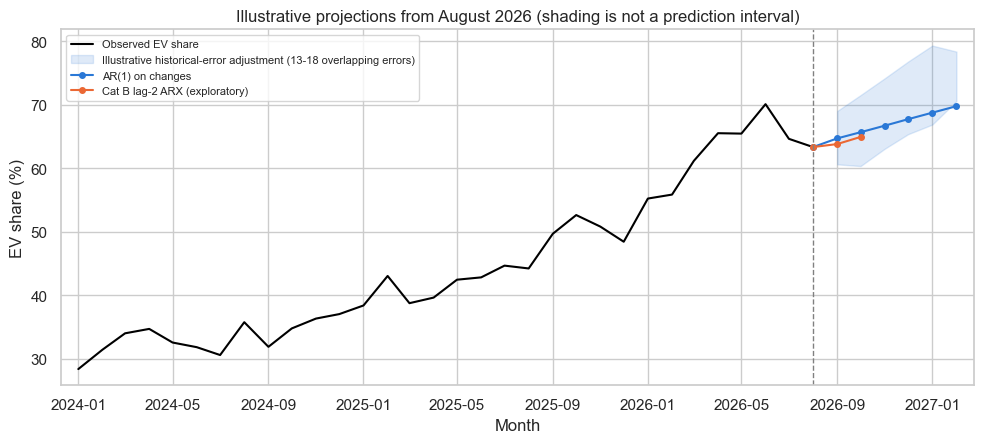

The ARX stops in October 2026: November would need the September premium, which is outside the study window.


In [51]:
# D: Illustrative projections from August 2026 and historical forecast errors by horizon.
forecast_origin = forecast_data.index[-1]
assert forecast_origin == FORECAST_END
forecast_proj_months = pd.date_range(forecast_origin + pd.offsets.MonthBegin(1), periods=6, freq="MS")
forecast_ar_b = forecast_ols(forecast_model_data[["d_ev_share_lag1"]], forecast_model_data["dy"])[0]
forecast_level, forecast_change = float(forecast_data["ev_share"].iloc[-1]), float(forecast_data["ev_share"].diff().iloc[-1])
forecast_ar_proj = []
for _ in forecast_proj_months:
    forecast_change = forecast_ar_b[0] + forecast_ar_b[1] * forecast_change
    forecast_level += forecast_change
    forecast_ar_proj.append(forecast_level)
forecast_ar_proj = pd.Series(forecast_ar_proj, index=forecast_proj_months)

# Cat B lag-2 ARX: only possible while the needed premium change (two months back) is inside the study window.
forecast_db = forecast_data["prem_b"].diff()
forecast_level, forecast_change = float(forecast_data["ev_share"].iloc[-1]), float(forecast_data["ev_share"].diff().iloc[-1])
forecast_arx_proj = {}
for m in forecast_proj_months:
    need = m - pd.offsets.MonthBegin(2)
    if need > forecast_origin:
        break
    forecast_change = forecast_beta[0] + forecast_beta[1] * forecast_change + forecast_beta[2] * forecast_db.loc[need]
    forecast_level += forecast_change
    forecast_arx_proj[m] = forecast_level
forecast_arx_proj = pd.Series(forecast_arx_proj)

# Backtest: from each of the 18 origins Feb 2025 - Jul 2026, refit AR(1) and project 1-6 months, as above.
forecast_bt = []
for month in forecast_test_idx:
    origin = month - pd.offsets.MonthBegin(1)
    train = forecast_model_data.loc[forecast_model_data.index <= origin]
    b = forecast_ols(train[["d_ev_share_lag1"]], train["dy"])[0]
    level, change = float(forecast_data.loc[origin, "ev_share"]), float(forecast_data["ev_share"].diff().loc[origin])
    for h in range(1, 7):
        change = b[0] + b[1] * change
        level += change
        target = origin + pd.offsets.MonthBegin(h)
        if target > forecast_origin:
            break
        forecast_bt.append({"origin": origin, "horizon": h, "forecast": level, "actual": float(forecast_data.loc[target, "ev_share"])})
forecast_bt = pd.DataFrame(forecast_bt)
forecast_bt["error"] = forecast_bt["forecast"] - forecast_bt["actual"]
np.testing.assert_allclose(forecast_bt.query("horizon == 1")["forecast"], get_forecast_predictions("AR(1) on changes"), atol=1e-9)
forecast_ar_rmse = forecast_rmse(get_forecast_predictions("AR(1) on changes"))
forecast_bt["normal_formula_half_width"] = 1.28 * forecast_ar_rmse * np.sqrt(forecast_bt["horizon"])
forecast_cal = forecast_bt.groupby("horizon").agg(
    errors=("error", "size"), RMSE=("error", lambda e: np.sqrt(np.mean(e**2))), mean_error=("error", "mean"),
    under_predictions=("error", lambda e: int((e < 0).sum())),
    heuristic_half_width_pp=("normal_formula_half_width", "first"),
    error_10th=("error", lambda e: np.quantile(e, 0.10)), error_90th=("error", lambda e: np.quantile(e, 0.90)))
forecast_cal["retrospective_heuristic_coverage"] = [np.mean(np.abs(g["error"]) <= g["normal_formula_half_width"]) for _, g in forecast_bt.groupby("horizon")]
display(forecast_cal.round(3))

forecast_proj = pd.DataFrame({"AR(1) projection (%)": forecast_ar_proj,
                          "historical-error adjustment low (%)": forecast_ar_proj - forecast_cal["error_90th"].to_numpy(),
                          "historical-error adjustment high (%)": forecast_ar_proj - forecast_cal["error_10th"].to_numpy(),
                          "Cat B lag-2 ARX projection (%)": forecast_arx_proj})
forecast_proj.index.name = "month"
display(forecast_proj.round(2))

fig, ax = plt.subplots(figsize=(10, 4.6))
hist = forecast_data["ev_share"].loc["2024-01":]
ax.plot(hist.index, hist, color="black", label="Observed EV share")
ax.fill_between(forecast_proj.index, forecast_proj["historical-error adjustment low (%)"], forecast_proj["historical-error adjustment high (%)"], color="#2a78d6",
                alpha=0.15, label="Illustrative historical-error adjustment (13-18 overlapping errors)")
ax.plot([forecast_origin] + list(forecast_ar_proj.index), [hist.iloc[-1]] + list(forecast_ar_proj), color="#2a78d6", marker="o", markersize=4,
        label="AR(1) on changes")
ax.plot([forecast_origin] + list(forecast_arx_proj.index), [hist.iloc[-1]] + list(forecast_arx_proj), color="#eb6834", marker="o", markersize=4,
        label="Cat B lag-2 ARX (exploratory)")
ax.axvline(forecast_origin, color="grey", linestyle="--", linewidth=1)
ax.set(title="Illustrative projections from August 2026 (shading is not a prediction interval)", ylabel="EV share (%)", xlabel="Month")
ax.legend(loc="upper left", fontsize=8)
ax.margins(x=0.02)
fig.tight_layout()
plt.show()
print("The ARX stops in October 2026: November would need the September premium, which is outside the study window.")

**Result.** From the August 2026 cutoff, AR(1) on changes projects EV share of 64.68% in September 2026 and 69.75% in February 2027. The exploratory Category B lag-two ARX projects 63.79% in September and 64.91% in October; it stops because further predictions would require premium observations beyond the cutoff.

Historical underprediction is more pronounced at longer horizons: at one month, 9 of 18 forecasts are below the outcome, with mean error −0.244 pp; at six months, 12 of 13 are below, with mean error −5.460 pp. These are overlapping forecast errors from differing origin samples, not independent evidence that bias necessarily increases by this amount with horizon.

The illustrative historical-error adjustment for February 2027 is 70.55%–78.34%, above the 69.75% point projection because both relevant six-month error quantiles are negative. This indicates the direction of past misses, not a validated future probability range. The heuristic formula's historical coverage of approximately 78%–92% also does not validate an 80% interval. EV share fell from June to August 2026, further limiting extrapolation of earlier underprediction. Linear projections do not enforce the 0–100% bounds at any horizon; a short horizon does not guarantee reliability.


In [52]:
# D1: Summarise key numerical findings from the existing calculations.
forecast_key = pd.Series({
    "EV share Jul 2022 (%)": forecast_data["ev_share"].iloc[0],
    "EV share Aug 2026 (%)": forecast_data["ev_share"].iloc[-1],
    "Average monthly change, Jul 2022 - Aug 2026 (pp)": (forecast_data["ev_share"].iloc[-1] - forecast_data["ev_share"].iloc[0]) / (len(forecast_data) - 1),
    "Naive benchmark RMSE (pp)": FORECAST_NAIVE_RMSE,
    "Drift benchmark RMSE (pp)": FORECAST_DRIFT_RMSE,
    "Best level-target tree RMSE (pp)": forecast_tree_res.query("target == 'level'")["RMSE"].min(),
    "Best change-target tree RMSE (pp)": forecast_tree_res.query("target == 'change'")["RMSE"].min(),
    "AR(1) on changes RMSE (pp)": forecast_rmse(get_forecast_predictions("AR(1) on changes")),
    "Cat B lag-2 ARX, hindsight RMSE (pp)": forecast_rmse(get_forecast_predictions("ARX: Cat B lag 2 (chosen with hindsight)")),
    "ARX, lag chosen each month by AIC RMSE (pp)": forecast_rmse(get_forecast_predictions("ARX: lag chosen each month by AIC")),
    "Smallest Diebold-Mariano p": forecast_dm_table["p"].min(),
    "Cat B lag-2 coefficient (pp per S$1,000)": forecast_beta[2],
    "Section 20A conditional evaluation: lowest non-benchmark RMSE (pp)": forecast_fixed_origin_table.loc[~forecast_fixed_origin_table["model"].str.startswith("Benchmark"), "RMSE_pp"].min(),
    "Section 20A conditional evaluation: last training value RMSE (pp)": forecast_fixed_origin_last_value_rmse,
    "AR(1) projection Sep 2026 (%)": forecast_ar_proj.iloc[0],
    "AR(1) projection Feb 2027 (%)": forecast_ar_proj.iloc[-1],
})
display(forecast_key.round(3).to_frame("value"))

,value
EV share Jul 2022 (%),11.744
EV share Aug 2026 (%),63.311
"Average monthly change, Jul 2022 - Aug 2026 (pp)",1.052
Naive benchmark RMSE (pp),3.537
Drift benchmark RMSE (pp),3.400
Best level-target tree RMSE (pp),4.694
Best change-target tree RMSE (pp),2.983
AR(1) on changes RMSE (pp),3.400
"Cat B lag-2 ARX, hindsight RMSE (pp)",3.096
"ARX, lag chosen each month by AIC RMSE (pp)",3.319
